# Evaluación Parcial N°3 — Machine Learning
## Caso C: Inteligencia musical y predicción de popularidad de canciones

### Integrantes
- Joaquin Muñoz
- Carlos Acevedo
- Jean Bizama

## Introducción

Las plataformas de streaming reciben miles de canciones nuevas cada día y los sellos
discográficos deben decidir, con presupuesto limitado, cuáles impulsar. Hoy esa decisión
se apoya sobre todo en criterio editorial. Este proyecto evalúa si un modelo de Machine
Learning puede aportar un filtro cuantitativo previo, estimando la **popularidad** de una
canción de Spotify a partir de sus características musicales y su género.

Este informe corresponde a la **tercera entrega** (Evaluación Parcial N°3) y continúa el
trabajo de las anteriores: la EP1 cubrió la comprensión del negocio, la exploración de los
datos y su limpieza, y la EP2 construyó y evaluó los primeros modelos.

Aquí se completa el ciclo: se construyen **dos modelos supervisados de regresión**, se
optimizan sus hiperparámetros y se comparan con **técnicas de ensamble** (Random Forest,
*voting* y *stacking*), y se aplica **una técnica no supervisada** (clustering) para
descubrir segmentos dentro del catálogo. Luego se evalúa la capacidad de generalización, se
selecciona la solución óptima con métricas apropiadas y se traduce en recomendaciones para
el negocio.

Como este es un informe independiente, se retoma lo esencial de la EP1 y se resumen sus
hallazgos, que condicionan todas las decisiones posteriores:

| Hallazgo de la EP1 | Consecuencia para esta entrega |
|---|---|
| 114.000 filas, pero solo 88.732 canciones distintas: una misma canción aparece en varios géneros | Se trabaja con una fila por canción (track_id) |
| Hay 6.666 canciones con el mismo nombre, artista y duración pero distinto track_id | La validación se hace por grupos (id_contenido) para evitar fuga de datos |
| popularity = 0 se concentra en ciertos géneros: es dato faltante, no impopularidad | Esas 9.313 canciones se excluyen del modelado y se declara como limitación |
| Ninguna característica de audio supera \|r\| = 0,10 con la popularidad; el género explica ~25% de la varianza (cifras de la EP1, calculadas con los ceros incluidos; al excluirlos como dato faltante el género explica ~44%, sección 2.2) | Se espera que el género pese más que el audio y se mide de forma explícita |
| Predecir la media del género da un MAE de ~9,76 (vs. 15,15 con la media global) | Es la línea base que cualquier modelo debe superar |

### Estructura del informe

| Sección | Contenido |
|---|---|
| 1 | Problema de negocio, objetivos, KPIs, fuentes de datos, herramientas y metodología |
| 2 | Análisis exploratorio de los datos |
| 3 | Preparación y transformación de los datos |
| 4 | Modelos supervisados (regresión) |
| 5 | Modelo no supervisado (clustering) |
| 6 | Evaluación y comparación de resultados |
| 7 | Sesgos, ética y privacidad |
| 8 | Conclusiones y recomendaciones |

# Importacion de librerias y configuracion

In [3]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42   # semilla única para que todos los resultados sean reproducibles

RAIZ = Path.cwd().parent if Path.cwd().name in ("notebook", "notebooks") else Path.cwd()
DATA = RAIZ / "data"
IMG = RAIZ / "images"
MODELS = RAIZ / "models"
for carpeta in (DATA, IMG, MODELS):
    carpeta.mkdir(exist_ok=True)

## 1. Problema de negocio, objetivos y KPIs

### 1.1 Descripción del problema de negocio

En la industria musical se publica diariamente una gran cantidad de canciones en las
plataformas de streaming, pero no todas alcanzan el mismo nivel de popularidad. Los
sellos discográficos y las plataformas deben decidir con presupuesto limitado qué
canciones de su catálogo impulsar mediante listas editoriales y campañas de promoción,
y hoy esa selección se apoya principalmente en criterio editorial, sin un filtro
cuantitativo previo.

El problema de negocio es de **priorización**: identificar anticipadamente, entre miles
de canciones, cuáles presentan características asociadas a un potencial de popularidad
superior al esperable dentro de su género.

Se plantea desde dos ángulos complementarios:

- **Predictivo (aprendizaje supervisado):** estimar cuántos puntos de popularidad
  (0 a 100) alcanzaría una canción, para ordenar el catálogo y decidir dónde invertir.
- **Descriptivo (aprendizaje no supervisado):** descubrir segmentos naturales de canciones
  según su perfil sonoro, para que el negocio defina estrategias distintas por tipo
  de repertorio en lugar de tratar todo el catálogo como uno solo.

### 1.2 Objetivos del proyecto

**Objetivo general**

Desarrollar y comparar modelos de Machine Learning supervisados y no supervisados que
estimen la popularidad de canciones de Spotify y revelen segmentos del catálogo, a
partir de sus características musicales y su género, para apoyar decisiones de
priorización.

**Objetivos específicos**

- Resumir la comprensión y calidad de los datos heredadas de la EP1 y verificar que el
  conjunto preparado sea consistente.
- Preparar los datos para el modelamiento, evitando la fuga de información entre
  entrenamiento y prueba.
- Construir y comparar **dos modelos supervisados de regresión**, justificando la
  elección del algoritmo y su configuración.
- **Optimizar los hiperparámetros** de los modelos con validación cruzada y comparar
  **técnicas de ensamble** (*bagging*, *boosting*, *voting* y *stacking*) para medir si
  mejoran el resultado.
- **Evaluar la capacidad de generalización** (brecha entre entrenamiento y validación,
  estabilidad entre pliegues y curva de aprendizaje) y **seleccionar y justificar la
  solución óptima** mediante la comparación de modelos.
- Aplicar **una técnica no supervisada** para identificar segmentos de canciones e
  interpretar su relación con la popularidad y el género.
- Evaluar los modelos con métricas apropiadas, **por género y no solo en promedio**, y
  contrastarlos con la línea base.
- Traducir los resultados en recomendaciones de negocio, indicando también los límites
  de uso de la solución.

### 1.3 KPIs

La variable popularity es el indicador central del proyecto. Se mantienen los KPIs
definidos en la EP1, para poder evaluar si el modelamiento cumplió lo comprometido:

| KPI | Definición | Cómo se mide | Meta |
|---|---|---|---|
| Precisión en priorización | % de canciones que el modelo ubica en el 10% superior de su género y que efectivamente lo están | Precision@10% por género | ≥ 40% |
| Reducción del error de estimación | Baja del error promedio respecto de predecir el promedio del género | MAE del modelo vs. MAE de la línea base | ≥ 20% de mejora |
| Cobertura confiable del catálogo | % de canciones de prueba para las que la predicción es confiable: las de géneros donde el modelo supera a la línea base y su MAE es de 10 puntos o menos | Canciones de prueba en géneros confiables / canciones de prueba | ≥ 85% |
| Equidad entre géneros | Diferencia de error entre el género mejor y peor estimado | MAE máximo − MAE mínimo por género | ≤ 8 puntos |

Además de los KPIs de negocio, se usarán métricas técnicas para comparar los modelos:

| Tipo de modelo | Métricas técnicas |
|---|---|
| Supervisado (regresión) | MAE, RMSE y R², calculados con validación cruzada agrupada |
| No supervisado (clustering) | Coeficiente de silueta, método del codo (inercia) y perfil de cada segmento |

### 1.4 Justificación de las metas

Las metas se derivan de líneas base calculadas sobre los propios datos, no de supuestos.
Predecir el promedio global del catálogo da un error medio de unos 15 puntos; predecir
el promedio del género correspondiente lo reduce a unos 9,8, una mejora cercana al 35%
sin usar ninguna característica de audio. Esa es la línea base real que cualquier modelo
debe superar, y por eso el KPI de reducción del error se fija sobre ella y no sobre la
media global (la sección 1.8 calcula ambas cifras).

El KPI de equidad responde a un hallazgo de la exploración: los datos faltantes de
popularidad se concentran en géneros específicos, por lo que un modelo podría funcionar
bien en promedio y ser inservible para jazz o música latina. Un indicador agregado
ocultaría ese problema, por eso el error se reporta por género.

Las metas **no se modifican después de ver los resultados**: la sección 6 informa con
honestidad cuáles se cumplieron y cuáles no, y explica las causas.

**Cobertura: definición corregida.** Una primera versión de este KPI medía «canciones modelables / canciones únicas» (89,5%). Esa cifra depende solo de haber excluido las canciones con popularity = 0 y no del modelo: se habría cumplido incluso con un modelo que predijera puros ceros, así que no medía nada del modelo. Por eso se redefine como el porcentaje de canciones de prueba con una predicción **confiable** (género donde el modelo supera a la línea base y tiene MAE ≤ 10, cerca del error promedio de la línea base). La meta de 85% no cambia; el 89,5% se conserva solo como dato de contexto (sección 1.8).

### 1.5 Fuentes de datos

El proyecto usa el *Spotify Tracks Dataset* (CSV), construido a partir de la API de
Spotify, y dos archivos derivados que se generaron en la EP1:

| Archivo | Filas × columnas | Descripción |
|---|---|---|
| Spotify_Tracks_Dataset.csv | 114.000 × 21 | Dataset original: 114 géneros, 1.000 canciones por género. Una canción puede repetirse en varios géneros |
| spotify_modelable.csv | 79.419 × 27 | Una fila por canción, con popularity > 0, valores imposibles eliminados y variables derivadas. Es el insumo del modelamiento |
| spotify_excluidas_pop0.csv | 9.313 × 22 | Canciones con popularity = 0, tratadas como dato faltante y excluidas del entrenamiento |

Variables principales del conjunto modelable:

| Grupo | Columnas |
|---|---|
| Variable objetivo | popularity (índice de 0 a 100 calculado por Spotify) |
| Características de audio | danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo |
| Características de la pista | duration_ms, key, mode, time_signature, explicit |
| Género | generos (todas las etiquetas), n_generos, genero_principal (el más específico) |
| Derivadas | duration_min, duration_log, es_instrumental, es_vivo |
| Control de fuga de datos | id_contenido (agrupa copias de una misma canción con distinto track_id) |

Significado de las características de la pista (según la documentación de la API de Spotify):

| Columna | Qué es | Valores en el conjunto modelable |
|---|---|---|
| key | Nota fundamental estimada (0 = Do, 1 = Do♯, …, 11 = Si). Es una categoría: no tiene orden numérico real | 0 a 11 |
| mode | Modalidad de la escala: 1 = mayor, 0 = menor | 0 y 1 |
| time_signature | **Compás estimado**: cuántos pulsos hay en cada compás, entre 3 y 7 (de 3/4 a 7/4). El 4 es el compás 4/4, el más habitual | 3, 4 y 5 (cerca de 90% es 4). En la EP1 se eliminaron los valores 0 y 1 por imposibles |
| explicit | 1 si la canción tiene letra explícita | 0 y 1 |

Las definiciones de las características de audio provienen de la documentación oficial
de la API de Spotify.

### 1.6 Herramientas utilizadas

| Herramienta | Uso en el proyecto |
|---|---|
| Python 3 | Lenguaje base del análisis |
| pandas / numpy | Manipulación, limpieza y transformación de datos |
| matplotlib / seaborn | Visualización de la exploración y de los resultados |
| scikit-learn | Modelos supervisados, clustering, validación cruzada y métricas |
| joblib | Guardado del modelo entrenado en "models/" |
| Git / GitHub | Control de versiones y trabajo colaborativo del equipo |

### 1.7 Metodología: CRISP-DM

El proyecto sigue la metodología **CRISP-DM** (*Cross-Industry Standard Process for Data
Mining*), que organiza el trabajo en fases iterativas. La EP1 cubrió las tres primeras
y esta entrega las completa:

| Fase CRISP-DM | Qué se hace en este proyecto | Sección |
|---|---|---|
| 1. Comprensión del negocio | Problema de priorización, objetivos y KPIs con metas numéricas | 1 |
| 2. Comprensión de los datos | Calidad, duplicados, ceros en popularity, valores atípicos y relación con la variable objetivo | 2 |
| 3. Preparación de los datos | Una fila por canción, selección y transformación de variables, partición agrupada | 3 |
| 4. Modelado | Dos modelos supervisados de regresión, optimización de hiperparámetros, técnicas de ensamble y un modelo no supervisado (clustering) | 4 y 5 |
| 5. Evaluación | Generalización y selección de la solución final; métricas técnicas y KPIs de negocio, también por género; límites de la solución | 4.11, 4.12, 6 y 7 |
| 6. Despliegue | Modelo guardado, recomendaciones de uso y trabajo futuro | 8 |

### 1.8 Verificación de los insumos y línea base

Antes de avanzar, se comprueba que los tres archivos existan en "data/", que sus
dimensiones coincidan con lo documentado en la EP1 y que la línea base de los KPIs
se reproduzca con los datos actuales.

In [4]:
archivos = {
    "original":   DATA / "Spotify_Tracks_Dataset.csv",
    "modelable":  DATA / "spotify_modelable.csv",
    "excluidas":  DATA / "spotify_excluidas_pop0.csv",
}
faltantes = [str(ruta) for ruta in archivos.values() if not ruta.exists()]
if faltantes:
    raise FileNotFoundError(f"Faltan archivos en data/: {faltantes}")

original  = pd.read_csv(archivos["original"])
modelable = pd.read_csv(archivos["modelable"])
excluidas = pd.read_csv(archivos["excluidas"])

print(f"Original:  {original.shape[0]:>7,} filas x {original.shape[1]} columnas")
print(f"Modelable: {modelable.shape[0]:>7,} filas x {modelable.shape[1]} columnas")
print(f"Excluidas: {excluidas.shape[0]:>7,} filas x {excluidas.shape[1]} columnas")

Original:  114,000 filas x 21 columnas
Modelable:  79,419 filas x 27 columnas
Excluidas:   9,313 filas x 22 columnas


In [5]:
# Comprobaciones de consistencia con lo documentado en la EP1
canciones_unicas = len(modelable) + len(excluidas)

assert modelable["track_id"].is_unique, "modelable tiene track_id repetidos"
assert excluidas["track_id"].is_unique, "excluidas tiene track_id repetidos"
assert not set(modelable["track_id"]) & set(excluidas["track_id"]), "hay canciones en ambos archivos"
assert modelable["popularity"].between(1, 100).all(), "popularity fuera de rango en modelable"
assert (excluidas["popularity"] == 0).all(), "excluidas debe tener solo popularity = 0"
assert modelable.isna().sum().sum() == 0, "modelable tiene nulos"
assert "id_contenido" in modelable.columns, "falta id_contenido (control de fuga de datos)"

print("Todas las comprobaciones pasaron.")
print(f"Canciones únicas del catálogo: {canciones_unicas:,}")
print(f"Canciones con id_contenido repetido (posibles copias): "
      f"{(modelable['id_contenido'].map(modelable['id_contenido'].value_counts()) > 1).sum():,}")

Todas las comprobaciones pasaron.
Canciones únicas del catálogo: 88,732
Canciones con id_contenido repetido (posibles copias): 4,084


In [6]:
# Línea base de los KPIs (se recalculará con validación cruzada en la sección 4)
y = modelable["popularity"]

mae_global = (y - y.mean()).abs().mean()
media_genero = modelable.groupby("genero_principal")["popularity"].transform("mean")
mae_genero = (y - media_genero).abs().mean()
cobertura_datos = len(modelable) / canciones_unicas   # dato de contexto: NO es el KPI de cobertura (se mide en 6.5)

print(f"MAE prediciendo la media global:     {mae_global:.2f}")
print(f"MAE prediciendo la media del género: {mae_genero:.2f}")
print(f"Mejora de la media del género sobre la global: {(1 - mae_genero / mae_global) * 100:.1f}%")
print()
print(f"Meta del KPI de reducción de error: MAE <= {mae_genero * 0.8:.2f} (20% menos que la línea base)")
print(f"Canciones modelables sobre las únicas del catálogo: {cobertura_datos:.1%}  (dato de contexto; el KPI de cobertura se mide en la sección 6.5)")

MAE prediciendo la media global:     15.15
MAE prediciendo la media del género: 9.76
Mejora de la media del género sobre la global: 35.6%

Meta del KPI de reducción de error: MAE <= 7.80 (20% menos que la línea base)
Canciones modelables sobre las únicas del catálogo: 89.5%  (dato de contexto; el KPI de cobertura se mide en la sección 6.5)


La línea base se reproduce con los datos actuales: predecir la media global da un error de
unos 15,1 puntos y predecir la media del género lo baja a unos 9,8, sin usar ninguna
característica de audio. Para cumplir el KPI de reducción de error, un modelo debería
bajar de 9,8 a unos **7,8 puntos de MAE**. Además, el **89,5%** de las canciones únicas es modelable (solo se excluyen las popularity = 0); es un dato de contexto y no el KPI de cobertura, que se mide sobre las canciones donde el modelo es confiable (sección 6.5).

Esta línea base se calculó sobre todos los datos; en la sección 4 se recalculará con
validación cruzada, para comparar a los modelos y a la línea base en igualdad de condiciones.

## 2. Análisis exploratorio de los datos (EDA)

La EP1 hizo la exploración sobre los 114.000 registros originales. Aquí se repite sobre el conjunto **modelable** (79.419 canciones, una por track_id, sin popularity = 0), porque es el que realmente alimenta a los modelos. El objetivo no es repetir gráficos, sino responder tres preguntas que deciden el modelamiento:

1. ¿Cómo se distribuye la variable objetivo y qué error es "esperable"?
2. ¿Cuánto explican el género y el audio, y qué relación tienen con la popularidad (lineal o no)?
3. ¿Qué problemas de los datos pueden afectar a los modelos (desbalance de géneros, colinealidad, valores bajos sospechosos)?

In [7]:
# Variables de trabajo
AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo"]
OTRAS = ["duration_log", "explicit", "mode", "key", "time_signature", "n_generos",
         "es_instrumental", "es_vivo"]
df = modelable.copy()

print(f"Canciones: {len(df):,} | géneros: {df['genero_principal'].nunique()} | "
      f"id_contenido distintos: {df['id_contenido'].nunique():,}")
df["popularity"].describe().round(2)

Canciones: 79,419 | géneros: 113 | id_contenido distintos: 77,170


,popularity
count,79419.00
mean,37.14
std,18.15
min,1.00
25%,22.00
50%,37.00
75%,50.00
max,100.00


### 2.1 Distribucion variable objetivo

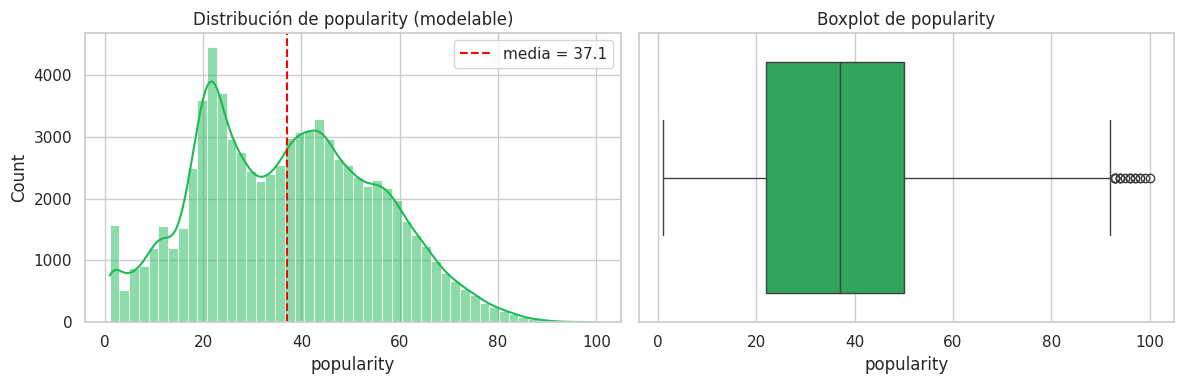

Asimetría: 0.18 | desviación estándar: 18.1


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["popularity"], bins=50, kde=True, ax=ax[0], color="#1DB954")
ax[0].axvline(df["popularity"].mean(), color="red", ls="--", label=f"media = {df['popularity'].mean():.1f}")
ax[0].set_title("Distribución de popularity (modelable)"); ax[0].legend()
sns.boxplot(x=df["popularity"], ax=ax[1], color="#1DB954")
ax[1].set_title("Boxplot de popularity")
plt.tight_layout(); plt.savefig(IMG / "eda_01_popularity.png", dpi=120); plt.show()
print(f"Asimetría: {df['popularity'].skew():.2f} | desviación estándar: {df['popularity'].std():.1f}")

La distribución es amplia (desviación estándar de unos 18 puntos) y casi simétrica, sin una cola extrema que obligue a transformar la variable objetivo. Por eso se modela popularity directamente y se usan **MAE** (error típico en puntos, fácil de explicar al negocio) y **RMSE** (castiga más los errores grandes). Se nota además un pico de canciones con valores muy bajos (1 y 2), que se estudia en el punto 2.5.

### 2.2 El género como variable dominante

Varianza de popularity explicada por el género (sin ceros): 44.5%
(En la EP1, con los ceros incluidos, era ~25%: al excluir el dato faltante, el género pesa aún más.)


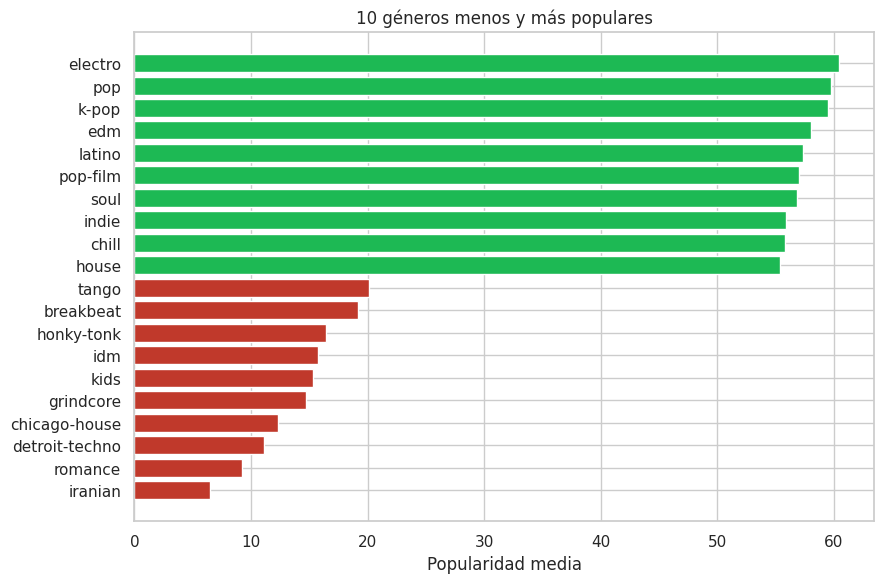

In [9]:
def varianza_explicada(frame, grupo):
    media_grupo = frame.groupby(grupo)["popularity"].transform("mean")
    return 1 - ((frame["popularity"] - media_grupo) ** 2).sum() / ((frame["popularity"] - frame["popularity"].mean()) ** 2).sum()

eta_genero = varianza_explicada(df, "genero_principal")
print(f"Varianza de popularity explicada por el género (sin ceros): {eta_genero:.1%}")
print("(En la EP1, con los ceros incluidos, era ~25%: al excluir el dato faltante, el género pesa aún más.)")

por_genero = (df.groupby("genero_principal")["popularity"]
                .agg(media="mean", desv="std", n="count").sort_values("media"))
extremos = pd.concat([por_genero.head(10), por_genero.tail(10)])
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(extremos.index, extremos["media"], color=["#c0392b"] * 10 + ["#1DB954"] * 10)
ax.set_xlabel("Popularidad media"); ax.set_title("10 géneros menos y más populares")
plt.tight_layout(); plt.savefig(IMG / "eda_02_genero.png", dpi=120); plt.show()

El género explica cerca de la mitad de la varianza (la EP1 reportó ~25% porque incluía los ceros, que son dato faltante y no popularidad real): conocer el género de una canción es, por sí solo, más informativo que todas sus características de audio juntas. Esto tiene dos consecuencias para el modelamiento: el género **debe** entrar como variable del modelo, y la segunda consecuencia es que la línea base "predecir la media del género" es exigente y es contra la que hay que compararse.

### 2.3 Caracteristicas de audio y su relacion con popularidad

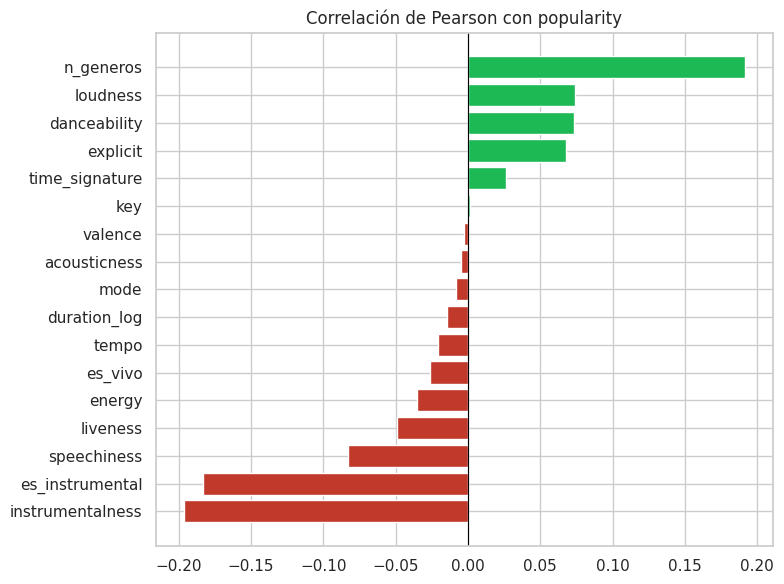

instrumentalness   -0.196
es_instrumental    -0.183
speechiness        -0.083
liveness           -0.049
energy             -0.036
es_vivo            -0.026
tempo              -0.020
duration_log       -0.015
mode               -0.008
acousticness       -0.005
valence            -0.003
key                 0.001
time_signature      0.027
explicit            0.067
danceability        0.073
loudness            0.074
n_generos           0.192


In [10]:
corr = df[AUDIO + OTRAS].corrwith(df["popularity"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr.index, corr.values, color=["#c0392b" if v < 0 else "#1DB954" for v in corr.values])
ax.axvline(0, color="black", lw=0.8); ax.set_title("Correlación de Pearson con popularity")
plt.tight_layout(); plt.savefig(IMG / "eda_03_correlaciones.png", dpi=120); plt.show()
print(corr.round(3).to_string())

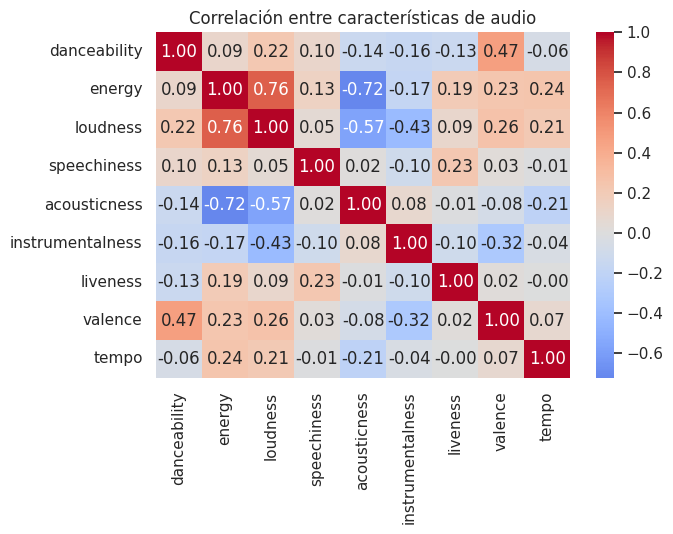

In [11]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[AUDIO].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación entre características de audio")
plt.tight_layout(); plt.savefig(IMG / "eda_04_colinealidad.png", dpi=120); plt.show()

Las correlaciones individuales con la popularidad son débiles. La más fuerte entre las de audio es instrumentalness (negativa, cercana a -0,20): la música instrumental tiende a ser menos popular. n_generos (en cuántos géneros aparece una canción) también destaca, con correlación positiva cercana a 0,19. Entre las propias características de audio hay **colinealidad** (energy con loudness ≈ 0,76 y con acousticness ≈ -0,72), lo que importa para modelos lineales: obliga a regularizar (Ridge) y a no interpretar sus coeficientes de forma aislada.

### 2.4 Variables binarias y de la pista

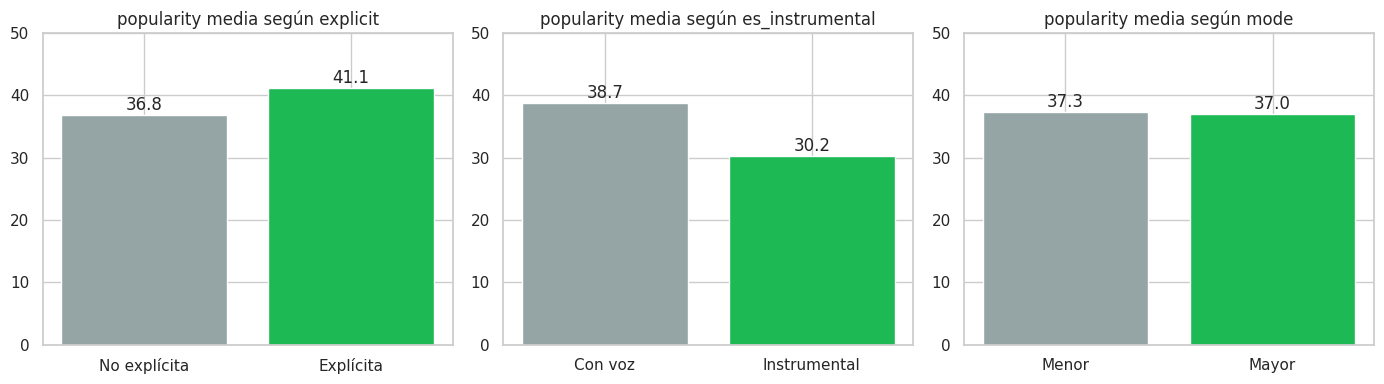

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, etiquetas in zip(ax, ["explicit", "es_instrumental", "mode"],
                             [["No explícita", "Explícita"], ["Con voz", "Instrumental"], ["Menor", "Mayor"]]):
    medias = df.groupby(col)["popularity"].mean()
    a.bar(etiquetas, medias.values, color=["#95a5a6", "#1DB954"])
    a.set_title(f"popularity media según {col}"); a.set_ylim(0, 50)
    for i, v in enumerate(medias.values):
        a.text(i, v + 0.8, f"{v:.1f}", ha="center")
plt.tight_layout(); plt.savefig(IMG / "eda_05_binarias.png", dpi=120); plt.show()

Las canciones instrumentales promedian unos 8 puntos menos que las que tienen voz, y las explícitas unos 4 más que las no explícitas. Son efectos reales pero modestos frente al del género.

### 2.5 Hallazgo: concentración de valores muy bajos (1 y 2) en ciertos géneros

En la EP1 el valor 0 resultó ser dato faltante porque se concentraba en géneros específicos. Se aplica el mismo test a los valores 1 y 2, que forman un pico visible en el histograma.

Porcentaje global de canciones con popularity <= 2: 2.0%


,n,pct_pop_1_2,media,desv
genero_principal,,,,
latin,299,53%,24.7,32.8
rock,138,33%,42.0,37.8
dance,494,28%,45.4,37.1
alternative,97,27%,37.4,32.0
country,358,25%,40.4,27.6
iranian,333,23%,6.5,4.9
reggae,167,20%,39.3,28.4
romance,335,15%,9.2,7.7


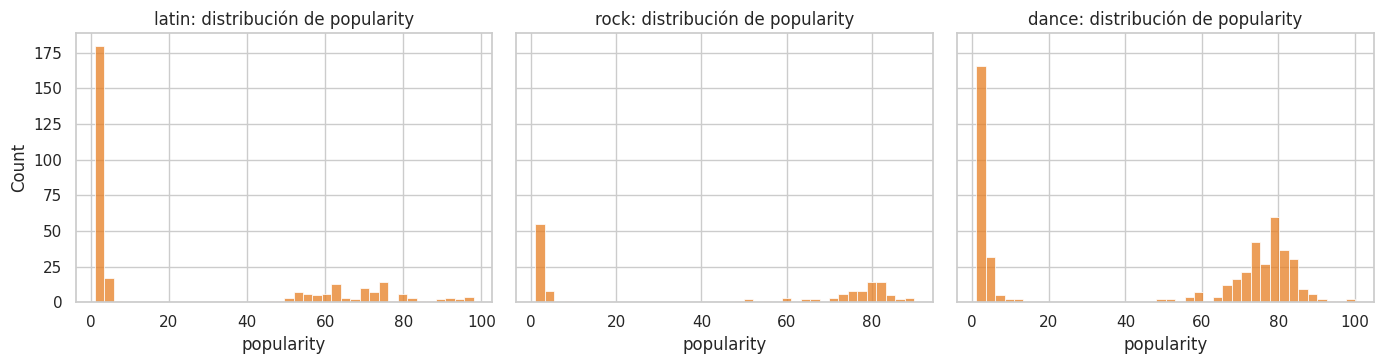

In [13]:
df["pop_baja"] = df["popularity"] <= 2
tabla = (df.groupby("genero_principal")
           .agg(n=("pop_baja", "size"), pct_pop_1_2=("pop_baja", "mean"),
                media=("popularity", "mean"), desv=("popularity", "std"))
           .sort_values("pct_pop_1_2", ascending=False))
print(f"Porcentaje global de canciones con popularity <= 2: {df['pop_baja'].mean():.1%}")
display(tabla.head(8).style.format({"pct_pop_1_2": "{:.0%}", "media": "{:.1f}", "desv": "{:.1f}"}))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, g in zip(ax, ["latin", "rock", "dance"]):
    sns.histplot(df.loc[df["genero_principal"] == g, "popularity"], bins=40, ax=a, color="#e67e22")
    a.set_title(f"{g}: distribución de popularity")
plt.tight_layout(); plt.savefig(IMG / "eda_06_bimodal.png", dpi=120); plt.show()

En latin (53%), rock (33%) y dance (28%) las canciones con popularidad 1 o 2 forman un grupo aparte, con otro grupo de popularidad alta; el resultado es una distribución **bimodal** (dos picos) dentro del mismo género. Dos lecturas posibles, que no se pueden distinguir con estos datos: que sean canciones realmente poco escuchadas o que sean registros incompletos de la API, como los ceros. Por eso **no se eliminan**, pero se declara como limitación: en esos géneros el error será alto no porque el modelo sea malo, sino porque el valor a predecir es poco predecible.

### 2.6 Cobertura de géneros
Para evitar sesgo contra los géneros con pocas canciones, cada partición de entrenamiento y prueba debe contener **todos los géneros**. Se revisa cuántas canciones tiene cada uno.

Géneros: 113 | mínimo: 71 (reggaeton) | mediana: 791 | máximo: 992 (heavy-metal)


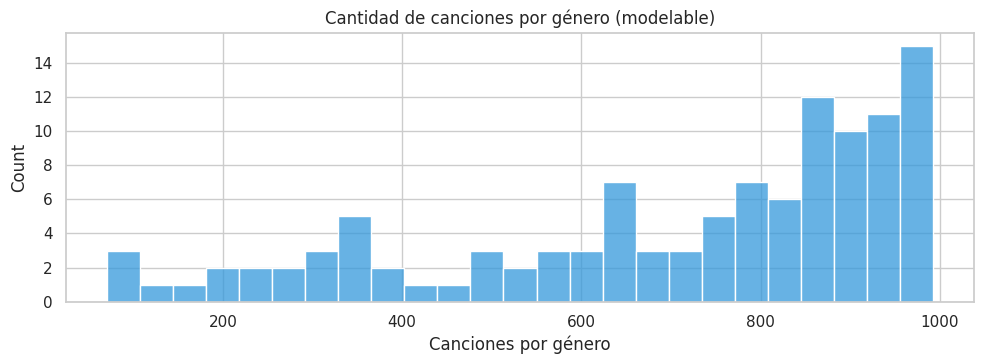

Géneros en el original: 114 | géneros principales en el modelable: 113
Géneros que no son principal de ninguna canción: ['songwriter']


In [14]:
n_por_genero = df["genero_principal"].value_counts()
print(f"Géneros: {len(n_por_genero)} | mínimo: {n_por_genero.min()} ({n_por_genero.idxmin()}) | "
      f"mediana: {n_por_genero.median():.0f} | máximo: {n_por_genero.max()} ({n_por_genero.idxmax()})")

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.histplot(n_por_genero, bins=25, ax=ax, color="#3498db")
ax.set_xlabel("Canciones por género"); ax.set_title("Cantidad de canciones por género (modelable)")
plt.tight_layout(); plt.savefig(IMG / "eda_07_cobertura.png", dpi=120); plt.show()

# El dataset original tenía 114 géneros
g_orig = set(original["track_genre"].unique())
sin_principal = g_orig - set(modelable["genero_principal"].unique())
print(f"Géneros en el original: {len(g_orig)} | géneros principales en el modelable: {modelable['genero_principal'].nunique()}")
print("Géneros que no son principal de ninguna canción:", sorted(sin_principal))

Ningún género tiene menos de 71 canciones, así que una partición estratificada por género es viable y deja todos los géneros representados en cada pliegue de prueba. El conjunto modelable tiene **113 géneros principales** frente a los 114 del dataset original: "songwriter" no queda como género principal de ninguna canción, porque todas las suyas también están catalogadas en otro género más específico (regla de asignación de la EP1). No se perdió por los ceros, y la limitación es que el modelo no estima ese género por separado.

### 2.7 Conclusiones del EDA y decisiones de modelamiento

| Hallazgo | Decisión |
|---|---|
| El género explica ~44% de la varianza; el audio, muy poco | El género entra como variable; la línea base es la media del género |
| Relaciones débiles y probablemente no lineales con el audio | Comparar un modelo **lineal** (Ridge) con uno **no lineal basado en árboles** (Gradient Boosting) |
| Colinealidad entre energy, loudness y acousticness | Estandarizar y regularizar en el modelo lineal |
| 113 géneros, algunos con pocas canciones | Partición **estratificada por género**, para que todos estén en entrenamiento y prueba |
| Copias de una misma canción con distinto track_id | Partición **agrupada** por id_contenido, para evitar fuga de datos |
| Bimodalidad en latin, rock, dance | No eliminar, pero reportar el error **por género** y declarar la limitación |
| Variable objetivo continua y casi simétrica | Regresión directa; métricas MAE, RMSE y R² |

## 3. Preparación y transformación de los datos

Cada decisión de esta sección responde a un hallazgo del EDA. El principio general es que **nada que dependa de los datos de prueba puede influir en el entrenamiento**: las transformaciones se ajustan solo con el conjunto de entrenamiento, dentro de *pipelines* de scikit-learn, y la partición respeta los dos riesgos detectados (canciones repetidas y géneros con pocas canciones).

### 3.1 Selección de variables

| Columna | Decisión | Motivo |
|---|---|---|
| popularity | **Variable objetivo** | Es lo que se quiere estimar |
| 9 características de audio, duration_log, explicit, mode, key, time_signature | **Se usan** | Describen la canción y están disponibles antes de su lanzamiento |
| genero_principal | **Se usa** | Explica ~44% de la varianza (sección 2.2) |
| id_contenido | Solo para agrupar la partición | Evita que copias de una misma canción queden en entrenamiento y prueba |
| track_id, track_name, album_name | Se descartan | Son identificadores o texto libre: no generalizan a canciones nuevas |
| artists | Se descarta | El modelo memorizaría la fama del artista y no podría estimar a artistas nuevos; además favorecería a los ya conocidos |
| generos | Se descarta | Texto con todas las etiquetas; ya se resume en `genero_principal |
| duration_ms, duration_min | Se descartan | Redundantes con duration_log |
| es_instrumental, es_vivo | Se descartan | Son umbrales de `instrumentalness y liveness, ya incluidas |
| n_generos | Se descarta del modelo principal | Es un artefacto de cómo se armó el dataset (en cuántas listas por género apareció la canción) y no se conoce para una canción nueva. Se mide su efecto aparte en la sección 4 |

In [15]:
TARGET = "popularity"
GRUPO = "id_contenido"
CATEGORICAS = ["genero_principal", "key"]          # key es una nota (0 a 11): no tiene orden numérico real
NUMERICAS = AUDIO + ["duration_log", "explicit", "mode", "time_signature"]
FEATURES = NUMERICAS + CATEGORICAS

X = df[FEATURES].copy()
y = df[TARGET].copy()
grupos = df[GRUPO].copy()

print(f"Variables numéricas ({len(NUMERICAS)}): {NUMERICAS}")
print(f"Variables categóricas ({len(CATEGORICAS)}): {CATEGORICAS}")
print(f"Matriz de entrada: {X.shape[0]:,} filas x {X.shape[1]} columnas | nulos: {int(X.isna().sum().sum())}")

Variables numéricas (13): ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_log', 'explicit', 'mode', 'time_signature']
Variables categóricas (2): ['genero_principal', 'key']
Matriz de entrada: 79,419 filas x 15 columnas | nulos: 0


### 3.2 Transformaciones (preprocesadores)

Los dos tipos de modelo necesitan la información en formatos distintos, por lo que se definen dos preprocesadores:

- **Modelo lineal (Ridge):** estandariza las numéricas (media 0, desviación 1), para que la penalización trate a todas por igual, y convierte genero_principal y key en columnas 0/1 (*one-hot*).
- **Modelo de árboles (Gradient Boosting):** no necesita escalar; las variables categóricas se codifican como números enteros y el modelo las trata como categorías, no como una escala.

Ambos se ajustan solo con los datos de entrenamiento, y una categoría que no aparezca en entrenamiento se maneja sin error.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

def preprocesador_lineal():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])

def preprocesador_arboles():
    return ColumnTransformer([
        ("num", "passthrough", NUMERICAS),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAS),
    ])

# Posición de las columnas categóricas tras la transformación (las numéricas van primero)
IDX_CATEGORICAS_ARBOLES = list(range(len(NUMERICAS), len(NUMERICAS) + len(CATEGORICAS)))
print("Columnas categóricas para el modelo de árboles:", IDX_CATEGORICAS_ARBOLES)

Columnas categóricas para el modelo de árboles: [13, 14]


### 3.3 Partición: entrenamiento, prueba y validación cruzada

Se aplican dos reglas a la vez:

1. **Agrupada por id_contenido:** todas las copias de una misma canción quedan juntas, de modo que el modelo nunca se evalúa con una canción que ya vio con otro identificador.
2. **Estratificada por género:** cada género aparece en entrenamiento y en prueba, para que el resultado no esconda un mal desempeño en los géneros pequeños.

Se separa un **20% de prueba** que no se toca hasta la evaluación final. Sobre el 80% restante se hace validación cruzada de 5 pliegues, con las mismas dos reglas, para comparar modelos y ajustar hiperparámetros.

In [17]:
from sklearn.model_selection import StratifiedGroupKFold

# 20% de prueba: primer pliegue de una partición en 5 (agrupada y estratificada)
separador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(separador.split(X, df["genero_principal"], groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

# Validación cruzada de 5 pliegues solo sobre el entrenamiento
cv_interno = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv_interno.split(X_train, X_train["genero_principal"], groups=g_train))

print(f"Entrenamiento: {len(X_train):,} canciones ({len(X_train)/len(X):.1%})")
print(f"Prueba:        {len(X_test):,} canciones ({len(X_test)/len(X):.1%})")
print(f"Pliegues de validación cruzada: {len(CV_SPLITS)}")

Entrenamiento: 63,531 canciones (80.0%)
Prueba:        15,888 canciones (20.0%)
Pliegues de validación cruzada: 5


### 3.4 Verificación de la partición

No basta con suponer que la partición quedó bien: se comprueba con pruebas automáticas que no hay fuga de datos y que todos los géneros están representados.

In [18]:
generos_todos = set(df["genero_principal"].unique())

# 1) Sin fuga: ninguna canción (id_contenido) está en entrenamiento y prueba a la vez
assert not set(g_train) & set(g_test), "hay canciones repetidas entre entrenamiento y prueba"
# 2) Todos los géneros en entrenamiento y en prueba
assert set(X_train["genero_principal"]) == generos_todos, "faltan géneros en entrenamiento"
assert set(X_test["genero_principal"]) == generos_todos, "faltan géneros en prueba"
# 3) Lo mismo en cada pliegue de validación cruzada
for k, (a, b) in enumerate(CV_SPLITS, start=1):
    assert not set(g_train.iloc[a]) & set(g_train.iloc[b]), f"fuga en el pliegue {k}"
    assert set(X_train.iloc[b]["genero_principal"]) == generos_todos, f"faltan géneros en el pliegue {k}"
# 4) Sin traslape de filas
assert not set(idx_train) & set(idx_test)
print("Todas las verificaciones pasaron: sin fuga entre particiones y con los", len(generos_todos), "géneros en cada una.")

resumen = pd.DataFrame({
    "canciones": [len(X_train), len(X_test)],
    "popularity media": [y_train.mean(), y_test.mean()],
    "popularity desv.": [y_train.std(), y_test.std()],
    "géneros": [X_train["genero_principal"].nunique(), X_test["genero_principal"].nunique()],
    "mín. canciones por género": [X_train["genero_principal"].value_counts().min(),
                                  X_test["genero_principal"].value_counts().min()],
}, index=["Entrenamiento", "Prueba"]).round(2)
display(resumen)

peso = pd.concat([X_train["genero_principal"].value_counts(normalize=True),
                  X_test["genero_principal"].value_counts(normalize=True)], axis=1, keys=["train", "test"])
print(f"Diferencia máxima en la proporción de un género entre train y test: {(peso['train'] - peso['test']).abs().max():.2%}")

Todas las verificaciones pasaron: sin fuga entre particiones y con los 113 géneros en cada una.


,canciones,popularity media,popularity desv.,géneros,mín. canciones por género
Entrenamiento,63531,37.10,18.13,113,57
Prueba,15888,37.29,18.21,113,14


Diferencia máxima en la proporción de un género entre train y test: 0.18%


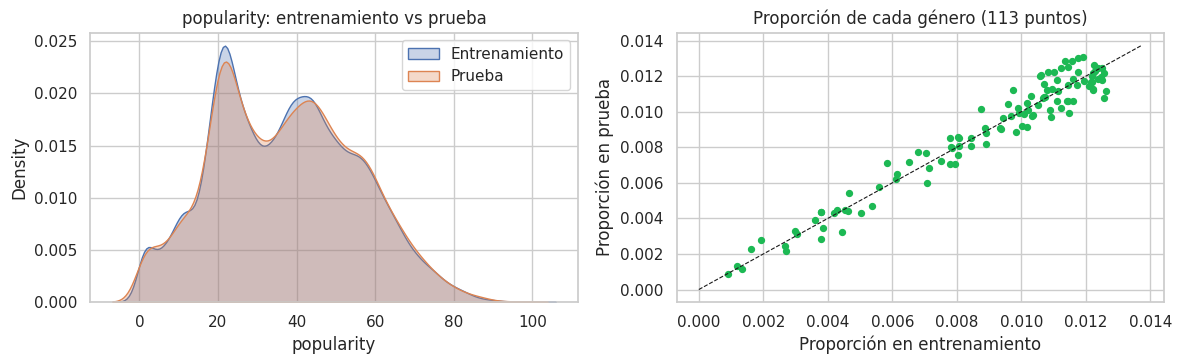

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.kdeplot(y_train, label="Entrenamiento", ax=ax[0], fill=True, alpha=0.3)
sns.kdeplot(y_test, label="Prueba", ax=ax[0], fill=True, alpha=0.3)
ax[0].set_title("popularity: entrenamiento vs prueba"); ax[0].legend()
ax[1].scatter(peso["train"], peso["test"], s=18, color="#1DB954")
lim = peso.values.max() * 1.05
ax[1].plot([0, lim], [0, lim], "k--", lw=0.8)
ax[1].set_xlabel("Proporción en entrenamiento"); ax[1].set_ylabel("Proporción en prueba")
ax[1].set_title("Proporción de cada género (113 puntos)")
plt.tight_layout(); plt.savefig(IMG / "prep_01_particion.png", dpi=120); plt.show()

Las dos particiones tienen una distribución de popularity casi idéntica y cada género conserva prácticamente el mismo peso en ambas (los puntos del gráfico de la derecha caen sobre la diagonal). Eso asegura que la evaluación final sea representativa y no favorezca a ningún género.

### 3.5 Guardado de la partición y de la matriz para clustering

Se guarda a qué conjunto pertenece cada canción, de modo que cualquier persona pueda reproducir exactamente la misma partición. Para el clustering (sección 5) se usan solo las características de audio, **sin** popularity ni género: así los segmentos reflejan cómo suena la música y luego se comparan con la popularidad y el género, en lugar de estar construidos a partir de ellos.

In [20]:
particion = pd.DataFrame({"track_id": df["track_id"].values, "particion": "entrenamiento"})
particion.loc[idx_test, "particion"] = "prueba"
particion.to_csv(DATA / "particion_train_test.csv", index=False)
print(particion["particion"].value_counts().to_string())

# Matriz para clustering: solo audio, estandarizada (K-Means y PCA son sensibles a la escala)
X_cluster = StandardScaler().fit_transform(df[AUDIO])
print(f"\nMatriz para clustering: {X_cluster.shape[0]:,} canciones x {X_cluster.shape[1]} variables de audio")

particion
entrenamiento    63531
prueba           15888

Matriz para clustering: 79,419 canciones x 9 variables de audio


### 3.6 Resumen de la preparación

| Paso | Decisión | Fundamento |
|---|---|---|
| Datos de partida | 79.419 canciones modelables, sin nulos | EP1: una fila por canción, popularity = 0 excluido como dato faltante |
| Variables | 13 numéricas + genero_principal y key | Sección 2: el género domina y el audio aporta poco |
| Exclusiones | Identificadores, artists, generos, n_generos, derivadas | No generalizan a canciones nuevas o son redundantes |
| Transformaciones | Lineal: estandarizar + one-hot. Árboles: codificación entera | Cada modelo necesita un formato distinto, ajustado solo con entrenamiento |
| Partición | 80% / 20%, agrupada por id_contenido y estratificada por género | Evita fuga por copias y garantiza los 113 géneros en cada conjunto |
| Validación | 5 pliegues con las mismas reglas, solo sobre el entrenamiento | Compara modelos sin tocar la prueba |
| Valores bajos (1 y 2) | Se conservan | No se puede asegurar que sean errores (sección 2.5) |

## 4. Modelos supervisados (regresión)

Se construyen **dos modelos de regresión** de familias distintas y se comparan contra la línea base, todos con los mismos 5 pliegues de validación cruzada de la sección 3 (agrupados por id_contenido y estratificados por género). La **prueba (20%) no se toca en esta sección**: se usa recién en la sección 6.

| Modelo | Por qué se elige | Preprocesamiento |
|---|---|---|
| **Línea base: media del género** | Es el mínimo que cualquier modelo debe superar (sección 1.4) | Ninguno |
| **Ridge** (regresión lineal regularizada) | Modelo simple e interpretable; la regularización controla la colinealidad entre energy, loudness y acousticness (sección 2.3) | Estandarizar + one-hot |
| **HistGradientBoosting** (árboles potenciados) | Captura relaciones **no lineales** e interacciones (por ejemplo, audio × género) y maneja bien las 113 categorías de género | Codificación entera, con género y key tratados como categorías |

Los hiperparámetros se eligen con validación cruzada sobre el entrenamiento, minimizando el **MAE**, que es la métrica que entiende el negocio (puntos de popularidad).

Las secciones 4.9 a 4.12 amplían este trabajo: se optimizan más a fondo los hiperparámetros, se incorporan Random Forest y dos ensambles (*voting* y *stacking*), se evalúa la capacidad de generalización y se selecciona la solución final.

In [21]:
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
import joblib, time

def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "R2": r2_score(y_real, y_pred)}

class MediaPorGenero(BaseEstimator, RegressorMixin):
    """Línea base: predice la media de popularity del género (calculada solo con el entrenamiento)."""
    def fit(self, X, y):
        self.global_ = float(np.mean(y))
        self.medias_ = pd.Series(np.asarray(y)).groupby(np.asarray(X["genero_principal"])).mean()
        return self
    def predict(self, X):
        return X["genero_principal"].map(self.medias_).fillna(self.global_).to_numpy()

def evaluar_cv(modelo, X_, y_, splits=CV_SPLITS):
    """Entrena en cada pliegue y mide en el pliegue de validación. Devuelve métricas por pliegue y predicciones fuera de muestra."""
    filas, oof = [], np.zeros(len(y_))
    for k, (a, b) in enumerate(splits, start=1):
        m = clone(modelo).fit(X_.iloc[a], y_.iloc[a])
        oof[b] = m.predict(X_.iloc[b])
        filas.append({"pliegue": k, **metricas(y_.iloc[b], oof[b])})
    return pd.DataFrame(filas).set_index("pliegue"), oof

def resumen_cv(tabla):
    return tabla.agg(["mean", "std"]).T.rename(columns={"mean": "media", "std": "desv."})

def pipe_arboles(num_cols, cat_cols, **params):
    """HistGradientBoosting con las categóricas marcadas como tales (van después de las numéricas)."""
    prep = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ])
    idx_cat = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
    base = dict(categorical_features=idx_cat, random_state=RANDOM_STATE)
    base.update(params)
    return Pipeline([("prep", prep), ("modelo", HistGradientBoostingRegressor(**base))])


### 4.2 Línea base con validación cruzada

En la sección 1.8 la línea base se calculó sobre todos los datos. Aquí se recalcula en igualdad de condiciones con los modelos: la media se aprende en el entrenamiento de cada pliegue y se evalúa en el pliegue de validación.

In [22]:
cv_global,  oof_global  = evaluar_cv(DummyRegressor(strategy="mean"), X_train, y_train)
cv_base,    oof_base    = evaluar_cv(MediaPorGenero(), X_train, y_train)

print("Media global (CV):")
display(resumen_cv(cv_global).round(3))
print("Media del género (CV) - línea base a superar:")
display(resumen_cv(cv_base).round(3))

MAE_BASE = cv_base["MAE"].mean()
print(f"\nMeta del KPI de reducción de error: MAE <= {MAE_BASE * 0.8:.2f} (20% menos que {MAE_BASE:.2f})")

Media global (CV):


,media,desv.
MAE,15.129,0.122
RMSE,18.128,0.125
R2,-0.000,0.000


Media del género (CV) - línea base a superar:


,media,desv.
MAE,9.740,0.124
RMSE,13.519,0.171
R2,0.444,0.010



Meta del KPI de reducción de error: MAE <= 7.79 (20% menos que 9.74)


Predecir la media global da un MAE de **15,13** puntos; predecir la media del género lo baja a **9,74** (R² = 0,444) sin usar ninguna característica de audio. Esa es la línea base que cualquier modelo debe superar. Los resultados casi no varían entre pliegues (desviación de 0,12 en el MAE), por lo que una diferencia de más de unas décimas entre modelos es real y no ruido de la partición. La meta del KPI queda en **MAE ≤ 7,79**.

### 4.3 Modelo 1: Ridge

Ridge ajusta una regresión lineal penalizando coeficientes grandes (alpha). Con variables correlacionadas entre sí, esa penalización estabiliza los coeficientes. Se busca el mejor alpha en una grilla, con los mismos 5 pliegues.

In [23]:
pipe_ridge = Pipeline([("prep", preprocesador_lineal()), ("modelo", Ridge())])
busq_ridge = GridSearchCV(
    pipe_ridge, {"modelo__alpha": np.logspace(-4, 3, 15)},
    cv=CV_SPLITS, scoring="neg_mean_absolute_error", n_jobs=-1, return_train_score=False)
busq_ridge.fit(X_train, y_train)

res = pd.DataFrame(busq_ridge.cv_results_)[["param_modelo__alpha", "mean_test_score"]]
res["MAE"] = -res.pop("mean_test_score")
display(res.rename(columns={"param_modelo__alpha": "alpha"}).round(4).T)
print(f"Mejor alpha: {busq_ridge.best_params_['modelo__alpha']:.3g}")

ridge_final = busq_ridge.best_estimator_
cv_ridge, oof_ridge = evaluar_cv(ridge_final, X_train, y_train)
display(resumen_cv(cv_ridge).round(3))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
alpha,0.0001,0.0003,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.000,316.2278,1000.0000
MAE,9.6774,9.6774,9.6774,9.6774,9.6775,9.6776,9.6779,9.6789,9.6822,9.6926,9.7267,9.8393,10.197,11.0846,12.4365


Mejor alpha: 0.0001


,media,desv.
MAE,9.677,0.123
RMSE,13.434,0.172
R2,0.451,0.010


El mejor alpha es 0,0001, el valor más bajo de la grilla, y el MAE es prácticamente idéntico (9,68) hasta alpha ≈ 0,1; solo empeora cuando la penalización es fuerte (12,4 con alpha = 1000). Es decir, **la regularización no aporta aquí** y Ridge se comporta como una regresión lineal común. Como la curva es plana a la izquierda, ampliar la grilla hacia valores menores no cambiaría el resultado.

Esto matiza lo esperado en la sección 2.3: la colinealidad entre energy, loudness y acousticness dificulta interpretar los coeficientes individuales, pero con unas 63.000 canciones no desestabiliza las predicciones. El resultado es un MAE de **9,68** frente a 9,74 de la línea base (mejora de solo 0,6%) y un R² de 0,451 frente a 0,444: un modelo lineal casi no extrae información del audio más allá del género.

### 4.4 Modelo 2: HistGradientBoosting

Es un conjunto de árboles pequeños entrenados en secuencia, donde cada uno corrige el error del anterior. Se usa HistGradientBoostingRegressor, un **regresor**: predice un número de 0 a 100, no una clase. Los hiperparámetros que más influyen son la tasa de aprendizaje, el número de iteraciones, el tamaño de cada árbol y la regularización; se exploran con una búsqueda aleatoria sobre los mismos 5 pliegues.

**Función de pérdida.** Cada árbol nuevo se entrena para reducir una *pérdida*, que mide qué tan mal predice el modelo hasta ese momento. El valor por defecto (loss="squared_error", error cuadrático) castiga los errores grandes mucho más y empuja las predicciones hacia el **promedio**. La alternativa (loss="absolute_error", error absoluto) trata todos los errores por igual y apunta a la **mediana**, menos sensible a valores extremos como las canciones de popularidad 1–2 (sección 2.5). Como los hiperparámetros se eligen y los resultados se reportan por MAE (error absoluto promedio), entrenar con error absoluto alinea lo que el modelo optimiza con lo que se mide. Como no es obvio cuál rinde mejor, se hace la misma búsqueda con cada pérdida y se elige la de menor MAE en validación cruzada.


In [24]:
t0 = time.time()
espacio = {
    "modelo__learning_rate":     [0.03, 0.05, 0.1],
    "modelo__max_iter":          [200, 400, 600],
    "modelo__max_leaf_nodes":    [15, 31, 63],
    "modelo__min_samples_leaf":  [20, 50, 100],
    "modelo__l2_regularization": [0.0, 1.0, 10.0],
}

# Se hace la misma búsqueda (mismas 12 combinaciones y mismos 5 pliegues) con cada función de pérdida y se elige
# la que logra el menor MAE de validación cruzada, que es la métrica con que se evalúa el proyecto.
busquedas, cv_perdida, oof_perdida = {}, {}, {}
for perdida in ["squared_error", "absolute_error"]:
    busquedas[perdida] = RandomizedSearchCV(
        pipe_arboles(NUMERICAS, CATEGORICAS, loss=perdida), espacio, n_iter=12, cv=CV_SPLITS,
        scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    cv_perdida[perdida], oof_perdida[perdida] = evaluar_cv(busquedas[perdida].best_estimator_, X_train, y_train)
print(f"Búsquedas terminadas en {(time.time() - t0) / 60:.1f} min")

comparacion_perdida = pd.DataFrame({
    p: {"MAE": t["MAE"].mean(), "MAE desv.": t["MAE"].std(), "RMSE": t["RMSE"].mean(), "R2": t["R2"].mean()}
    for p, t in cv_perdida.items()}).T
display(comparacion_perdida.style.format({"MAE": "{:.2f}", "MAE desv.": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.3f}"}))
print("¿Las dos búsquedas eligieron los mismos hiperparámetros?",
      busquedas["squared_error"].best_params_ == busquedas["absolute_error"].best_params_)

PERDIDA = comparacion_perdida["MAE"].idxmin()
print(f"Función de pérdida elegida (menor MAE en validación cruzada): {PERDIDA}\n")

busq_hgb = busquedas[PERDIDA]
res = (pd.DataFrame(busq_hgb.cv_results_)
         .assign(MAE=lambda d: -d["mean_test_score"])
         .sort_values("MAE")[[c for c in busq_hgb.cv_results_ if c.startswith("param_")] + ["MAE"]])
res.columns = [c.replace("param_modelo__", "") for c in res.columns]
display(res.head(6).round(4))

PARAMS_HGB = {k.replace("modelo__", ""): v for k, v in busq_hgb.best_params_.items()}
PARAMS_HGB["loss"] = PERDIDA
print("Mejores hiperparámetros:", PARAMS_HGB)

hgb_final = busq_hgb.best_estimator_
cv_hgb, oof_hgb = cv_perdida[PERDIDA], oof_perdida[PERDIDA]
display(resumen_cv(cv_hgb).round(3))

Búsquedas terminadas en 7.7 min


,MAE,MAE desv.,RMSE,R2
squared_error,8.99,0.11,13.01,0.485
absolute_error,8.46,0.14,13.49,0.446


¿Las dos búsquedas eligieron los mismos hiperparámetros? True
Función de pérdida elegida (menor MAE en validación cruzada): absolute_error



,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,MAE
6,100,63,600,0.05,10.0,8.4646
2,100,63,400,0.10,1.0,8.4725
7,20,63,400,0.10,1.0,8.4908
3,50,63,400,0.10,10.0,8.5110
4,50,31,600,0.10,10.0,8.5156
11,100,15,600,0.05,10.0,8.5222


Mejores hiperparámetros: {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.05, 'l2_regularization': 10.0, 'loss': 'absolute_error'}


,media,desv.
MAE,8.465,0.144
RMSE,13.488,0.261
R2,0.446,0.017


HistGradientBoosting logra un MAE de **8,46** (desviación 0,14 entre pliegues) y un R² de 0,45. Las seis mejores configuraciones quedan entre 8,46 y 8,52, así que el resultado es estable frente a los hiperparámetros elegidos.

**Comparación de las funciones de pérdida.** Entrenar con error absoluto da un MAE de 8,46 y con error cuadrático de 8,99: son 0,52 puntos menos, unas cuatro veces la variación entre pliegues (0,11 a 0,14), así que la diferencia es real. Con error cuadrático salen mejores el RMSE (13,01 frente a 13,49) y el R² (0,485 frente a 0,446), lo esperable, porque cada pérdida optimiza su propia métrica. Ambas búsquedas eligieron los mismos hiperparámetros. Como el proyecto evalúa y elige modelos por MAE (sección 1.3), se usa **absolute_error**. El costo es que el modelo apunta a la mediana de cada tipo de canción y no al promedio: baja el MAE, pero casi no mejora la varianza explicada (R² de 0,446 frente a 0,444 de la línea base).

Dos limitaciones que conviene declarar. Primero, los mejores valores de max_leaf_nodes, max_iter, min_samples_leaf y l2_regularization están en el extremo superior de la grilla: un modelo más complejo podría bajar el MAE un poco más, aunque la diferencia entre configuraciones es de centésimas y no se espera un salto grande. Segundo, se exploraron 12 de las 243 combinaciones posibles para acotar el tiempo de cómputo. Además, como los hiperparámetros se eligieron con los mismos pliegues en que se reporta el MAE, esa cifra puede ser levemente optimista; la evaluación sobre el conjunto de prueba (sección 6) lo corrige.

La sección 4.9 retoma esta limitación con una búsqueda más amplia.

### 4.5 Comparación de los modelos en validación cruzada

,MAE,MAE desv.,RMSE,R2,Mejora de MAE vs línea base
Media global,15.13,0.12,18.13,-0.000,-55.3%
Media del género (base),9.74,0.12,13.52,0.444,+0.0%
Ridge,9.68,0.12,13.43,0.451,+0.6%
HistGradientBoosting,8.46,0.14,13.49,0.446,+13.1%


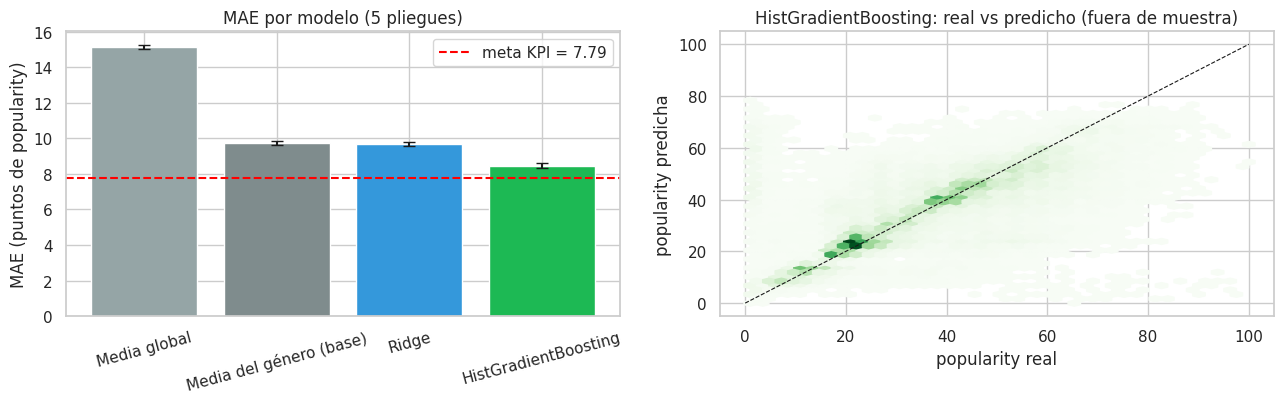

In [25]:
modelos_cv = {"Media global": cv_global, "Media del género (base)": cv_base,
              "Ridge": cv_ridge, "HistGradientBoosting": cv_hgb}
comparacion = pd.DataFrame({
    nombre: {"MAE": t["MAE"].mean(), "MAE desv.": t["MAE"].std(),
             "RMSE": t["RMSE"].mean(), "R2": t["R2"].mean(),
             "Mejora de MAE vs línea base": 1 - t["MAE"].mean() / MAE_BASE}
    for nombre, t in modelos_cv.items()}).T
display(comparacion.style.format({"MAE": "{:.2f}", "MAE desv.": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                                  "Mejora de MAE vs línea base": "{:+.1%}"}))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
nombres = list(modelos_cv)
ax[0].bar(nombres, [t["MAE"].mean() for t in modelos_cv.values()],
          yerr=[t["MAE"].std() for t in modelos_cv.values()],
          color=["#95a5a6", "#7f8c8d", "#3498db", "#1DB954"], capsize=4)
ax[0].axhline(MAE_BASE * 0.8, color="red", ls="--", label=f"meta KPI = {MAE_BASE * 0.8:.2f}")
ax[0].set_ylabel("MAE (puntos de popularity)"); ax[0].set_title("MAE por modelo (5 pliegues)")
ax[0].tick_params(axis="x", rotation=15); ax[0].legend()
ax[1].hexbin(y_train, oof_hgb, gridsize=40, cmap="Greens", mincnt=1)
ax[1].plot([0, 100], [0, 100], "k--", lw=0.8)
ax[1].set_xlabel("popularity real"); ax[1].set_ylabel("popularity predicha")
ax[1].set_title("HistGradientBoosting: real vs predicho (fuera de muestra)")
plt.tight_layout(); plt.savefig(IMG / "mod_01_comparacion.png", dpi=120); plt.show()

El ranking en validación cruzada es HistGradientBoosting (MAE 8,46), Ridge (9,68), media del género (9,74) y media global (15,13). HistGradientBoosting reduce el error **13,1%** respecto de la línea base y Ridge solo 0,6%. La diferencia entre ambos modelos (unos 1,2 puntos) es mucho mayor que la variación entre pliegues (0,12 a 0,14), así que es robusta: las relaciones no lineales y las interacciones entre audio y género sí aportan algo.

**El KPI de reducción de error no se cumple:** la meta era un MAE de 7,79 (20% menos que la línea base) y el mejor modelo llega a 8,46. En el gráfico se ve que ninguna barra baja hasta la línea roja. Siguiendo lo definido en la sección 1.4, la meta no se modifica y se reporta tal cual.

El gráfico de la derecha muestra el segundo problema: las predicciones se concentran entre 20 y 60 puntos. El modelo acierta cerca de la media pero **no logra identificar los extremos**: a las canciones con popularidad real de 80 a 100 les predice 50 a 60, y a algunas con popularidad casi nula les predice más de 60. Esto es esperable cuando el audio explica poco, y afecta justamente a las canciones que le interesan al negocio (las de mayor potencial).

### 4.6 ¿De dónde viene la capacidad predictiva?

Dos análisis para entender el modelo y no solo medirlo:

1. **Con y sin género.** Se entrena HistGradientBoosting con los mismos hiperparámetros pero **sin** genero_principal, para ver cuánto puede predecir el audio por sí solo.
2. **Importancia por permutación.** Se desordena una variable a la vez en un pliegue de validación y se mide cuánto empeora el MAE: mientras más sube, más depende el modelo de ella.

MAE con género:  8.46
MAE sin género:  12.81   (media global: 15.13)
R2 sin género:   0.171  vs con género: 0.446


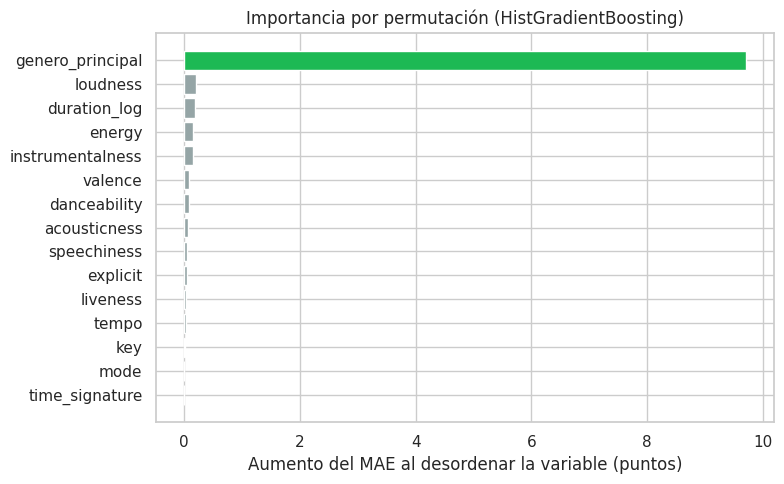

In [26]:
# 1) Audio solo (sin género)
pipe_sin_genero = pipe_arboles(NUMERICAS, ["key"], **PARAMS_HGB)
cv_sin_genero, _ = evaluar_cv(pipe_sin_genero, X_train, y_train)

# 2) Importancia por permutación en el primer pliegue de validación
a, b = CV_SPLITS[0]
m = clone(hgb_final).fit(X_train.iloc[a], y_train.iloc[a])
imp = permutation_importance(m, X_train.iloc[b], y_train.iloc[b], n_repeats=5,
                             scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.Series(imp.importances_mean, index=X_train.columns)).sort_values()

print(f"MAE con género:  {cv_hgb['MAE'].mean():.2f}")
print(f"MAE sin género:  {cv_sin_genero['MAE'].mean():.2f}   (media global: {cv_global['MAE'].mean():.2f})")
print(f"R2 sin género:   {cv_sin_genero['R2'].mean():.3f}  vs con género: {cv_hgb['R2'].mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=["#1DB954" if v == imp.max() else "#95a5a6" for v in imp.values])
ax.set_xlabel("Aumento del MAE al desordenar la variable (puntos)")
ax.set_title("Importancia por permutación (HistGradientBoosting)")
plt.tight_layout(); plt.savefig(IMG / "mod_02_importancia.png", dpi=120); plt.show()

Sin el género, el MAE sube de 8,46 a unos **12,81** y el R² cae de 0,446 a 0,171: el audio por sí solo reduce el error solo un 13% frente a la media global (15,13), mientras que el género aporta el grueso de la capacidad predictiva. La importancia por permutación lo confirma: desordenar genero_principal empeora el MAE en unos **8 puntos**, mientras que ninguna otra variable pasa de unos 0,25 (duration_log, loudness, energy, acousticness e instrumentalness son las mayores) y key, mode y time_signature no aportan nada.

Dos precauciones para interpretar el gráfico: se calculó sobre un solo pliegue, y la importancia por permutación tiende a subestimar variables correlacionadas entre sí (energy, loudness, acousticness), porque el modelo puede compensar con las otras. Aun así, la conclusión es clara para el negocio: **el modelo es, en esencia, la popularidad típica del género refinada con el audio**, y la información disponible antes del lanzamiento explica poco de por qué una canción se vuelve más popular que otra de su mismo género.

### 4.7 Efecto de "n_generos" (medido aparte)

En la sección 3.1 se dejó n_generos fuera del modelo principal: refleja en cuántas listas por género apareció una canción, es un artefacto de cómo se armó el dataset y **no se conoce para una canción nueva**. Aun así, está correlacionada con la popularidad (≈ 0,19), así que se mide cuánto mejoraría el error si se incluyera, para dejar documentada la decisión.

In [27]:
X_ng = X_train.assign(n_generos=df.loc[X_train.index, "n_generos"])
pipe_ng = pipe_arboles(NUMERICAS + ["n_generos"], CATEGORICAS, **PARAMS_HGB)
cv_ng, _ = evaluar_cv(pipe_ng, X_ng, y_train)

dif = cv_hgb["MAE"].mean() - cv_ng["MAE"].mean()
print(f"MAE sin n_generos (modelo principal): {cv_hgb['MAE'].mean():.2f}")
print(f"MAE con n_generos:                    {cv_ng['MAE'].mean():.2f}")
print(f"Diferencia: {dif:.2f} puntos ({dif / cv_hgb['MAE'].mean():.1%})")

MAE sin n_generos (modelo principal): 8.46
MAE con n_generos:                    8.23
Diferencia: 0.23 puntos (2.7%)


Incluir n_generos baja el MAE de 8,46 a **8,23**, una mejora de 0,23 puntos (2,7%). El efecto es pequeño y refuerza la decisión de la sección 3.1 de dejarla fuera: es un artefacto de cómo se armó el dataset (en cuántas listas por género aparece una canción) y no se conoce para una canción nueva, por lo que usarla inflaría artificialmente el resultado. Aun incluyéndola, el MAE (8,23) seguiría por encima de la meta de 7,79, de modo que la decisión no cambia la conclusión sobre el KPI.

### 4.8 Selección del modelo y guardado

Se elige el modelo con menor MAE en validación cruzada. Ambos modelos se reentrenan con **todo el conjunto de entrenamiento** y se guardan en models/. La evaluación final sobre el conjunto de prueba, por género y contra los KPIs, se hace en la sección 6.

In [28]:
tabla_cv = comparacion.loc[["Ridge", "HistGradientBoosting"]]
mejor = tabla_cv["MAE"].idxmin()
print(f"Modelo seleccionado (menor MAE en validación cruzada): {mejor}")

ridge_entrenado = clone(ridge_final).fit(X_train, y_train)
hgb_entrenado   = clone(hgb_final).fit(X_train, y_train)
joblib.dump(ridge_entrenado, MODELS / "modelo_ridge.joblib")
joblib.dump(hgb_entrenado,   MODELS / "modelo_hgb.joblib")
comparacion.to_csv(DATA / "resultados_cv_modelos.csv")
print("Guardados: models/modelo_ridge.joblib, models/modelo_hgb.joblib, data/resultados_cv_modelos.csv")

Modelo seleccionado (menor MAE en validación cruzada): HistGradientBoosting
Guardados: models/modelo_ridge.joblib, models/modelo_hgb.joblib, data/resultados_cv_modelos.csv


Se selecciona **HistGradientBoosting** por tener el menor MAE en validación cruzada (8,46 frente a 9,68 de Ridge). Ambos modelos se reentrenaron con todo el conjunto de entrenamiento y se guardaron, junto con la tabla de resultados. Esta es la selección entre los dos modelos base: en la sección 4.12 se compara además con Random Forest y con dos ensambles, y se confirma HistGradientBoosting con los hiperparámetros de la búsqueda ampliada (models/modelo_final.joblib), que es la versión que se evalúa en la sección 6 sobre el conjunto de prueba, que hasta aquí no se ha tocado.

### 4.9 Optimización de hiperparámetros ampliada

En la sección 4.4 la búsqueda probó solo 12 de las 243 combinaciones de la grilla y varios de los mejores valores quedaron en el borde superior, así que el óptimo podría estar más allá. Aquí se amplía la búsqueda en esa dirección y se mide cuánto mejora el modelo frente a sus hiperparámetros por defecto, para justificar que optimizar vale la pena.

Se usa búsqueda aleatoria con los mismos 5 pliegues agrupados y estratificados, optimizando el MAE, que es la métrica del proyecto. Para HistGradientBoosting se usan rangos más amplios y distribuciones continuas para la tasa de aprendizaje y la regularización, que se muestrean en escala logarítmica. Para Random Forest, que se usa como técnica de ensamble en la sección 4.10, se buscan la profundidad, el tamaño mínimo de las hojas y la fracción de variables que ve cada árbol. El conjunto de prueba sigue sin usarse.

En Random Forest el género entra codificado con la media de popularity de su género (TargetEncoder), calculada solo con el entrenamiento de cada pliegue. Un árbol no separa bien un género codificado como un número cualquiera, y con 113 géneros el one-hot haría el bosque mucho más lento.

In [29]:
from scipy.stats import loguniform, randint
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.preprocessing import TargetEncoder

NUM_RF = NUMERICAS + ["key"]   # en el bosque aleatorio key se deja como número (0 a 11)

def pipe_rf(**params):
    """Random Forest. El género se codifica con la media de popularity de su género (solo con datos de entrenamiento)."""
    prep = ColumnTransformer([
        ("num", "passthrough", NUM_RF),
        ("gen", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), ["genero_principal"]),
    ])
    base = dict(n_estimators=100, max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE)
    base.update(params)
    return Pipeline([("prep", prep), ("modelo", RandomForestRegressor(**base))])

def evaluar_cv_completo(modelo, X_, y_, splits=CV_SPLITS):
    """Como evaluar_cv, pero además mide el MAE en entrenamiento (para ver la brecha) y los tiempos."""
    filas, oof = [], np.zeros(len(y_))
    for k, (a, b) in enumerate(splits, start=1):
        m = clone(modelo)
        t0 = time.time(); m.fit(X_.iloc[a], y_.iloc[a]); t_ajuste = time.time() - t0
        t0 = time.time(); oof[b] = m.predict(X_.iloc[b]); t_pred = time.time() - t0
        filas.append({"pliegue": k, **metricas(y_.iloc[b], oof[b]),
                      "MAE_entrenamiento": mean_absolute_error(y_.iloc[a], m.predict(X_.iloc[a])),
                      "t_ajuste_s": t_ajuste, "t_prediccion_s": t_pred})
    return pd.DataFrame(filas).set_index("pliegue"), oof

def tabla_resumen(dic):
    return pd.DataFrame({n: {"MAE": t["MAE"].mean(), "MAE desv.": t["MAE"].std(),
                             "RMSE": t["RMSE"].mean(), "R2": t["R2"].mean()}
                         for n, t in dic.items()}).T

Búsqueda de HistGradientBoosting terminada en 25.5 min


,MAE,MAE desv.,RMSE,R2,Mejora de MAE vs por defecto
Por defecto,8.571,0.163,13.56,0.440,+0.0%
Búsqueda de 4.4 (12 combinaciones),8.465,0.144,13.49,0.446,+1.2%
Búsqueda ampliada (30 combinaciones),8.441,0.129,13.38,0.455,+1.5%


Mejores hiperparámetros de la búsqueda ampliada: {'l2_regularization': np.float64(40.357092610848504), 'learning_rate': np.float64(0.04547611147126364), 'max_iter': 1063, 'max_leaf_nodes': 218, 'min_samples_leaf': 70}


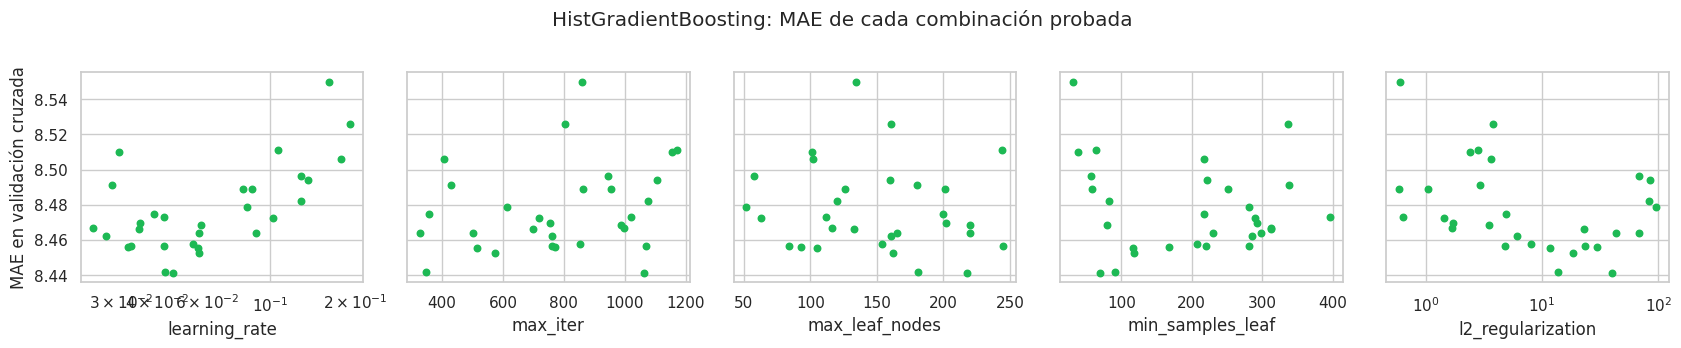

In [30]:
# HistGradientBoosting: hiperparámetros por defecto frente a una búsqueda aleatoria más amplia (30 combinaciones)
t0 = time.time()
cv_hgb_defecto, _ = evaluar_cv(pipe_arboles(NUMERICAS, CATEGORICAS, loss=PERDIDA), X_train, y_train)

espacio_hgb2 = {
    "modelo__learning_rate":     loguniform(0.02, 0.2),
    "modelo__max_iter":          randint(300, 1201),
    "modelo__max_leaf_nodes":    randint(31, 256),
    "modelo__min_samples_leaf":  randint(30, 401),
    "modelo__l2_regularization": loguniform(0.5, 100),
}
busq_hgb2 = RandomizedSearchCV(
    pipe_arboles(NUMERICAS, CATEGORICAS, loss=PERDIDA), espacio_hgb2, n_iter=30, cv=CV_SPLITS,
    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
cv_hgb2, oof_hgb2 = evaluar_cv(busq_hgb2.best_estimator_, X_train, y_train)
print(f"Búsqueda de HistGradientBoosting terminada en {(time.time() - t0) / 60:.1f} min")

comp_hgb = tabla_resumen({
    "Por defecto": cv_hgb_defecto,
    "Búsqueda de 4.4 (12 combinaciones)": cv_hgb,
    "Búsqueda ampliada (30 combinaciones)": cv_hgb2})
comp_hgb["Mejora de MAE vs por defecto"] = 1 - comp_hgb["MAE"] / comp_hgb.loc["Por defecto", "MAE"]
display(comp_hgb.style.format({"MAE": "{:.3f}", "MAE desv.": "{:.3f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                               "Mejora de MAE vs por defecto": "{:+.1%}"}))

PARAMS_HGB2 = {k.replace("modelo__", ""): v for k, v in busq_hgb2.best_params_.items()}
print("Mejores hiperparámetros de la búsqueda ampliada:", PARAMS_HGB2)

# ¿Qué hiperparámetros importan? Cada punto es una combinación probada.
res2 = pd.DataFrame(busq_hgb2.cv_results_)
res2["MAE"] = -res2["mean_test_score"]
fig, ax = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for a, p in zip(ax, ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization"]):
    a.scatter(res2[f"param_modelo__{p}"].astype(float), res2["MAE"], s=22, color="#1DB954")
    if p in ("learning_rate", "l2_regularization"):
        a.set_xscale("log")
    a.set_xlabel(p)
ax[0].set_ylabel("MAE en validación cruzada")
fig.suptitle("HistGradientBoosting: MAE de cada combinación probada", y=1.02)
plt.tight_layout(); plt.savefig(IMG / "mod_03_busqueda_hgb.png", dpi=120, bbox_inches="tight"); plt.show()

La búsqueda ampliada confirma que el modelo ya estaba cerca de su mejor desempeño. Con 30 combinaciones nuevas el MAE baja de 8,571 (hiperparámetros por defecto) a **8,441**, una mejora de 1,5%. La búsqueda de la sección 4.4 (12 combinaciones) había llegado a 8,465, así que ampliarla aporta solo 0,024 puntos más, bastante menos que la variación entre pliegues (0,13).

Optimizar sirve, pero poco. Las 30 combinaciones del gráfico se mueven en un rango estrecho (de 8,44 a 8,55) y ningún hiperparámetro cambia el resultado de forma drástica: las tasas de aprendizaje más altas (sobre 0,1) concentran los peores valores, y con unas 350 iteraciones se llega a un MAE casi igual que con unas 1.000. Los mejores valores (tasa de aprendizaje 0,045, 1.063 iteraciones, 218 hojas por árbol, mínimo de 70 canciones por hoja y regularización L2 de 40) ya no quedan pegados al borde de la grilla como en 4.4, y el MAE es casi plano alrededor del óptimo, por lo que la limitación que se declaró en esa sección queda resuelta. Como los hiperparámetros se eligieron con los mismos pliegues en que se reporta el MAE, la cifra de 8,441 puede ser levemente optimista; la sección 6 la contrasta con el conjunto de prueba, que no se ha usado.

In [31]:
# Random Forest: hiperparámetros por defecto frente a una búsqueda aleatoria (6 de 27 combinaciones)
t0 = time.time()
cv_rf_defecto, _ = evaluar_cv(pipe_rf(), X_train, y_train)

espacio_rf = {
    "modelo__max_depth":        [12, 18, 24],
    "modelo__min_samples_leaf": [10, 20, 40],
    "modelo__max_features":     [0.4, 0.6, 0.8],
}
busq_rf = RandomizedSearchCV(
    pipe_rf(), espacio_rf, n_iter=6, cv=CV_SPLITS,
    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1).fit(X_train, y_train)
cv_rf, oof_rf = evaluar_cv(busq_rf.best_estimator_, X_train, y_train)
print(f"Búsqueda de Random Forest terminada en {(time.time() - t0) / 60:.1f} min")

comp_rf = tabla_resumen({"Por defecto (árboles sin límite de profundidad)": cv_rf_defecto,
                         "Optimizado (6 combinaciones)": cv_rf})
comp_rf["Mejora de MAE vs por defecto"] = 1 - comp_rf["MAE"] / comp_rf.iloc[0]["MAE"]
display(comp_rf.style.format({"MAE": "{:.3f}", "MAE desv.": "{:.3f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                              "Mejora de MAE vs por defecto": "{:+.1%}"}))

PARAMS_RF = {k.replace("modelo__", ""): v for k, v in busq_rf.best_params_.items()}
print("Mejores hiperparámetros de Random Forest:", PARAMS_RF)

res_rf = (pd.DataFrame(busq_rf.cv_results_).assign(MAE=lambda d: -d["mean_test_score"])
            .sort_values("MAE")[[c for c in busq_rf.cv_results_ if c.startswith("param_")] + ["MAE"]])
res_rf.columns = [c.replace("param_modelo__", "") for c in res_rf.columns]
display(res_rf.round(4))

Búsqueda de Random Forest terminada en 14.0 min


,MAE,MAE desv.,RMSE,R2,Mejora de MAE vs por defecto
Por defecto (árboles sin límite de profundidad),9.305,0.114,13.21,0.469,+0.0%
Optimizado (6 combinaciones),9.258,0.113,13.14,0.474,+0.5%


Mejores hiperparámetros de Random Forest: {'min_samples_leaf': 10, 'max_features': 0.6, 'max_depth': 24}


,min_samples_leaf,max_features,max_depth,MAE
3,10,0.6,24,9.2584
1,20,0.6,18,9.3090
2,10,0.4,18,9.3319
0,40,0.8,12,9.3746
4,10,0.4,12,9.4173
5,40,0.4,18,9.4614


Random Forest, el representante de *bagging*, mejora poco con la optimización: pasa de un MAE de 9,305 con hiperparámetros por defecto a **9,258** (0,5%) con la mejor de 6 combinaciones (profundidad máxima 24, mínimo de 10 canciones por hoja y 60% de las variables por árbol). Las seis combinaciones quedan entre 9,26 y 9,46, y la mejor está en el extremo de la grilla (la profundidad más alta y las hojas más pequeñas), así que un bosque más profundo podría bajar el MAE un poco más. Se exploraron solo 6 de las 27 combinaciones para acotar el tiempo de cómputo (unos 14 minutos).

Aun optimizado, su MAE es 0,8 puntos peor que el de HistGradientBoosting (8,441), pero tiene mejor RMSE (13,14 frente a 13,38) y mejor R² (0,474 frente a 0,455). La diferencia viene del criterio de entrenamiento: Random Forest minimiza el error cuadrático y apunta al promedio, mientras que HistGradientBoosting se entrenó con error absoluto y apunta a la mediana (sección 4.4). Cada modelo queda mejor en la métrica que optimiza.

### 4.10 Técnicas de ensamble

Un ensamble combina varios modelos para lograr una predicción mejor que la de cada uno por separado. Se comparan cuatro formas, todas evaluadas con la misma validación cruzada de 5 pliegues:

- **Bagging (Random Forest):** entrena muchos árboles sobre muestras distintas de los datos y promedia sus predicciones, lo que reduce la varianza.
- **Boosting (HistGradientBoosting):** entrena árboles en secuencia, cada uno corrigiendo el error del anterior, lo que reduce el sesgo.
- **Voting:** promedia las predicciones de Ridge, Random Forest y HistGradientBoosting.
- **Stacking:** un segundo modelo, una regresión lineal con coeficientes positivos, aprende cuánto pesar la predicción de cada modelo base. Las predicciones de los modelos base con que aprende se generan con una validación cruzada interna, para que no vea canciones con las que esos modelos ya se entrenaron.

Para demostrar el aporte del ensamble se compara el mejor ensamble con el mejor modelo individual pliegue por pliegue, y se mide qué tan distintos son los errores de los modelos base: un ensamble solo ayuda si los modelos se equivocan de forma diferente.

In [33]:
# Se usa la mejor versión de HistGradientBoosting entre la búsqueda de 4.4 y la ampliada de 4.9
hgb_opt = clone(busq_hgb2.best_estimator_ if cv_hgb2["MAE"].mean() < cv_hgb["MAE"].mean() else hgb_final)
rf_opt = clone(busq_rf.best_estimator_)

def base_estimators():
    return [("ridge", clone(ridge_final)), ("rf", clone(rf_opt)), ("hgb", clone(hgb_opt))]

candidatos = {
    "Ridge": clone(ridge_final),
    "Random Forest (bagging)": clone(rf_opt),
    "HistGradientBoosting (boosting)": clone(hgb_opt),
    "Voting (promedio)": VotingRegressor(base_estimators()),
    "Stacking": StackingRegressor(base_estimators(), final_estimator=LinearRegression(positive=True),
                                  cv=KFold(3, shuffle=True, random_state=RANDOM_STATE)),
}

t0 = time.time()
res_cand, oof_cand = {}, {}
for nombre, modelo in candidatos.items():
    t1 = time.time()
    res_cand[nombre], oof_cand[nombre] = evaluar_cv_completo(modelo, X_train, y_train)
    print(f"{nombre}: {(time.time() - t1) / 60:.1f} min")
print(f"Total: {(time.time() - t0) / 60:.1f} min")

tabla_cand = pd.DataFrame({
    n: {"MAE": t["MAE"].mean(), "MAE desv.": t["MAE"].std(), "RMSE": t["RMSE"].mean(), "R2": t["R2"].mean(),
        "MAE entrenamiento": t["MAE_entrenamiento"].mean(),
        "Ajuste por pliegue (s)": t["t_ajuste_s"].mean(), "Predicción por pliegue (s)": t["t_prediccion_s"].mean()}
    for n, t in res_cand.items()}).T
tabla_cand["Brecha (validación - entrenamiento)"] = tabla_cand["MAE"] - tabla_cand["MAE entrenamiento"]
tabla_cand["Mejora de MAE vs línea base"] = 1 - tabla_cand["MAE"] / MAE_BASE
display(tabla_cand.style.format({"MAE": "{:.3f}", "MAE desv.": "{:.3f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                                 "MAE entrenamiento": "{:.2f}", "Ajuste por pliegue (s)": "{:.1f}",
                                 "Predicción por pliegue (s)": "{:.2f}", "Brecha (validación - entrenamiento)": "{:+.2f}",
                                 "Mejora de MAE vs línea base": "{:+.1%}"}))

Ridge: 0.0 min
Random Forest (bagging): 1.7 min
HistGradientBoosting (boosting): 1.7 min
Voting (promedio): 3.4 min
Stacking: 10.0 min
Total: 16.9 min


,MAE,MAE desv.,RMSE,R2,MAE entrenamiento,Ajuste por pliegue (s),Predicción por pliegue (s),Brecha (validación - entrenamiento),Mejora de MAE vs línea base
Ridge,9.677,0.123,13.43,0.451,9.65,0.3,0.06,+0.03,+0.6%
Random Forest (bagging),9.258,0.113,13.14,0.474,8.08,20.1,0.16,+1.17,+4.9%
HistGradientBoosting (boosting),8.441,0.129,13.38,0.455,6.77,14.6,1.12,+1.67,+13.3%
Voting (promedio),8.956,0.130,13.09,0.478,8.05,34.4,1.49,+0.90,+8.1%
Stacking,8.916,0.113,13.05,0.482,7.66,114.1,1.31,+1.26,+8.5%


El ranking por MAE en validación cruzada es HistGradientBoosting (**8,441**), Stacking (8,916), Voting (8,956), Random Forest (9,258) y Ridge (9,677). Los dos ensambles superan a Random Forest y a Ridge, pero ninguno supera al mejor modelo individual: Stacking queda 0,48 puntos por encima y Voting 0,52.

En RMSE y R² ocurre lo contrario: los mejores valores son los del stacking (13,05 y 0,482) frente a HistGradientBoosting (13,38 y 0,455). El orden depende de la métrica y, como el proyecto se evalúa por MAE (sección 1.3), prevalece el primero. El costo de cómputo también pesa: ajustar el stacking toma 114 segundos por pliegue, casi ocho veces lo que toma HistGradientBoosting (15 segundos).

In [34]:
# Aporte del ensamble: el mejor ensamble frente al mejor modelo individual, pliegue por pliegue
simples = ["Ridge", "Random Forest (bagging)", "HistGradientBoosting (boosting)"]
ensambles = ["Voting (promedio)", "Stacking"]
mejor_simple = min(simples, key=lambda n: res_cand[n]["MAE"].mean())
mejor_ens = min(ensambles, key=lambda n: res_cand[n]["MAE"].mean())
dif = res_cand[mejor_simple]["MAE"] - res_cand[mejor_ens]["MAE"]   # positivo: el ensamble mejora

print(f"Mejor modelo individual: {mejor_simple} (MAE {res_cand[mejor_simple]['MAE'].mean():.3f})")
print(f"Mejor ensamble:          {mejor_ens} (MAE {res_cand[mejor_ens]['MAE'].mean():.3f})")
print(f"Diferencia de MAE por pliegue (individual - ensamble; positivo = el ensamble mejora): {np.round(dif.values, 3)}")
print(f"El ensamble mejora en {(dif > 0).sum()} de {len(dif)} pliegues; mejora media de {dif.mean():.3f} puntos "
      f"({dif.mean() / res_cand[mejor_simple]['MAE'].mean():.1%}), con una desviación entre pliegues de {res_cand[mejor_ens]['MAE'].std():.3f}")

# Diversidad: correlación entre los errores (real - predicho) fuera de muestra de los modelos base
err = pd.DataFrame({n: y_train.values - oof_cand[n] for n in simples})
print("\nCorrelación entre los errores de los modelos base (más baja = más diversidad):")
display(err.corr().round(3))

# Stacking: cuánto pesa cada modelo base según el modelo de segundo nivel (entrenado con todo el entrenamiento)
stack_completo = clone(candidatos["Stacking"]).fit(X_train, y_train)
pesos = pd.Series(stack_completo.final_estimator_.coef_, index=["Ridge", "Random Forest", "HistGradientBoosting"])
print("\nPesos del stacking:"); display(pesos.round(3).to_frame("peso"))
print(f"Intercepto: {stack_completo.final_estimator_.intercept_:.3f}")

Mejor modelo individual: HistGradientBoosting (boosting) (MAE 8.441)
Mejor ensamble:          Stacking (MAE 8.916)
Diferencia de MAE por pliegue (individual - ensamble; positivo = el ensamble mejora): [-0.466 -0.491 -0.449 -0.483 -0.487]
El ensamble mejora en 0 de 5 pliegues; mejora media de -0.475 puntos (-5.6%), con una desviación entre pliegues de 0.113

Correlación entre los errores de los modelos base (más baja = más diversidad):


,Ridge,Random Forest (bagging),HistGradientBoosting (boosting)
Ridge,1.000,0.980,0.927
Random Forest (bagging),0.980,1.000,0.946
HistGradientBoosting (boosting),0.927,0.946,1.000



Pesos del stacking:


,peso
Ridge,0.000
Random Forest,0.600
HistGradientBoosting,0.369


Intercepto: 1.367


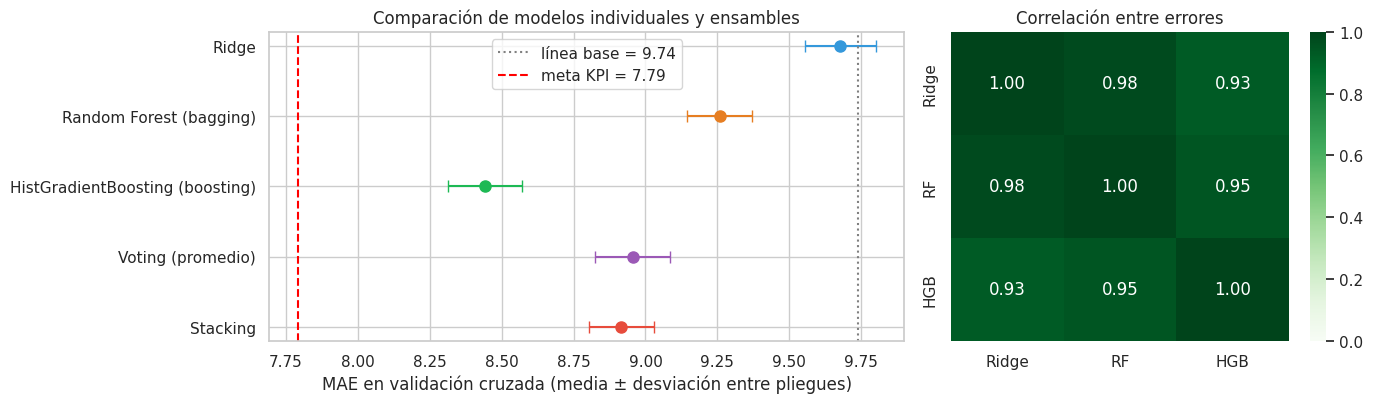

In [35]:
nombres = list(tabla_cand.index)
colores = ["#3498db", "#e67e22", "#1DB954", "#9b59b6", "#e74c3c"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
for i, n in enumerate(nombres):
    ax[0].errorbar(tabla_cand.loc[n, "MAE"], i, xerr=tabla_cand.loc[n, "MAE desv."], fmt="o", color=colores[i], capsize=4, ms=8)
ax[0].axvline(MAE_BASE, color="gray", ls=":", label=f"línea base = {MAE_BASE:.2f}")
ax[0].axvline(MAE_BASE * 0.8, color="red", ls="--", label=f"meta KPI = {MAE_BASE * 0.8:.2f}")
ax[0].set_yticks(range(len(nombres))); ax[0].set_yticklabels(nombres); ax[0].invert_yaxis()
ax[0].set_xlabel("MAE en validación cruzada (media ± desviación entre pliegues)")
ax[0].set_title("Comparación de modelos individuales y ensambles"); ax[0].legend()
sns.heatmap(err.corr(), annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=ax[1],
            xticklabels=["Ridge", "RF", "HGB"], yticklabels=["Ridge", "RF", "HGB"])
ax[1].set_title("Correlación entre errores")
plt.tight_layout(); plt.savefig(IMG / "mod_04_ensambles.png", dpi=120); plt.show()

**El ensamble no mejora el modelo.** Al comparar el mejor ensamble (stacking) con el mejor modelo individual pliegue por pliegue, el ensamble empeora en los 5 pliegues, con una diferencia estable de 0,45 a 0,49 puntos (5,6% en promedio). Eso equivale a unas cuatro veces la variación entre pliegues (0,11), por lo que no es ruido de la partición. Las salidas muestran dos razones.

**Poca diversidad.** Un ensamble solo ayuda si sus modelos se equivocan de manera distinta, y aquí los errores están casi perfectamente correlacionados: 0,93 entre Ridge e HistGradientBoosting, 0,95 entre Random Forest e HistGradientBoosting y 0,98 entre Ridge y Random Forest. Los tres modelos se apoyan en la misma información (sobre todo el género, sección 4.6) y fallan en las mismas canciones, de modo que promediarlos casi no cancela errores.

**Objetivos distintos.** El stacking pesa a Random Forest (0,60) y a HistGradientBoosting (0,37) y deja a Ridge en 0, pero su modelo de segundo nivel es una regresión de mínimos cuadrados, que minimiza el error cuadrático. Por eso gana en RMSE y R², y por eso arrastra hacia el promedio las predicciones de HistGradientBoosting, que apuntan a la mediana, lo que empeora el MAE. Esta explicación es coherente con lo observado en 4.4, pero no se probó directamente: para comprobarla habría que entrenar el bosque y el modelo de segundo nivel con error absoluto.

### 4.11 Capacidad de generalización

Un buen resultado en validación cruzada solo sirve si el modelo mantiene su desempeño con canciones nuevas. Se revisan tres cosas:

- **Brecha entre entrenamiento y validación:** si el error en entrenamiento es mucho menor que en validación, el modelo memoriza en vez de generalizar.
- **Estabilidad entre pliegues:** un modelo confiable da errores parecidos en los 5 pliegues.
- **Curva de aprendizaje:** muestra cómo cambia el error de validación al usar más canciones para entrenar. Si sigue bajando, más datos ayudarían; si se aplana, el límite está en las variables disponibles y no en la cantidad de datos.

Además de MAE, RMSE y R², se calcula Precision@10% con las predicciones fuera de muestra, porque es la métrica más cercana al uso de negocio: elegir qué canciones impulsar dentro de cada género. Es una versión aproximada de la que se usa en la sección 6, así que solo sirve para comparar modelos entre sí y no para contrastarla con esa sección.

,MAE,MAE entrenamiento,Brecha (validación - entrenamiento),MAE desv.,Precision@10% (VC)
Ridge,9.677,9.65,+0.03,0.123,14.1%
Random Forest (bagging),9.258,8.08,+1.17,0.113,18.2%
HistGradientBoosting (boosting),8.441,6.77,+1.67,0.129,18.6%
Voting (promedio),8.956,8.05,+0.90,0.130,18.7%
Stacking,8.916,7.66,+1.26,0.113,19.1%


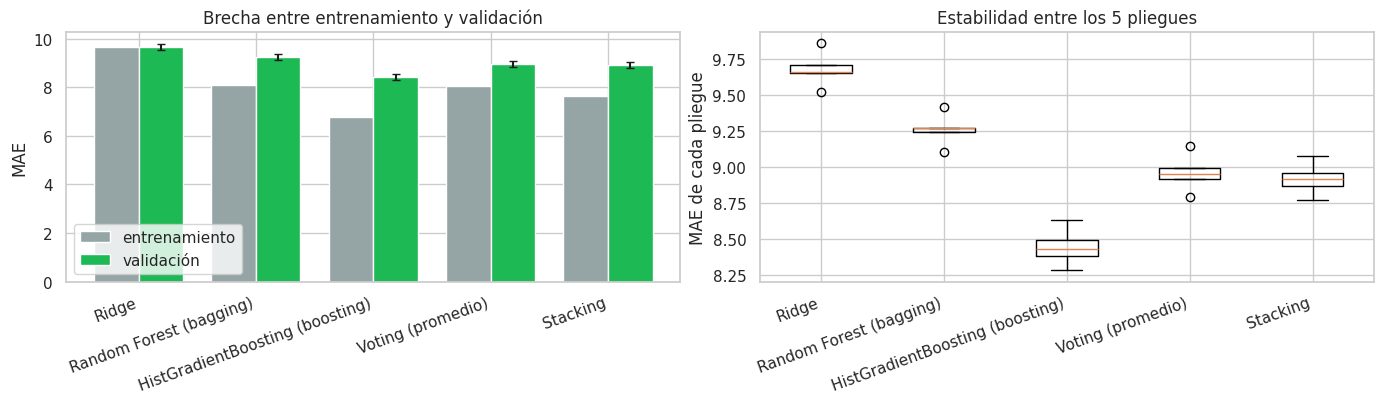

In [36]:
def precision_top(y_real, y_pred, genero, fraccion=0.10):
    """Dentro de cada género: de las canciones marcadas (10% con mayor predicción), cuántas están en el 10% real más popular."""
    d = pd.DataFrame({"real": np.asarray(y_real), "pred": np.asarray(y_pred), "g": np.asarray(genero)})
    n_marcar = d.groupby("g")["pred"].transform(lambda s: max(1, int(np.ceil(len(s) * fraccion))))
    marcada = d.groupby("g")["pred"].rank(method="first", ascending=False) <= n_marcar
    en_top = d["real"] >= d.groupby("g")["real"].transform(lambda s: s.quantile(1 - fraccion))
    return float((marcada & en_top).sum() / marcada.sum())

tabla_cand["Precision@10% (VC)"] = [precision_top(y_train, oof_cand[n], X_train["genero_principal"]) for n in tabla_cand.index]
display(tabla_cand[["MAE", "MAE entrenamiento", "Brecha (validación - entrenamiento)", "MAE desv.", "Precision@10% (VC)"]]
        .style.format({"MAE": "{:.3f}", "MAE entrenamiento": "{:.2f}", "Brecha (validación - entrenamiento)": "{:+.2f}",
                       "MAE desv.": "{:.3f}", "Precision@10% (VC)": "{:.1%}"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(nombres)); w = 0.38
ax[0].bar(x - w / 2, tabla_cand["MAE entrenamiento"], w, label="entrenamiento", color="#95a5a6")
ax[0].bar(x + w / 2, tabla_cand["MAE"], w, yerr=tabla_cand["MAE desv."], capsize=3, label="validación", color="#1DB954")
ax[0].set_xticks(x); ax[0].set_xticklabels(nombres, rotation=20, ha="right")
ax[0].set_ylabel("MAE"); ax[0].set_title("Brecha entre entrenamiento y validación"); ax[0].legend()
ax[1].boxplot([res_cand[n]["MAE"] for n in nombres])
ax[1].set_xticklabels(nombres, rotation=20, ha="right")
ax[1].set_ylabel("MAE de cada pliegue"); ax[1].set_title("Estabilidad entre los 5 pliegues")
plt.tight_layout(); plt.savefig(IMG / "mod_05_generalizacion.png", dpi=120); plt.show()

**Brecha entre entrenamiento y validación.** Ridge casi no tiene brecha (+0,03), pero porque es demasiado simple: su error es alto tanto en entrenamiento como en validación. Los modelos de árboles sí la tienen: HistGradientBoosting +1,67, Stacking +1,26, Random Forest +1,17 y Voting +0,90. HistGradientBoosting tiene la brecha más grande, pero también el menor error de validación, y lo que importa para generalizar es el error con canciones nuevas. Su error de entrenamiento (6,77) está lejos de cero, así que el modelo no memoriza, y una brecha de unos 1,7 puntos es moderada.

**Estabilidad entre pliegues.** El MAE de cada pliegue varía poco (desviación de 0,11 a 0,13 en todos los modelos), y en el gráfico los cinco valores de HistGradientBoosting quedan por debajo de los de cualquier otro modelo. La ventaja no depende de una partición particular.

**Precisión en priorización.** Con Precision@10% en validación, los ensambles (18,7% y 19,1%) quedan apenas por sobre HistGradientBoosting (18,6%). Son diferencias de menos de un punto, que no justifican su costo, mientras que Ridge es el más bajo (14,1%). Todos los modelos quedan lejos del 40% que pide el KPI.

Curva de aprendizaje terminada en 5.0 min


,canciones,MAE entrenamiento,MAE validación
fraccion,,,
0.2,10164.6,7.19,8.91
0.4,20329.6,6.75,8.67
0.6,30494.6,6.67,8.58
0.8,40659.6,6.79,8.50
1.0,50824.8,6.77,8.44


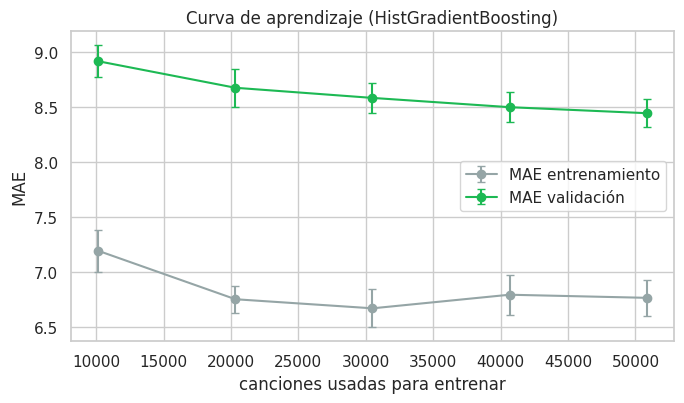

In [37]:
# Curva de aprendizaje de HistGradientBoosting (la versión optimizada): error según la cantidad de canciones de entrenamiento
fracciones = [0.2, 0.4, 0.6, 0.8, 1.0]
rng = np.random.RandomState(RANDOM_STATE)
filas = []
t0 = time.time()
for k, (a, b) in enumerate(CV_SPLITS, start=1):
    for f in fracciones:
        sub = a if f == 1.0 else rng.choice(a, size=int(len(a) * f), replace=False)
        m = clone(hgb_opt).fit(X_train.iloc[sub], y_train.iloc[sub])
        filas.append({"pliegue": k, "canciones": len(sub),
                      "MAE entrenamiento": mean_absolute_error(y_train.iloc[sub], m.predict(X_train.iloc[sub])),
                      "MAE validación": mean_absolute_error(y_train.iloc[b], m.predict(X_train.iloc[b]))})
print(f"Curva de aprendizaje terminada en {(time.time() - t0) / 60:.1f} min")

curva = pd.DataFrame(filas).assign(fraccion=lambda d: d.groupby("pliegue")["canciones"].transform(lambda s: s / s.max()).round(1))
resumen_curva = curva.groupby("fraccion")[["canciones", "MAE entrenamiento", "MAE validación"]].mean()
display(resumen_curva.round(2))

fig, ax = plt.subplots(figsize=(7, 4.2))
x_cancs = curva.groupby("fraccion")["canciones"].mean()
for col, color in [("MAE entrenamiento", "#95a5a6"), ("MAE validación", "#1DB954")]:
    g = curva.groupby("fraccion")[col]
    ax.errorbar(x_cancs.values, g.mean().values, yerr=g.std().values, marker="o", capsize=3, label=col, color=color)
ax.set_xlabel("canciones usadas para entrenar"); ax.set_ylabel("MAE")
ax.set_title("Curva de aprendizaje (HistGradientBoosting)"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "mod_06_curva_aprendizaje.png", dpi=120); plt.show()

**Curva de aprendizaje.** Al pasar de unas 10.000 a unas 50.800 canciones de entrenamiento, el MAE de validación baja de 8,91 a 8,44, y cada tramo aporta menos que el anterior: la mejora es de unos 0,09 por cada 10.000 canciones entre las 20.000 y las 40.000, y de 0,06 en el último tramo. El error de entrenamiento se mantiene cerca de 6,7 desde las 20.000 canciones y la distancia entre ambas curvas se mueve entre 1,7 y 1,9 puntos sin crecer, es decir, el sobreajuste no empeora al agregar datos.

La curva todavía no es del todo plana, así que más canciones mejorarían el MAE algo más. Pero la pendiente indica una ganancia pequeña: para cerrar los 0,65 puntos que faltan hasta la meta de 7,79 harían falta, al ritmo actual, más de 100.000 canciones adicionales (el catálogo modelable completo tiene 79.419), y la pendiente además va disminuyendo. El límite está en la información disponible (el audio y el género explican poco de por qué una canción es más popular que otra, sección 4.6) y no en la cantidad de datos.

### 4.12 Selección de la solución final

La selección no se hace solo por el MAE más bajo. Se aplica una regla de un error estándar: se toma el mejor MAE de validación cruzada, se le suma su error estándar entre pliegues (la desviación dividida por la raíz de 5) y se consideran empatados todos los modelos que quedan dentro de ese margen. Entre los empatados se elige el más simple, porque una diferencia menor que el ruido de la partición no justifica un modelo más lento, más difícil de explicar y más caro de mantener. El orden de simplicidad es Ridge, HistGradientBoosting, Random Forest, Voting y Stacking.

La tabla resume, por modelo, el error, la brecha entre entrenamiento y validación, los tiempos y la Precision@10%, para justificar la decisión con el costo y con el aporte al objetivo de negocio: reducir el error de estimación y priorizar mejor las canciones. El modelo elegido se entrena con todo el conjunto de entrenamiento y se guarda en models/ para evaluarlo en la sección 6, que sigue siendo el único lugar donde se usa el conjunto de prueba.

In [38]:
ORDEN_SIMPLICIDAD = ["Ridge", "HistGradientBoosting (boosting)", "Random Forest (bagging)", "Voting (promedio)", "Stacking"]
cand = tabla_cand.loc[ORDEN_SIMPLICIDAD]

mejor_nombre = cand["MAE"].idxmin()
error_estandar = cand.loc[mejor_nombre, "MAE desv."] / np.sqrt(len(CV_SPLITS))
margen = cand.loc[mejor_nombre, "MAE"] + error_estandar
empatados = [n for n in ORDEN_SIMPLICIDAD if cand.loc[n, "MAE"] <= margen]
SELECCION = empatados[0]   # la lista está ordenada de más simple a más complejo

print(f"Menor MAE en validación cruzada: {mejor_nombre} ({cand.loc[mejor_nombre, 'MAE']:.3f}); error estándar {error_estandar:.3f}")
print(f"Modelos dentro del margen (MAE <= {margen:.3f}): {empatados}")
print(f"Solución seleccionada (la más simple entre los empatados): {SELECCION}")
print(f"Reducción de error frente a la línea base: {cand.loc[SELECCION, 'Mejora de MAE vs línea base']:.1%} (meta del KPI: 20%)")

resumen_seleccion = cand[["MAE", "MAE desv.", "RMSE", "R2", "Brecha (validación - entrenamiento)",
                          "Ajuste por pliegue (s)", "Predicción por pliegue (s)", "Precision@10% (VC)",
                          "Mejora de MAE vs línea base"]].copy()
resumen_seleccion["Seleccionado"] = ["sí" if n == SELECCION else "" for n in resumen_seleccion.index]
display(resumen_seleccion.style.format({"MAE": "{:.3f}", "MAE desv.": "{:.3f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                                        "Brecha (validación - entrenamiento)": "{:+.2f}", "Ajuste por pliegue (s)": "{:.1f}",
                                        "Predicción por pliegue (s)": "{:.2f}", "Precision@10% (VC)": "{:.1%}",
                                        "Mejora de MAE vs línea base": "{:+.1%}"}))

# Entrenamiento final con todo el conjunto de entrenamiento y guardado (la prueba se usa recién en la sección 6)
modelo_final = stack_completo if SELECCION == "Stacking" else clone(candidatos[SELECCION]).fit(X_train, y_train)
joblib.dump(modelo_final, MODELS / "modelo_final.joblib")
(MODELS / "modelo_final_nombre.txt").write_text(SELECCION, encoding="utf-8")
resumen_seleccion.to_csv(DATA / "resultados_cv_seleccion_final.csv")
print("Guardados: models/modelo_final.joblib, models/modelo_final_nombre.txt, data/resultados_cv_seleccion_final.csv")

Menor MAE en validación cruzada: HistGradientBoosting (boosting) (8.441); error estándar 0.058
Modelos dentro del margen (MAE <= 8.499): ['HistGradientBoosting (boosting)']
Solución seleccionada (la más simple entre los empatados): HistGradientBoosting (boosting)
Reducción de error frente a la línea base: 13.3% (meta del KPI: 20%)


,MAE,MAE desv.,RMSE,R2,Brecha (validación - entrenamiento),Ajuste por pliegue (s),Predicción por pliegue (s),Precision@10% (VC),Mejora de MAE vs línea base,Seleccionado
Ridge,9.677,0.123,13.43,0.451,+0.03,0.3,0.06,14.1%,+0.6%,
HistGradientBoosting (boosting),8.441,0.129,13.38,0.455,+1.67,14.6,1.12,18.6%,+13.3%,sí
Random Forest (bagging),9.258,0.113,13.14,0.474,+1.17,20.1,0.16,18.2%,+4.9%,
Voting (promedio),8.956,0.130,13.09,0.478,+0.90,34.4,1.49,18.7%,+8.1%,
Stacking,8.916,0.113,13.05,0.482,+1.26,114.1,1.31,19.1%,+8.5%,


Guardados: models/modelo_final.joblib, models/modelo_final_nombre.txt, data/resultados_cv_seleccion_final.csv


**Solución seleccionada: HistGradientBoosting con los hiperparámetros de la búsqueda ampliada.** Tiene el menor MAE de validación cruzada (8,441) y un error estándar de 0,058 (0,129 dividido por la raíz de 5), por lo que el margen de empate llega hasta 8,499. Ningún otro modelo entra en ese margen: el siguiente, Stacking, está en 8,916, unos 8 errores estándar más arriba. La regla no tiene empates que resolver y la decisión se apoya directamente en el resultado.

Los demás criterios de la tabla la confirman. Stacking y Voting son entre 2 y 8 veces más lentos de ajustar (34 y 114 segundos por pliegue frente a 15), más difíciles de explicar y mantener, y a cambio no mejoran el MAE: su Precision@10% es solo 0,1 y 0,5 puntos mayor y la ventaja se limita al RMSE y al R². Ridge es el más simple, pero apenas mejora a la línea base (0,6%).

La solución seleccionada reduce el error en **13,3%** respecto de la línea base, por debajo de la meta de 20% del KPI. Se guardó en models/modelo_final.joblib y es la que se evalúa en la sección 6 con el conjunto de prueba, que hasta aquí sigue sin usarse.

### 4.13 Conclusiones de la sección 4

| Hallazgo | Implicancia |
|---|---|
| HistGradientBoosting es el mejor modelo (MAE 8,44 en validación cruzada; R² 0,455), 13,3% mejor que la línea base | Es la solución final (sección 4.12); Ridge queda como contraste lineal |
| La búsqueda ampliada (30 combinaciones) baja el MAE de 8,57 a 8,44, solo 1,5% | Optimizar ayuda poco: el MAE es casi plano alrededor del óptimo y el límite no está en los hiperparámetros (sección 4.9) |
| Random Forest optimizado (bagging) llega a un MAE de 9,26, peor que HistGradientBoosting, pero con mejor RMSE y R² | Cada modelo gana en la métrica que optimiza: error cuadrático frente a error absoluto |
| Voting (8,96) y Stacking (8,92) no mejoran al mejor modelo individual: empeoran en los 5 pliegues (5,6%) | No se justifica su costo (hasta 8 veces más lentos de ajustar), por lo que no se usan (secciones 4.10 y 4.12) |
| Los errores de los modelos base están muy correlacionados (0,93 a 0,98) y el stacking minimiza el error cuadrático | Poca diversidad y objetivos distintos: razones por las que el ensamble no aporta |
| La brecha entre entrenamiento y validación es de 1,67 puntos y la curva de aprendizaje es casi plana (0,06 por cada 10.000 canciones) | Generaliza de forma estable; harían falta más de 100.000 canciones adicionales para llegar a la meta (sección 4.11) |
| Ridge casi no mejora a la línea base (0,6%) y la regularización no influye | Un modelo lineal no aprovecha el audio; se justifica probar uno no lineal |
| El género aporta casi toda la capacidad predictiva (sección 4.6) | El modelo funciona como un promedio por género refinado; el audio da un ajuste fino |
| El KPI de reducción de error (MAE ≤ 7,79) **no se cumple** | Se reporta sin modificar la meta y se explica en la sección 6 |
| Entrenar con error absoluto baja el MAE de 8,99 a 8,46 (con error cuadrático el R² es mayor, 0,485 frente a 0,446) | Se usa absolute_error, alineada con el MAE que evalúa el proyecto |
| El modelo no identifica los extremos de popularidad | Limita su uso como filtro para detectar éxitos potenciales |
| n_generos se midió aparte y no se incluye (sección 4.7) | Se mantiene fuera del modelo |

## 5. Modelo no supervisado (clustering)

El clustering responde al ángulo descriptivo del problema (sección 1.1): descubrir **segmentos naturales de canciones según su perfil sonoro**, para que el negocio no trate todo el catálogo como uno solo. A diferencia de los modelos de la sección 4, aquí no se predice nada: se agrupan canciones parecidas entre sí y después se interpreta cada grupo.

### 5.1 Técnica y datos

| Decisión | Elección | Motivo |
|---|---|---|
| Técnica | **K-Means** | Las 9 variables son continuas y están estandarizadas; es rápido con 79.419 canciones y cada segmento queda resumido en un centro que se lee como un perfil |
| Alternativas descartadas | Clustering jerárquico y DBSCAN | El jerárquico necesita una matriz con las distancias entre todas las canciones (79.419 × 79.419, unos 6.300 millones de valores), inviable en un computador normal. DBSCAN busca zonas densas separadas por vacíos, y como se ve en 5.3 estos datos forman una nube continua |
| Variables | Las 9 características de audio, estandarizadas (sección 3.5) | Sin popularity ni género, para que los segmentos reflejen cómo suena la música y solo después se comparen con ellos |
| Datos | Las 79.419 canciones modelables | No se usa la partición entrenamiento/prueba porque el clustering es descriptivo y no hay variable objetivo que proteger. Si los segmentos se usaran como variable de un modelo supervisado, habría que ajustarlos solo con el entrenamiento |
| Métricas | Inercia (método del codo), coeficiente de silueta y perfil de cada segmento | Son las comprometidas en la sección 1.3 |

### 5.2 Elección del número de segmentos (k)

K-Means exige fijar k de antemano. Se prueba de 2 a 10 y se miran dos señales: la **inercia** (qué tan compactos son los segmentos; siempre baja al aumentar k, por lo que se busca el punto donde deja de bajar con fuerza) y la **silueta** (qué tan separado queda cada segmento de los demás; mientras más cerca de 1, mejor).

**Cómo se lee la silueta.** Para cada canción se calculan dos distancias promedio, en el espacio de las 9 variables estandarizadas:

- **a**: distancia promedio a las demás canciones *de su propio segmento*.
- **b**: distancia promedio a las canciones del *segmento vecino más cercano*.

La silueta de esa canción es s = (b − a) / max(a, b) y va de −1 a 1:

| Valor de s | Qué significa |
|---|---|
| Cerca de 1 | a es mucho menor que b: la canción está bien dentro de su segmento y lejos del vecino |
| Cerca de 0 | a ≈ b: está en la frontera entre dos segmentos |
| Negativo | a > b: está más cerca del vecino que de su propio segmento; probablemente quedó mal asignada |

El coeficiente de silueta de un segmento (o de todo el catálogo) es el promedio de la silueta de sus canciones. Como regla práctica, sobre 0,5 los grupos están bien definidos, entre 0,25 y 0,5 la estructura es débil y bajo 0,25 casi no hay estructura de grupos.

,inercia,silueta,reducción de inercia
k,,,
2,"567,020",0.251,nan%
3,"502,034",0.161,11.5%
4,"451,466",0.169,10.1%
5,"408,942",0.175,9.4%
6,"371,230",0.187,9.2%
7,"336,718",0.197,9.3%
8,"317,806",0.178,5.6%
9,"301,514",0.181,5.1%
10,"289,728",0.168,3.9%


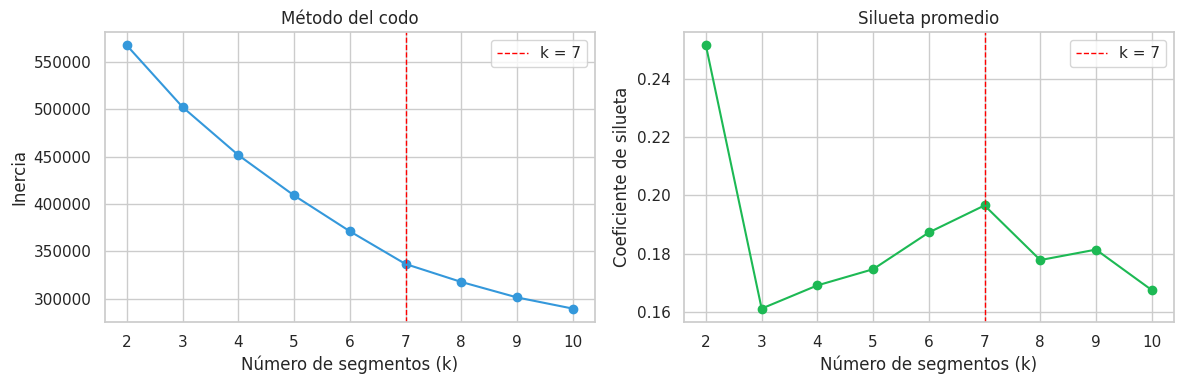

In [39]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

# Para cada k se ajusta K-Means (10 inicializaciones) y se mide inercia y silueta.
# La silueta compara cada canción con su segmento y con el más cercano; se calcula sobre
# una muestra de 15.000 canciones porque con 79.419 el cálculo exacto es muy lento.
resultados = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    silueta = silhouette_score(X_cluster, km_k.labels_, sample_size=15000, random_state=RANDOM_STATE)
    resultados.append({"k": k, "inercia": km_k.inertia_, "silueta": silueta})

tabla_k = pd.DataFrame(resultados).set_index("k")
tabla_k["reducción de inercia"] = -tabla_k["inercia"].pct_change()
display(tabla_k.style.format({"inercia": "{:,.0f}", "silueta": "{:.3f}", "reducción de inercia": "{:.1%}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tabla_k.index, tabla_k["inercia"], marker="o", color="#3498db")
ax[0].axvline(7, color="red", ls="--", lw=1, label="k = 7")
ax[0].set_xlabel("Número de segmentos (k)"); ax[0].set_ylabel("Inercia"); ax[0].set_title("Método del codo"); ax[0].legend()
ax[1].plot(tabla_k.index, tabla_k["silueta"], marker="o", color="#1DB954")
ax[1].axvline(7, color="red", ls="--", lw=1, label="k = 7")
ax[1].set_xlabel("Número de segmentos (k)"); ax[1].set_ylabel("Coeficiente de silueta"); ax[1].set_title("Silueta promedio"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG / "clu_01_codo_silueta.png", dpi=120); plt.show()

No hay un codo marcado: la inercia baja de forma gradual. Lo informativo es la reducción relativa: hasta k = 7 cada segmento adicional reduce la inercia entre 9% y 11%, y desde k = 8 baja a 5,6%, 5,1% y 3,9%. Es decir, el beneficio de agregar segmentos cae a partir de k = 7.

La silueta apunta en la misma dirección. Su máximo global es k = 2 (0,251), pero dividir el catálogo en solo dos grupos es demasiado grueso para definir estrategias distintas por tipo de repertorio, que es el objetivo de la sección 1.1. Entre las opciones con más de dos segmentos, **k = 7 tiene la mejor silueta (0,197)**, por lo que se elige.

Una advertencia: la silueta es baja en todos los casos (menos de 0,25), lo que indica que los segmentos **no están claramente separados**. Las canciones forman un continuo y los segmentos son regiones de ese continuo, no grupos aislados.

### 5.3 Modelo final y visualización de los segmentos

Se ajusta K-Means con k = 7. Como las etiquetas numéricas (0 a 6) son arbitrarias, cada segmento se nombra según su rasgo más distintivo mediante una regla, de modo que los nombres siguen siendo correctos aunque cambie el orden de las etiquetas. Para visualizarlos se proyectan las 9 variables a 2 dimensiones con PCA; los segmentos se calcularon con las 9 variables, la proyección es solo para dibujar.

,canciones,% del catálogo
segmento_nombre,,
Bailable y alegre,"23,826",30.0%
Intenso y rápido,"18,228",23.0%
Acústico y tranquilo,"15,923",20.0%
Instrumental enérgico,"9,458",11.9%
En vivo,"5,665",7.1%
Ambiental suave,"5,368",6.8%
Habla / comedia,951,1.2%


Varianza que conservan las 2 componentes: 47.4% (31.1% + 16.3%)

Peso de cada variable en las componentes:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
PC1,0.22,0.52,0.52,0.09,-0.44,-0.28,0.10,0.28,0.20
PC2,0.58,-0.26,-0.07,0.08,0.30,-0.31,-0.17,0.54,-0.27


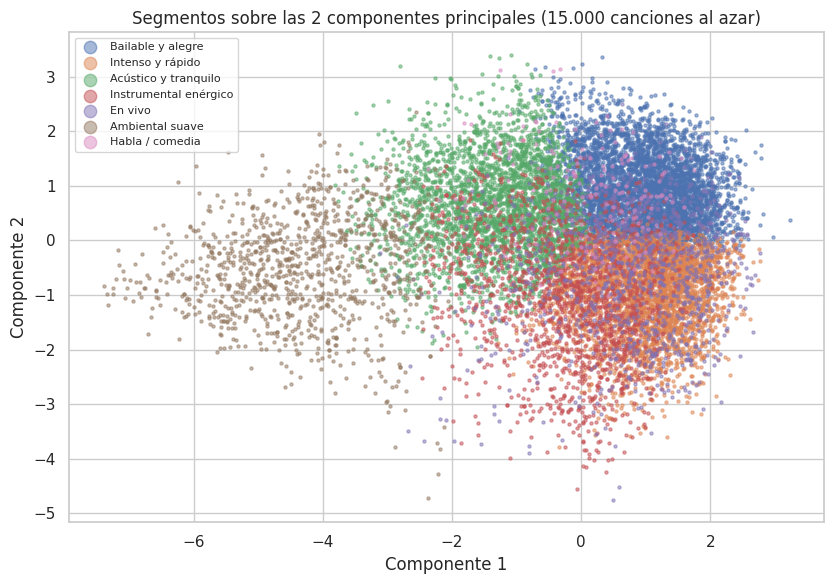

In [40]:
K = 7
km_final = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
df["segmento"] = km_final.labels_

# Perfil de cada segmento en unidades estandarizadas (0 = promedio del catálogo)
perfil_z = pd.DataFrame(X_cluster, columns=AUDIO).assign(segmento=km_final.labels_).groupby("segmento").mean()

def nombrar_segmentos(z):
    """Nombra cada segmento según su rasgo más distintivo, para no depender del orden arbitrario de las etiquetas."""
    libres, nombres = set(z.index), {}
    reglas = [("Habla / comedia", "speechiness", "max"), ("En vivo", "liveness", "max"),
              ("Ambiental suave", "loudness", "min"), ("Instrumental enérgico", "instrumentalness", "max"),
              ("Intenso y rápido", "energy", "max"), ("Bailable y alegre", "valence", "max")]
    for nombre, col, modo in reglas:
        serie = z.loc[sorted(libres), col]
        elegido = serie.idxmax() if modo == "max" else serie.idxmin()
        nombres[elegido] = nombre
        libres.remove(elegido)
    assert len(libres) == 1, "esta regla de nombres está pensada para k = 7"
    nombres[libres.pop()] = "Acústico y tranquilo"
    return nombres

NOMBRES = nombrar_segmentos(perfil_z)
df["segmento_nombre"] = df["segmento"].map(NOMBRES)
orden = df["segmento_nombre"].value_counts().index.tolist()

tamanos = df["segmento_nombre"].value_counts().to_frame("canciones")
tamanos["% del catálogo"] = tamanos["canciones"] / len(df)
display(tamanos.style.format({"canciones": "{:,}", "% del catálogo": "{:.1%}"}))

# Proyección a 2 dimensiones (PCA) solo para visualizar; los segmentos se calcularon con las 9 variables
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_cluster)
coords = pca.transform(X_cluster)
print(f"Varianza que conservan las 2 componentes: {pca.explained_variance_ratio_.sum():.1%} "
      f"({pca.explained_variance_ratio_[0]:.1%} + {pca.explained_variance_ratio_[1]:.1%})")
print("\nPeso de cada variable en las componentes:")
display(pd.DataFrame(pca.components_.T, index=AUDIO, columns=["PC1", "PC2"]).round(2).T)

muestra = np.random.RandomState(RANDOM_STATE).choice(len(df), 15000, replace=False)
fig, ax = plt.subplots(figsize=(8.5, 6))
for nombre in orden:
    m = muestra[df["segmento_nombre"].values[muestra] == nombre]
    ax.scatter(coords[m, 0], coords[m, 1], s=5, alpha=0.5, label=nombre)
ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
ax.set_title("Segmentos sobre las 2 componentes principales (15.000 canciones al azar)")
ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "clu_02_pca.png", dpi=120); plt.show()

Los siete segmentos van desde 23.826 canciones (30% del catálogo) hasta 951 (1,2%). Las dos primeras componentes conservan solo el 47,4% de la variación, así que el gráfico es una aproximación. Aun así permite leer el eje horizontal como **intensidad** (energía y volumen a la derecha, acústico a la izquierda) y el vertical como **ánimo bailable** (danceability y valence arriba).

Lo que más se nota es que los segmentos **se superponen mucho** y forman una nube continua. Solo Ambiental suave (a la izquierda) queda claramente aparte. Habla / comedia casi no se distingue en este plano porque su rasgo diferenciador (speechiness) pesa poco en estas dos componentes; se separa bien en las 9 variables, como se ve a continuación.

### 5.4 Perfil sonoro de cada segmento

El mapa de calor muestra cuánto se aleja cada segmento del promedio del catálogo en cada característica, medido en desviaciones estándar (rojo: por encima del promedio, azul: por debajo).

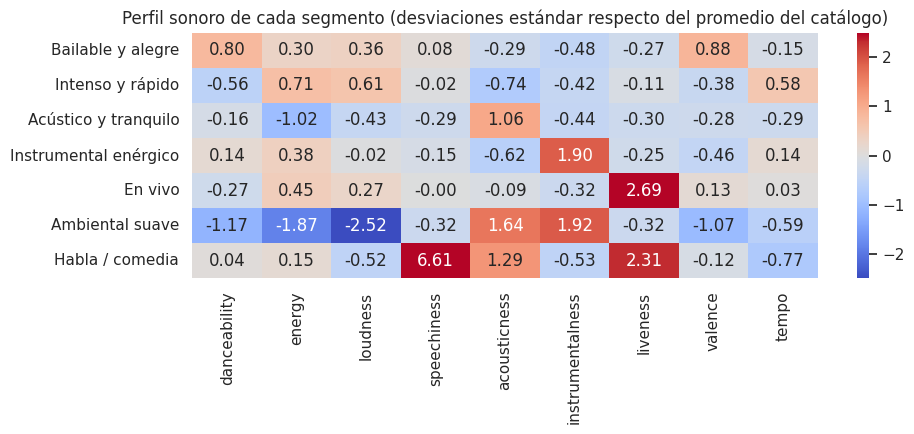

Valores originales (promedio por segmento):


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
segmento_nombre,,,,,,,,,
Bailable y alegre,0.70,0.72,-6.59,0.10,0.22,0.02,0.17,0.70,118.53
Intenso y rápido,0.47,0.82,-5.31,0.09,0.07,0.04,0.20,0.37,139.99
Acústico y tranquilo,0.54,0.39,-10.54,0.06,0.67,0.03,0.16,0.40,114.15
Instrumental enérgico,0.59,0.74,-8.51,0.07,0.11,0.80,0.17,0.35,126.94
En vivo,0.52,0.76,-7.02,0.09,0.29,0.07,0.75,0.50,123.73
Ambiental suave,0.36,0.17,-21.14,0.05,0.87,0.80,0.16,0.19,105.36
Habla / comedia,0.57,0.68,-11.02,0.85,0.75,0.01,0.68,0.44,99.91


In [41]:
perfil_z_ord = perfil_z.rename(index=NOMBRES).loc[orden]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(perfil_z_ord, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-2.5, vmax=2.5, ax=ax)
ax.set_ylabel(""); ax.set_title("Perfil sonoro de cada segmento (desviaciones estándar respecto del promedio del catálogo)")
plt.tight_layout(); plt.savefig(IMG / "clu_03_perfil.png", dpi=120); plt.show()

print("Valores originales (promedio por segmento):")
display(df.groupby("segmento_nombre")[AUDIO].mean().loc[orden].round(2))

Cada segmento se distingue por uno o dos rasgos dominantes, lo que lo hace fácil de interpretar:

- **Bailable y alegre (30%):** danceability +0,80 y valence +0,88; música bailable y de ánimo positivo.
- **Intenso y rápido (23%):** energy +0,71, loudness +0,61, tempo +0,58 (140 bpm en promedio) y acousticness −0,74; música rápida, fuerte y poco acústica.
- **Acústico y tranquilo (20%):** energy −1,02 y acousticness +1,06; música suave con instrumentos acústicos.
- **Instrumental enérgico (12%):** instrumentalness +1,90 (0,80 en promedio frente a menos de 0,1 en los segmentos con voz) y energía sobre el promedio.
- **En vivo (7%):** liveness +2,69; grabaciones con público.
- **Ambiental suave (7%):** el más extremo en volumen (loudness −2,52, unos −21 dB frente a −5 a −11 dB en los demás), con energy −1,87 y instrumentalness +1,92; música muy suave y sin voz.
- **Habla / comedia (1,2%):** speechiness +6,61 (0,85 en promedio frente a 0,05 a 0,10 en los demás); es palabra hablada, no música.

El mapa de calor satura en ±2,5 para que se vean los demás valores; las cifras de speechiness y loudness de estos dos últimos segmentos superan ese límite.

### 5.5 Segmentos, género y popularidad

Interesa saber si el sonido que separa a los segmentos sirve para distinguir canciones populares, y cómo se relacionan los segmentos con el género. Para separar ambos efectos se calcula también la popularidad **descontando el género**, es decir, cuántos puntos por encima o por debajo del promedio de su propio género está cada canción.

,canciones,popularidad,dif_vs_genero,pct_instrumental,pct_explicita,generos_principales
segmento_nombre,,,,,,
Bailable y alegre,"23,826",39.5,+0.19,1%,13%,"kids (3%), salsa (3%), j-dance (3%)"
Intenso y rápido,"18,228",38.5,+0.36,1%,11%,"heavy-metal (4%), metalcore (4%), grunge (4%)"
Acústico y tranquilo,"15,923",38.9,+0.46,2%,4%,"tango (5%), honky-tonk (5%), cantopop (4%)"
Instrumental enérgico,"9,458",28.6,-0.50,95%,4%,"minimal-techno (8%), detroit-techno (8%), study (6%)"
En vivo,"5,665",37.4,-1.18,7%,6%,"sertanejo (7%), pagode (6%), samba (6%)"
Ambiental suave,"5,368",33.6,-0.93,89%,0%,"new-age (13%), ambient (10%), sleep (9%)"
Habla / comedia,951,25.3,-1.98,0%,57%,"comedy (79%), show-tunes (3%), children (2%)"


Varianza de popularity explicada por el segmento: 4.2%   |   por el género: 44.5%
Géneros con al menos la mitad de sus canciones en un mismo segmento: 67 de 113
Porcentaje de un género en su segmento principal: mediana 52%, mínimo 31%, máximo 87%


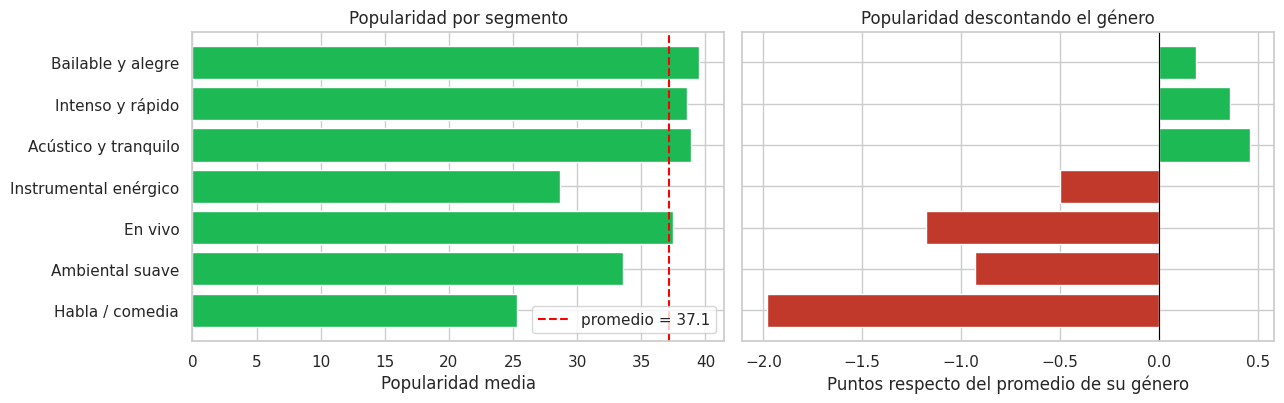

In [42]:
df["dif_vs_genero"] = df["popularity"] - df.groupby("genero_principal")["popularity"].transform("mean")

tabla_seg = (df.groupby("segmento_nombre")
               .agg(canciones=("popularity", "size"), popularidad=("popularity", "mean"),
                    dif_vs_genero=("dif_vs_genero", "mean"),
                    pct_instrumental=("es_instrumental", "mean"), pct_explicita=("explicit", "mean"))
               .loc[orden])
tabla_seg["generos_principales"] = df.groupby("segmento_nombre")["genero_principal"].apply(
    lambda s: ", ".join(f"{g} ({p:.0%})" for g, p in s.value_counts(normalize=True).head(3).items()))
display(tabla_seg.style.format({"canciones": "{:,}", "popularidad": "{:.1f}", "dif_vs_genero": "{:+.2f}",
                                "pct_instrumental": "{:.0%}", "pct_explicita": "{:.0%}"}))

eta_seg = varianza_explicada(df, "segmento")
eta_gen = varianza_explicada(df, "genero_principal")
print(f"Varianza de popularity explicada por el segmento: {eta_seg:.1%}   |   por el género: {eta_gen:.1%}")

# ¿Cada género se concentra en un segmento?
cruce = pd.crosstab(df["genero_principal"], df["segmento_nombre"], normalize="index")
concentracion = cruce.max(axis=1)
print(f"Géneros con al menos la mitad de sus canciones en un mismo segmento: {(concentracion >= 0.5).sum()} de {len(cruce)}")
print(f"Porcentaje de un género en su segmento principal: mediana {concentracion.median():.0%}, "
      f"mínimo {concentracion.min():.0%}, máximo {concentracion.max():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(tabla_seg.index[::-1], tabla_seg["popularidad"][::-1], color="#1DB954")
ax[0].axvline(df["popularity"].mean(), color="red", ls="--", label=f"promedio = {df['popularity'].mean():.1f}")
ax[0].set_xlabel("Popularidad media"); ax[0].set_title("Popularidad por segmento"); ax[0].legend(loc="lower right")
colores = ["#1DB954" if v >= 0 else "#c0392b" for v in tabla_seg["dif_vs_genero"][::-1]]
ax[1].barh(tabla_seg.index[::-1], tabla_seg["dif_vs_genero"][::-1], color=colores)
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set_xlabel("Puntos respecto del promedio de su género"); ax[1].set_title("Popularidad descontando el género")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(IMG / "clu_04_popularidad.png", dpi=120); plt.show()

Hay diferencias de popularidad entre segmentos (de 25,3 a 39,5 puntos), pero el segmento explica solo el **4,2%** de la varianza de popularity, frente al **44,5%** que explica el género. La razón es de composición: Instrumental enérgico (28,6), Ambiental suave (33,6) y Habla / comedia (25,3) quedan bajo el promedio de 37,1 porque los géneros que los forman (techno, ambient, comedy) son poco populares en general.

Al descontar el género (gráfico derecho), las diferencias se reducen a menos de 2 puntos: se alejan Habla / comedia (−1,98), En vivo (−1,18) y Ambiental suave (−0,93), y el resto queda dentro de ±0,5. Que En vivo tenga una popularidad media normal (37,4) pero baje 1,2 puntos dentro de su género indica que sus géneros (sertanejo, pagode, samba) son populares y que las canciones con perfil en vivo rinden algo menos que el resto de su género; los datos no permiten saber por qué. Todo esto es coherente con la sección 4: el audio aporta poco para distinguir una canción popular de otra del mismo género.

**Relación con el género.** Los segmentos reúnen familias de sonido: Ambiental suave se compone de new-age, ambient, sleep y piano; Instrumental enérgico, de techno y música para estudiar; Habla / comedia es 79% comedy. Los tres segmentos más grandes, en cambio, mezclan muchísimos géneros (ninguno supera el 5%). En total, 67 de los 113 géneros tienen al menos la mitad de sus canciones en un mismo segmento (mediana de 52%): sonido y género se relacionan, pero **no son lo mismo**, y un mismo género reparte sus canciones entre varios segmentos.

### 5.6 Estabilidad y calidad de la segmentación

Dos comprobaciones antes de confiar en los segmentos. La primera es la **estabilidad**: K-Means parte de un punto aleatorio, así que se repite con otras 5 semillas y se compara con el resultado final mediante el índice de Rand ajustado (1 significa segmentos idénticos). La segunda es la **silueta de cada segmento**, para ver cuáles están mejor definidos.

In [43]:
# 1) Estabilidad: ¿se obtienen los mismos segmentos con otras semillas aleatorias?
ari = []
for semilla in [1, 2, 3, 4, 5]:
    otra = KMeans(n_clusters=K, n_init=10, random_state=semilla).fit(X_cluster)
    ari.append(adjusted_rand_score(km_final.labels_, otra.labels_))
print("Índice de Rand ajustado frente a otras 5 semillas (1 = segmentos idénticos):", np.round(ari, 3))

# 2) Calidad por segmento: silueta de una muestra de 20.000 canciones
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_cluster), 20000, replace=False)
sil = silhouette_samples(X_cluster[idx], km_final.labels_[idx])
sil_seg = pd.Series(sil).groupby(df["segmento_nombre"].values[idx]).mean().loc[orden]
print(f"\nSilueta promedio de la muestra: {sil.mean():.3f}")
display(sil_seg.round(2).to_frame("silueta").T)

# 3) ¿Cuántas canciones están mal asignadas o en la frontera? (silueta de cada canción de la muestra)
print(f"\nCanciones con silueta negativa (más cerca de otro segmento que del propio): {(sil < 0).mean():.1%}")
print(f"Canciones con silueta entre 0 y 0,25 (cerca de la frontera):                {((sil >= 0) & (sil < 0.25)).mean():.1%}")
print(f"Canciones con silueta de 0,5 o más (bien asignadas):                        {(sil >= 0.5).mean():.1%}")
neg_seg = pd.Series(sil < 0).groupby(df["segmento_nombre"].values[idx]).mean().loc[orden]
display((neg_seg * 100).round(1).to_frame("% con silueta negativa").T)

Índice de Rand ajustado frente a otras 5 semillas (1 = segmentos idénticos): [0.995 0.998 1.    1.    0.999]

Silueta promedio de la muestra: 0.197


,Bailable y alegre,Intenso y rápido,Acústico y tranquilo,Instrumental enérgico,En vivo,Ambiental suave,Habla / comedia
silueta,0.18,0.19,0.21,0.16,0.18,0.28,0.53



Canciones con silueta negativa (más cerca de otro segmento que del propio): 3.2%
Canciones con silueta entre 0 y 0,25 (cerca de la frontera):                61.2%
Canciones con silueta de 0,5 o más (bien asignadas):                        0.9%


,Bailable y alegre,Intenso y rápido,Acústico y tranquilo,Instrumental enérgico,En vivo,Ambiental suave,Habla / comedia
% con silueta negativa,1.1,0.0,2.8,6.9,14.1,6.3,2.7


La segmentación es **muy estable**: con cualquier semilla el índice de Rand ajustado es de al menos 0,995, o sea que se obtienen prácticamente los mismos segmentos.

La **nitidez**, en cambio, es limitada. La silueta promedio (0,197) es baja y por segmento va de 0,16 a 0,28, con una sola excepción: Habla / comedia (0,53), que sí está bien separado. Ambiental suave (0,28) es el siguiente más definido, y el más difuso es Instrumental enérgico (0,16). En la práctica, una canción cercana al límite entre dos segmentos vecinos, por ejemplo Bailable y alegre e Intenso y rápido, podría pertenecer a cualquiera de los dos. Por eso conviene usar los segmentos como **etiquetas orientativas y no como fronteras estrictas**.

**Estabilidad y silueta miden cosas distintas.** El índice de Rand ajustado dice si K-Means *siempre corta igual*; la silueta dice si esos cortes *separan grupos reales*. Aquí el primero es casi 1 y la segunda ronda 0,2: los segmentos son **reproducibles pero difusos**. Siempre salen los mismos, pero sus fronteras son arbitrarias dentro de una nube continua. El porcentaje de canciones con silueta negativa que imprime la celda anterior indica cuántas están más cerca de otro segmento que del propio.

### 5.7 Segmentación de las situaciones de error del modelo

Los segmentos de la sección 5.3 describen cómo suena el catálogo, pero no ayudan a mejorar el modelo supervisado. Aquí se usa el clustering de otra forma: se agrupan las canciones según **cómo se equivoca el modelo**, para descubrir sin buscarlas a mano las situaciones donde su predicción no es confiable.

Se usan las predicciones fuera de muestra de la validación cruzada (el conjunto de prueba sigue sin usarse). Para cada canción se combinan sus características de audio, la predicción, el error (real − predicho: positivo si el modelo subestima, negativo si sobreestima) y el MAE de su género. Se estandariza y se aplica K-Means con k = 5, elegido para tener pocas situaciones interpretables (la silueta de la tabla es baja y casi igual para todos los k, por lo que no define el k). Las situaciones se ordenan de mayor a menor error (S1 es la peor).

k,3,4,5,6,7,8
silueta,0.124,0.127,0.123,0.125,0.135,0.139


,canciones,error_medio,mae,pop_real,pop_predicha,mae_genero,generos,% de las canciones,% del error total
situacion,,,,,,,,,
S1,"16,517",-5.1,12.6,45.3,50.4,12.4,"grunge, pop, psych-rock",26.0%,38.5%
S2,"11,475",+1.2,7.6,34.8,33.6,8.0,"new-age, ambient, opera",18.1%,16.3%
S3,"15,707",+3.2,7.0,32.2,29.1,7.2,"grindcore, black-metal, heavy-metal",24.7%,20.5%
S4,"19,057",+3.7,6.8,35.8,32.1,6.4,"kids, salsa, forro",30.0%,24.3%
S5,775,+0.5,2.8,25.4,24.9,4.6,"comedy, show-tunes, children",1.2%,0.4%


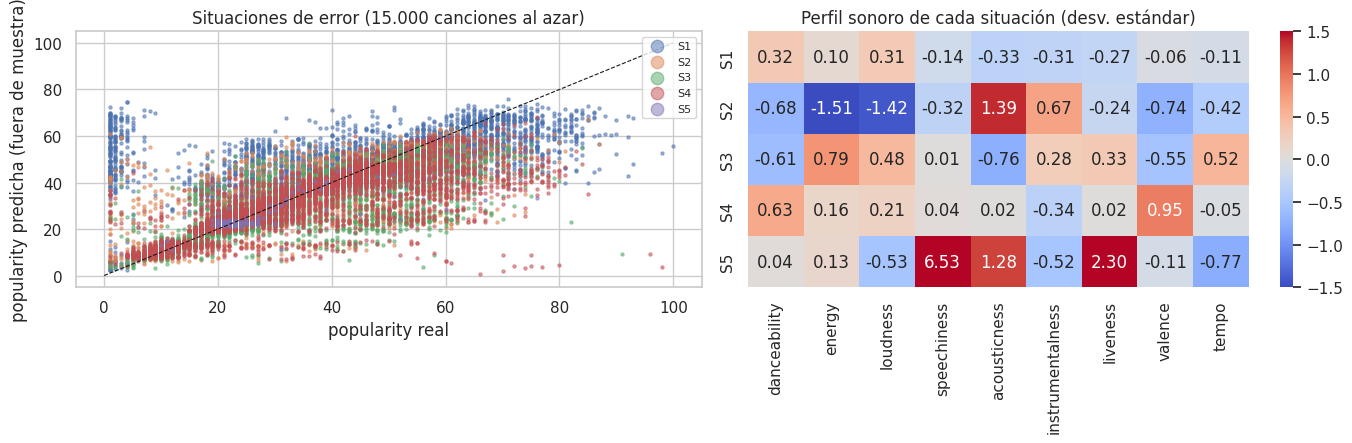

In [44]:
from sklearn.preprocessing import StandardScaler

# Errores del modelo final en canciones que no vio: predicciones fuera de muestra de la validación cruzada
# (el conjunto de prueba sigue sin usarse en esta sección).
ev = df.loc[X_train.index, AUDIO + ["genero_principal", "popularity"]].copy()
ev["pred"] = oof_hgb
ev["error"] = ev["popularity"] - ev["pred"]          # positivo: el modelo subestima; negativo: sobreestima
ev["mae_genero"] = ev.groupby("genero_principal")["error"].transform(lambda e: e.abs().mean())

COLS_ERROR = AUDIO + ["pred", "error", "mae_genero"]
Z = StandardScaler().fit_transform(ev[COLS_ERROR])

# Elección del número de situaciones con la silueta (muestra de 10.000 canciones)
filas = []
for k in range(3, 9):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    filas.append({"k": k, "silueta": silhouette_score(Z, etiquetas, sample_size=10000, random_state=RANDOM_STATE)})
display(pd.DataFrame(filas).set_index("k").T.round(3))

K_ERROR = 5
ev["situacion"] = KMeans(n_clusters=K_ERROR, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)

perfil_err = ev.groupby("situacion").agg(
    canciones=("error", "size"), error_medio=("error", "mean"), mae=("error", lambda e: e.abs().mean()),
    pop_real=("popularity", "mean"), pop_predicha=("pred", "mean"), mae_genero=("mae_genero", "mean"),
    generos=("genero_principal", lambda g: ", ".join(g.value_counts().head(3).index)))
perfil_err["% de las canciones"] = perfil_err["canciones"] / len(ev)
perfil_err["% del error total"] = ev["error"].abs().groupby(ev["situacion"]).sum() / ev["error"].abs().sum()
perfil_err = perfil_err.sort_values("mae", ascending=False)
ORDEN_ERR = {s: f"S{n}" for n, s in enumerate(perfil_err.index, start=1)}     # S1 = la de mayor error
ev["situacion_nombre"] = ev["situacion"].map(ORDEN_ERR)
perfil_err.index = perfil_err.index.map(ORDEN_ERR)

display(perfil_err.style.format({"canciones": "{:,}", "error_medio": "{:+.1f}", "mae": "{:.1f}", "pop_real": "{:.1f}",
                                 "pop_predicha": "{:.1f}", "mae_genero": "{:.1f}",
                                 "% de las canciones": "{:.1%}", "% del error total": "{:.1%}"}))

# Cómo suenan las canciones de cada situación (desviaciones estándar respecto del promedio del conjunto)
perfil_audio_err = ((ev.groupby("situacion_nombre")[AUDIO].mean() - ev[AUDIO].mean()) / ev[AUDIO].std()).loc[perfil_err.index]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
muestra_e = np.random.RandomState(RANDOM_STATE).choice(len(ev), 15000, replace=False)
for nombre in perfil_err.index:
    m = ev.iloc[muestra_e][ev.iloc[muestra_e]["situacion_nombre"] == nombre]
    ax[0].scatter(m["popularity"], m["pred"], s=5, alpha=0.5, label=nombre)
ax[0].plot([0, 100], [0, 100], "k--", lw=0.8)
ax[0].set_xlabel("popularity real"); ax[0].set_ylabel("popularity predicha (fuera de muestra)")
ax[0].set_title("Situaciones de error (15.000 canciones al azar)"); ax[0].legend(markerscale=4, fontsize=8)
sns.heatmap(perfil_audio_err, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1.5, vmax=1.5, ax=ax[1])
ax[1].set_ylabel(""); ax[1].set_title("Perfil sonoro de cada situación (desv. estándar)")
plt.tight_layout(); plt.savefig(IMG / "clu_05_situaciones_error.png", dpi=120); plt.show()

Las cinco situaciones, de mayor a menor error:

- **S1 (26% de las canciones, 38,5% del error total):** MAE de 12,6, casi el doble que las demás (entre 2,8 y 7,6). Es la situación donde no se debe confiar en la predicción. Su sonido es cercano al promedio (ninguna característica pasa de ±0,33 desviaciones), así que no la define el audio sino el género: sus géneros más frecuentes (grunge, pop, psych-rock) tienen un MAE de género de 12,4. El modelo sobreestima en promedio (error de −5,1: predice 50,4 contra 45,3 reales) y en el gráfico se ven los dos extremos: canciones de popularidad real casi nula con predicción de 60 a 70, y canciones de popularidad real alta con predicción de 50 a 70.
- **S2, S3 y S4 (73% de las canciones):** error moderado (6,8 a 7,6) y leve subestimación (+1,2 a +3,7). Se distinguen por el sonido: S2 es música suave y acústica (energy −1,51, acousticness +1,39; new-age, ambient, opera), S3 es música intensa y rápida (energy +0,79, acousticness −0,76, tempo +0,52; metal) y S4 es bailable y alegre (danceability +0,63, valence +0,95; kids, salsa, forró).
- **S5 (1,2%):** habla / comedia (speechiness +6,53). Error bajo (2,8) y casi sin peso en el total (0,4%).

Esto responde a *¿en qué tipo de canciones no puedo confiar en la predicción?*: en las de S1, que son géneros con popularidad muy dispersa. Para mejorar el modelo supervisado se podrían crear variables nuevas o entrenar un modelo distinto para esos géneros, o advertir al usuario cuando una canción cae en esa situación. Limitación: el error real no se conoce para una canción nueva, así que en producción habría que predecir la situación usando solo información previa al lanzamiento (audio, género y predicción).

Dos precauciones. Primero, la silueta es baja para todo k (0,12 a 0,14): igual que en la sección 5.3, las situaciones son regiones de un continuo y k = 5 se eligió por interpretabilidad. Segundo, el error es una de las variables usadas, por lo que las situaciones separan por error por construcción; lo que aporta información es lo que tienen en común las canciones de cada una (el género y el sonido).

### 5.8 Conclusiones de la sección 5

| Hallazgo | Implicancia |
|---|---|
| Siete segmentos interpretables y muy estables (índice de Rand ≥ 0,995) | Describen de forma confiable el catálogo según su perfil sonoro |
| Silueta baja (0,197): las canciones forman un continuo | Usarlos como etiquetas orientativas; solo Habla / comedia y Ambiental suave son claramente distintos |
| El segmento explica 4,2% de la varianza de popularity (género: 44,5%) y descontando el género la diferencia es de menos de 2 puntos | Los segmentos no sirven para predecir popularidad; confirma lo visto en la sección 4 |
| Los repertorios instrumentales y de comedia tienen menor popularidad media (25 a 34 puntos) | Conviene evaluarlos contra su propio segmento y género, no contra el catálogo completo, para no penalizarlos |
| Los segmentos cruzan los géneros (mediana de 52% en el segmento principal) | Aportan una vista complementaria al género para organizar el catálogo |
| Las situaciones de error (sección 5.7) muestran en qué canciones el modelo falla más | Sirven para advertir cuándo no confiar en la predicción y orientar mejoras del modelo |

**Recomendaciones de negocio.** Usar los segmentos para organizar y comparar repertorios homogéneos, por ejemplo en listas por contexto de uso: Ambiental suave e Instrumental enérgico parecen adecuados para escuchar mientras se estudia o se trabaja, por los géneros que los componen, aunque eso es una hipótesis que habría que validar con datos de uso que este dataset no tiene. Además, tratar Habla / comedia (951 canciones) como contenido aparte, porque no es música.

**Limitaciones.** El clustering usa solo audio, no incorpora datos de escucha, y la silueta baja indica fronteras difusas. Además, la visualización en 2 dimensiones conserva solo el 47% de la variación.

## 6. Evaluación y comparación de resultados

Hasta aquí el **conjunto de prueba** (20% de las canciones, 15.888) no se había usado: la elección de modelos e hiperparámetros se hizo solo con validación cruzada sobre el entrenamiento. Ahora se evalúa sobre esos datos la solución final elegida en la sección 4.12 (HistGradientBoosting con los hiperparámetros de la búsqueda ampliada, guardada en models/modelo_final.joblib), junto con la línea base y Ridge como referencia. Random Forest, Voting y Stacking no se evalúan aquí: se descartaron en la validación cruzada, y mirarlos en la prueba equivaldría a usarla para elegir el modelo:

1. **Revisar las métricas**, no solo en promedio sino también **por género**.
2. Mostrar una **matriz de confusión de 2×2** (realidad frente a predicción, con falsos positivos y falsos negativos), que en un problema de regresión se obtiene convirtiéndolo en binario: ¿está la canción en el 10% superior de su género?
3. Comprobar que el conjunto de prueba contiene **todos los géneros**, para no esconder un mal desempeño en los que falten (verificado con un assert en la primera celda).

Al final se contrastan los resultados con los cuatro KPIs de la sección 1.3. Siguiendo lo establecido en la sección 1.4, **las metas no se modifican**: se informa cuáles se cumplen y cuáles no, y por qué.

### 6.1 Métricas técnicas en el conjunto de prueba

In [50]:
import joblib

# Se cargan los modelos guardados en la sección 4.8. Recién ahora se usa el conjunto de prueba.
base_modelo  = MediaPorGenero().fit(X_train, y_train)
ridge_modelo = joblib.load(MODELS / "modelo_ridge.joblib")
hgb_modelo   = joblib.load(MODELS / "modelo_final.joblib")
nombre_final = (MODELS / "modelo_final_nombre.txt").read_text().strip()
assert nombre_final.startswith("HistGradientBoosting"), f"la solución final guardada es {nombre_final}, no HistGradientBoosting"
print(f"Solución final cargada: {nombre_final}")
# Verificación: el conjunto de prueba contiene todos los géneros
assert set(X_test["genero_principal"]) == set(df["genero_principal"]), "faltan géneros en la prueba"
print(f"Conjunto de prueba: {len(X_test):,} canciones, {X_test['genero_principal'].nunique()} géneros (todos representados)\n")

MODELOS = {"Media del género (base)": base_modelo, "Ridge": ridge_modelo, "HistGradientBoosting": hgb_modelo}
pred_test = {nombre: m.predict(X_test) for nombre, m in MODELOS.items()}

tabla_test = pd.DataFrame({nombre: metricas(y_test, p) for nombre, p in pred_test.items()}).T
cv_ref = pd.read_csv(DATA / "resultados_cv_modelos.csv", index_col=0)
cv_fin = pd.read_csv(DATA / "resultados_cv_seleccion_final.csv", index_col=0)
cv_ref.loc["HistGradientBoosting", ["MAE", "MAE desv."]] = cv_fin.loc[nombre_final, ["MAE", "MAE desv."]].values
tabla_test["MAE en validación cruzada"] = cv_ref["MAE"]
MAE_BASE_TEST = tabla_test.loc["Media del género (base)", "MAE"]
tabla_test["Mejora de MAE vs base"] = 1 - tabla_test["MAE"] / MAE_BASE_TEST
display(tabla_test.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                                 "MAE en validación cruzada": "{:.2f}", "Mejora de MAE vs base": "{:+.1%}"}))

# Incertidumbre de la mejora: intervalo de confianza por remuestreo (bootstrap) de las canciones de prueba
err_hgb  = np.abs(y_test.values - pred_test["HistGradientBoosting"])
err_base = np.abs(y_test.values - pred_test["Media del género (base)"])
rng = np.random.RandomState(RANDOM_STATE)
mejoras = [1 - err_hgb[i].mean() / err_base[i].mean()
           for i in (rng.randint(0, len(y_test), len(y_test)) for _ in range(1000))]
ic = np.percentile(mejoras, [2.5, 97.5])
print(f"\nMejora de HistGradientBoosting sobre la línea base: {1 - err_hgb.mean() / err_base.mean():.1%} "
      f"(intervalo de confianza del 95%: {ic[0]:.1%} a {ic[1]:.1%})")
print(f"MAE de HistGradientBoosting en entrenamiento: {mean_absolute_error(y_train, hgb_modelo.predict(X_train)):.2f} "
      f"| en prueba: {tabla_test.loc['HistGradientBoosting', 'MAE']:.2f}")

# ¿El resultado en prueba es coherente con el de validación cruzada? La conclusión se calcula, no se escribe a mano.
mae_prueba = tabla_test.loc["HistGradientBoosting", "MAE"]
mae_vc = tabla_test.loc["HistGradientBoosting", "MAE en validación cruzada"]
desv_vc = cv_ref.loc["HistGradientBoosting", "MAE desv."]
dif_vc = mae_prueba - mae_vc
print(f"\nMAE en prueba {mae_prueba:.2f} vs validación cruzada {mae_vc:.2f} (desv. entre pliegues {desv_vc:.2f}): "
      f"{'menor' if dif_vc < 0 else 'mayor'} en prueba por {abs(dif_vc):.2f} puntos, "
      f"{'dentro' if abs(dif_vc) <= desv_vc else 'fuera'} de la variación entre pliegues")

Solución final cargada: HistGradientBoosting (boosting)
Conjunto de prueba: 15,888 canciones, 113 géneros (todos representados)



,MAE,RMSE,R2,MAE en validación cruzada,Mejora de MAE vs base
Media del género (base),9.88,13.69,0.435,9.74,+0.0%
Ridge,9.85,13.63,0.440,9.68,+0.3%
HistGradientBoosting,8.55,13.51,0.450,8.44,+13.5%



Mejora de HistGradientBoosting sobre la línea base: 13.5% (intervalo de confianza del 95%: 12.6% a 14.2%)
MAE de HistGradientBoosting en entrenamiento: 6.61 | en prueba: 8.55

MAE en prueba 8.55 vs validación cruzada 8.44 (desv. entre pliegues 0.13): mayor en prueba por 0.11 puntos, dentro de la variación entre pliegues


En la prueba, HistGradientBoosting tiene un MAE de 8,55 puntos, un RMSE de 13,51 y un R² de 0,450, frente a 9,88, 13,69 y 0,435 de la línea base. Ridge queda casi igual que la línea base (MAE 9,85). El ranking es el mismo que en la validación cruzada. Para dimensionar el error: es un desvío típico de unos 9 puntos en una escala de 0 a 100, donde la desviación estándar de popularity es de unos 18.

HistGradientBoosting reduce el error un 13,5% respecto de la línea base, con un intervalo de confianza del 95% de 12,6% a 14,2%. Es una mejora moderada pero real: el intervalo queda lejos de cero, aunque también lejos de la meta de 20%. Ridge mejora solo un 0,3%. En cambio, el RMSE mejora poco (13,51 frente a 13,69, un 1,3%) y el R² apenas pasa de 0,435 a 0,450: al entrenar con error absoluto el modelo reduce el error típico, pero no el de las canciones más alejadas del promedio.

El MAE de prueba (8,55) es algo mayor que el de validación cruzada (8,44), por 0,11 puntos, una diferencia menor que la variación entre pliegues (0,13). El resultado en prueba es, por lo tanto, coherente con la validación cruzada, y ni la búsqueda ampliada de hiperparámetros (sección 4.9) ni la selección del modelo (sección 4.12) se sobreajustaron de forma apreciable a los pliegues. Sí existe una brecha entre entrenamiento (6,61) y prueba (8,55), de unos 1,9 puntos: es habitual en modelos de árboles y del mismo orden que la medida en la validación cruzada (1,67, sección 4.11).

### 6.2 Error por género y KPI de equidad

Un promedio global puede esconder que el modelo sirve para unos géneros y no para otros (sección 1.4). Por eso se calcula el MAE de cada uno de los 113 géneros en la prueba.

HistGradientBoosting - MAE por género: mínimo 1.58 (gospel), máximo 33.56 (rock), mediana 8.71
KPI de equidad (MAE máximo - MAE mínimo): 31.99 puntos   (meta: <= 8)
Géneros con MAE <= 10: 70 de 113 | con MAE <= 15: 98 de 113
Géneros en que el modelo mejora a la línea base: 100 de 113
Géneros con menos de 30 canciones en la prueba: 3
Correlación del MAE por género con la dispersión de popularity del género: 0.93
Correlación del MAE por género con el % de canciones con popularity <= 2: 0.70

Los 8 géneros con mayor error:


,HistGradientBoosting,Media del género (base),canciones en prueba,% con popularity <= 2
g,,,,
rock,33.6,37.0,36,33%
dance,32.8,36.5,103,28%
reggae,30.2,29.6,44,20%
alternative,26.5,28.7,21,27%
latin,23.1,28.9,55,53%
country,22.0,23.1,71,25%
hip-hop,20.5,22.0,122,12%
house,18.8,17.3,18,12%


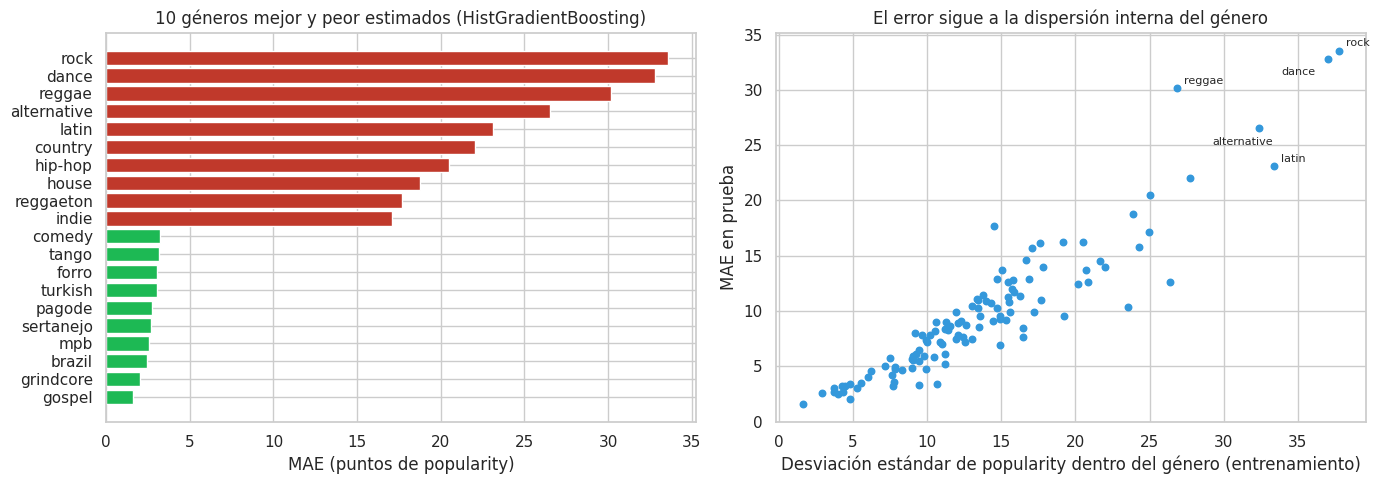

In [51]:
genero_test = X_test["genero_principal"].values

def mae_por_genero(pred):
    return pd.DataFrame({"g": genero_test, "error": np.abs(y_test.values - pred)}).groupby("g")["error"].mean()

por_gen = pd.DataFrame({nombre: mae_por_genero(p) for nombre, p in pred_test.items()})
por_gen["canciones en prueba"] = pd.Series(genero_test).value_counts()
por_gen["mejora vs base"] = 1 - por_gen["HistGradientBoosting"] / por_gen["Media del género (base)"]
por_gen["desv. de popularity en el género"] = X_train.assign(y=y_train).groupby("genero_principal")["y"].std()
por_gen["% con popularity <= 2"] = (df["popularity"] <= 2).groupby(df["genero_principal"]).mean()

mae_hgb = por_gen["HistGradientBoosting"]
rango_equidad = mae_hgb.max() - mae_hgb.min()
print(f"HistGradientBoosting - MAE por género: mínimo {mae_hgb.min():.2f} ({mae_hgb.idxmin()}), "
      f"máximo {mae_hgb.max():.2f} ({mae_hgb.idxmax()}), mediana {mae_hgb.median():.2f}")
print(f"KPI de equidad (MAE máximo - MAE mínimo): {rango_equidad:.2f} puntos   (meta: <= 8)")
print(f"Géneros con MAE <= 10: {(mae_hgb <= 10).sum()} de {len(mae_hgb)} | con MAE <= 15: {(mae_hgb <= 15).sum()} de {len(mae_hgb)}")
print(f"Géneros en que el modelo mejora a la línea base: {(por_gen['mejora vs base'] > 0).sum()} de {len(por_gen)}")
print(f"Géneros con menos de 30 canciones en la prueba: {(por_gen['canciones en prueba'] < 30).sum()}")
print(f"Correlación del MAE por género con la dispersión de popularity del género: "
      f"{mae_hgb.corr(por_gen['desv. de popularity en el género']):.2f}")
print(f"Correlación del MAE por género con el % de canciones con popularity <= 2: "
      f"{mae_hgb.corr(por_gen['% con popularity <= 2']):.2f}\n")

print("Los 8 géneros con mayor error:")
display(por_gen.sort_values("HistGradientBoosting", ascending=False).head(8)[
    ["HistGradientBoosting", "Media del género (base)", "canciones en prueba", "% con popularity <= 2"]
].style.format({"HistGradientBoosting": "{:.1f}", "Media del género (base)": "{:.1f}", "% con popularity <= 2": "{:.0%}"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
extremos = pd.concat([mae_hgb.sort_values().head(10), mae_hgb.sort_values().tail(10)])
ax[0].barh(extremos.index, extremos.values, color=["#1DB954"] * 10 + ["#c0392b"] * 10)
ax[0].set_xlabel("MAE (puntos de popularity)"); ax[0].set_title("10 géneros mejor y peor estimados (HistGradientBoosting)")
ax[1].scatter(por_gen["desv. de popularity en el género"], mae_hgb, s=22, color="#3498db")
for j, g in enumerate(mae_hgb.sort_values().tail(5).index):
    ax[1].annotate(g, (por_gen.loc[g, "desv. de popularity en el género"], mae_hgb[g]), fontsize=8,
                   xytext=(-34, -12) if j % 2 else (5, 3), textcoords="offset points")
ax[1].set_xlabel("Desviación estándar de popularity dentro del género (entrenamiento)"); ax[1].set_ylabel("MAE en prueba")
ax[1].set_title("El error sigue a la dispersión interna del género")
plt.tight_layout(); plt.savefig(IMG / "eval_01_error_por_genero.png", dpi=120); plt.show()

El KPI de equidad **no se cumple**: entre el género mejor estimado (gospel, MAE 1,58) y el peor (rock, 33,56) hay **32 puntos**, cuatro veces la meta de 8. Aun así, el panorama es menos malo de lo que sugiere ese número, porque el problema se concentra en pocos géneros: 70 de los 113 tienen un MAE de 10 o menos y 98 de 15 o menos. Los que más se alejan son rock (33,6), dance (32,8), reggae (30,2), alternative (26,5), latin (23,1) y country (22,0)-

La causa no es que el modelo trate peor a esos géneros, sino que **el valor a predecir es muy variable dentro de ellos**. El MAE por género tiene una correlación de 0,93 con la dispersión de popularity dentro del género y de 0,70 con el porcentaje de canciones con popularity ≤ 2, el hallazgo de la sección 2.5 (53% en latin, 33% en rock, 28% en dance). En esos géneros conviven canciones de popularidad casi nula con otras muy populares y de sonido parecido, y el audio no las distingue. De hecho, el modelo mejora a la línea base en 100 de los 113 géneros, aunque en rock la mejora es de solo 9%, en dance de 10% y en latin de 20%; reggae es uno de los trece géneros donde no mejora (30,2 frente a 29,6), y entre ellos hay varios de error ya muy bajo (gospel, brazil, mpb, forro y tango, con MAE de 1,6 a 3,2), donde la línea base ya es difícil de superar.

Una precaución: tres géneros tienen menos de 30 canciones en la prueba (alternative 21 y house 18, entre ellos), así que su MAE es más ruidoso. El patrón se repite con géneros más grandes como dance (103 canciones) y latin (55), por lo que la conclusión se mantiene.

### 6.3 KPI de precisión en priorización: Precision@10% y matriz de confusión

Dentro de cada género se **marca como prioritaria** el 10% de canciones con mayor valor predicho y se compara con el 10% que realmente fue más popular. Como dentro de un mismo género el modelo conoce el género de todas, el orden entre sus canciones depende solo de las características de audio. La **matriz de confusión** tiene cuatro casillas: verdaderos positivos (VP: marcada y realmente en el top), falsos positivos (FP: marcada pero no estaba en el top), falsos negativos (FN: no marcada pero sí estaba en el top) y verdaderos negativos (VN).

Proporción real de canciones en el 10% superior de su género: 11.3% (es algo más de 10% porque hay empates en popularity)



,VP,FP,FN,VN,Precision@10%,Recall
Media del género (base),176,"1,465","1,617","12,630",10.7%,9.8%
Ridge,242,"1,399","1,551","12,696",14.7%,13.5%
HistGradientBoosting,334,"1,307","1,459","12,788",20.4%,18.6%



HistGradientBoosting - Precision@10% promedio por género: 20.0% (meta: >= 40%)
Géneros que alcanzan la meta de 40%: 9 de 113 | mejor género: 61% (hardcore) | géneros con 0%: 9
Mejora sobre elegir al azar: 1.80 veces

Precisión según la fracción que se prioriza (HistGradientBoosting):


,Precision del modelo,Azar (tasa real)
5% superior,12.5%,6.0%
10% superior,20.4%,11.3%
20% superior,33.4%,21.9%


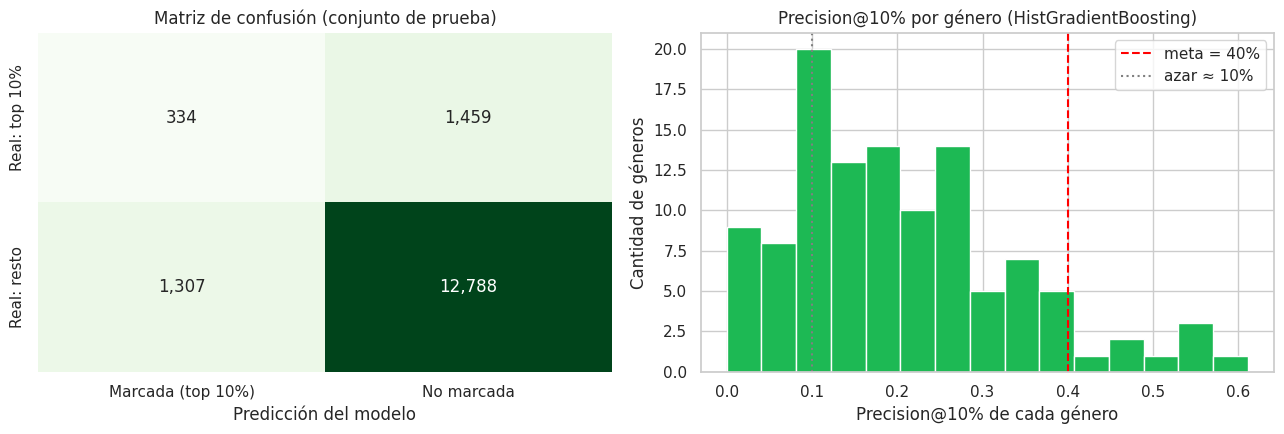

In [52]:
def marcar_top(pred, fraccion=0.10):
    """Dentro de cada género: 'real_top' = popularidad real en el 10% superior; 'pred_top' = el 10% con mayor valor predicho."""
    d = pd.DataFrame({"genero": genero_test, "real": y_test.values, "pred": pred})
    umbral = d.groupby("genero")["real"].transform(lambda s: s.quantile(1 - fraccion))
    d["real_top"] = d["real"] >= umbral
    n_genero = d.groupby("genero")["pred"].transform("size")
    puesto = d.groupby("genero")["pred"].rank(method="first", ascending=False)
    d["pred_top"] = puesto <= np.ceil(fraccion * n_genero)
    return d

def resumen_matriz(d):
    tp = int((d.real_top & d.pred_top).sum()); fp = int((~d.real_top & d.pred_top).sum())
    fn = int((d.real_top & ~d.pred_top).sum()); tn = int((~d.real_top & ~d.pred_top).sum())
    return {"VP": tp, "FP": fp, "FN": fn, "VN": tn, "Precision@10%": tp / (tp + fp), "Recall": tp / (tp + fn)}

marcas = {nombre: marcar_top(p) for nombre, p in pred_test.items()}
tabla_matriz = pd.DataFrame({nombre: resumen_matriz(d) for nombre, d in marcas.items()}).T
tasa_base = marcas["HistGradientBoosting"]["real_top"].mean()
print(f"Proporción real de canciones en el 10% superior de su género: {tasa_base:.1%} "
      f"(es algo más de 10% porque hay empates en popularity)\n")
display(tabla_matriz.style.format({"VP": "{:,.0f}", "FP": "{:,.0f}", "FN": "{:,.0f}", "VN": "{:,.0f}",
                                   "Precision@10%": "{:.1%}", "Recall": "{:.1%}"}))

# Precision@10% por género (KPI de la sección 1.3)
def precision_por_genero(d):
    t = d.assign(vp=d.real_top & d.pred_top).groupby("genero").agg(vp=("vp", "sum"), marcadas=("pred_top", "sum"))
    return t["vp"] / t["marcadas"]

prec_gen = {nombre: precision_por_genero(d) for nombre, d in marcas.items()}
prec_hgb = prec_gen["HistGradientBoosting"]
print(f"\nHistGradientBoosting - Precision@10% promedio por género: {prec_hgb.mean():.1%} (meta: >= 40%)")
print(f"Géneros que alcanzan la meta de 40%: {(prec_hgb >= 0.40).sum()} de {len(prec_hgb)} | mejor género: "
      f"{prec_hgb.max():.0%} ({prec_hgb.idxmax()}) | géneros con 0%: {(prec_hgb == 0).sum()}")
print(f"Mejora sobre elegir al azar: {resumen_matriz(marcas['HistGradientBoosting'])['Precision@10%'] / tasa_base:.2f} veces")

# Otras fracciones, para ver si la conclusión depende del 10%
filas = {}
for f in [0.05, 0.10, 0.20]:
    d = marcar_top(pred_test["HistGradientBoosting"], f)
    filas[f"{f:.0%} superior"] = {"Precision del modelo": resumen_matriz(d)["Precision@10%"], "Azar (tasa real)": d["real_top"].mean()}
print("\nPrecisión según la fracción que se prioriza (HistGradientBoosting):")
display(pd.DataFrame(filas).T.style.format("{:.1%}"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
m = marcas["HistGradientBoosting"]
cm = pd.crosstab(m["real_top"], m["pred_top"]).reindex(index=[True, False], columns=[True, False])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Greens", cbar=False, ax=ax[0],
            xticklabels=["Marcada (top 10%)", "No marcada"], yticklabels=["Real: top 10%", "Real: resto"])
ax[0].set_xlabel("Predicción del modelo"); ax[0].set_ylabel(""); ax[0].set_title("Matriz de confusión (conjunto de prueba)")
ax[1].hist(prec_hgb, bins=15, color="#1DB954")
ax[1].axvline(0.40, color="red", ls="--", label="meta = 40%"); ax[1].axvline(0.10, color="gray", ls=":", label="azar ≈ 10%")
ax[1].set_xlabel("Precision@10% de cada género"); ax[1].set_ylabel("Cantidad de géneros")
ax[1].set_title("Precision@10% por género (HistGradientBoosting)"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG / "eval_02_precision_matriz.png", dpi=120); plt.show()

El modelo marca 1.641 canciones (alrededor del 10% de la prueba) y solo 334 estaban realmente en el 10% superior de su género: una **precisión de 20,4%** (20,0% como promedio por género) y un *recall* de 18,6% La meta era 40%, así que el KPI **no se cumple**.

Para dimensionarlo: elegir al azar acertaría un 11,3% de las veces (es algo más de 10% por los empates en popularity), de modo que el modelo es **1,80 veces mejor que el azar**. La línea base (media del género) queda en 10,7%, es decir, como el azar, porque predice lo mismo para todas las canciones de un género y no puede ordenarlas. Ridge llega a 14,7%.

La matriz muestra el costo práctico: los falsos positivos (1.307) superan en casi 4 a 1 a los verdaderos positivos, o sea que **de cada 5 canciones que el modelo recomendaría impulsar, 4 no estaban en el top de su género**. Y los falsos negativos (1.459) indican que el modelo deja fuera al 81% de las canciones que sí eran las más populares. Por género, solo 9 de los 113 alcanzan el 40% (el mejor es hardcore, con 61%) y en 9 la precisión es 0%. La conclusión no depende de usar el 10%: con el 5% superior la precisión es de 12,5% (azar 6,0%) y con el 20% es de 33,4% (azar 21,9%).

### 6.4 ¿Dónde se equivoca el modelo?

Para entender por qué la precisión es baja se mira el error según la popularidad real de la canción.

,canciones,real_medio,predicho_medio,MAE
tramo,,,,
1-19,"2,646",11.6,22.0,11.3
20-39,"5,987",28.5,31.4,6.0
40-59,"5,288",48.8,43.8,7.7
60-79,"1,839",66.5,52.7,14.3
80-100,128,83.6,58.7,24.9


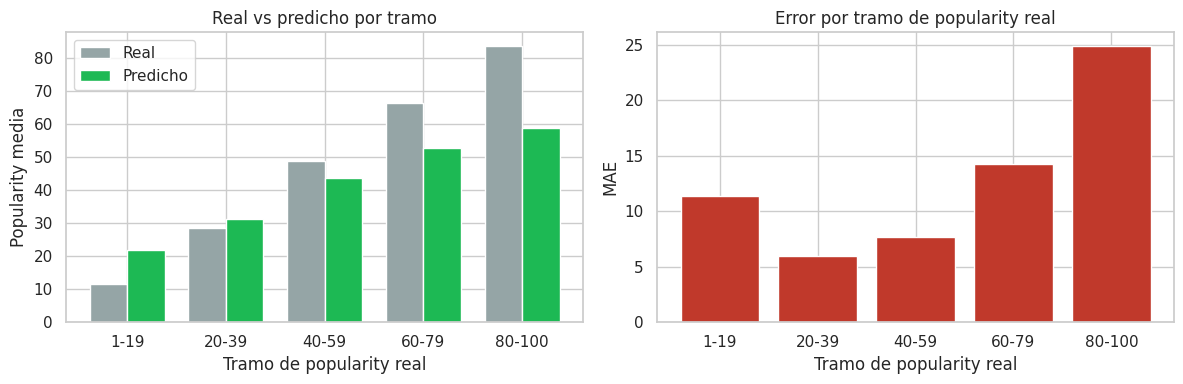

In [53]:
p_hgb = pred_test["HistGradientBoosting"]
tramo = pd.cut(y_test, [0, 20, 40, 60, 80, 101], right=False, labels=["1-19", "20-39", "40-59", "60-79", "80-100"])
por_tramo = (pd.DataFrame({"tramo": tramo.values, "real": y_test.values, "predicho": p_hgb,
                           "error": np.abs(y_test.values - p_hgb)})
               .groupby("tramo", observed=True).agg(canciones=("error", "size"), real_medio=("real", "mean"),
                                                    predicho_medio=("predicho", "mean"), MAE=("error", "mean")))
display(por_tramo.style.format({"canciones": "{:,}", "real_medio": "{:.1f}", "predicho_medio": "{:.1f}", "MAE": "{:.1f}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(por_tramo)); ancho = 0.38
ax[0].bar(x - ancho / 2, por_tramo["real_medio"], ancho, label="Real", color="#95a5a6")
ax[0].bar(x + ancho / 2, por_tramo["predicho_medio"], ancho, label="Predicho", color="#1DB954")
ax[0].set_xticks(x); ax[0].set_xticklabels(por_tramo.index); ax[0].set_xlabel("Tramo de popularity real")
ax[0].set_ylabel("Popularity media"); ax[0].set_title("Real vs predicho por tramo"); ax[0].legend()
ax[1].bar(por_tramo.index.astype(str), por_tramo["MAE"], color="#c0392b")
ax[1].set_xlabel("Tramo de popularity real"); ax[1].set_ylabel("MAE"); ax[1].set_title("Error por tramo de popularity real")
plt.tight_layout(); plt.savefig(IMG / "eval_03_error_por_tramo.png", dpi=120); plt.show()

El modelo **comprime sus predicciones hacia el centro** (regresión a la media). Las canciones de popularidad real entre 1 y 19 (media 11,6) reciben en promedio una predicción de 22,0; las de 60 a 79 (media 66,5) reciben 52,7, y las de 80 a 100 (media 83,6) reciben 58,7, con un error de 24,9 puntos. Es coherente con el gráfico de la sección 4.5 y con la baja precisión: **las canciones que más le interesan al negocio, las de popularidad más alta, son justamente las que peor estima**. Estas últimas son pocas (128, el 0,8% de la prueba), pero es el grupo donde el modelo debería ayudar más.

### 6.5 Resumen de los KPIs

In [54]:
# KPI de cobertura confiable: una canción está "cubierta" si el modelo entrega una predicción confiable para ella,
# es decir, si pertenece a un género donde el modelo (a) supera a la línea base y (b) tiene un MAE aceptable.
UMBRAL_MAE = 10   # puntos de popularity

def cobertura_confiable(mae_modelo, mae_base):
    """Devuelve la cantidad de géneros confiables y el % de canciones de prueba que pertenecen a ellos."""
    ok = (mae_modelo < mae_base) & (mae_modelo <= UMBRAL_MAE)
    return int(ok.sum()), pd.Series(genero_test).isin(ok.index[ok]).mean()

mae_gen_base = por_gen["Media del género (base)"]
mae_gen_cero = pd.Series(y_test.values).groupby(genero_test).mean()      # error de un modelo que siempre predice 0

filas = {}
for nombre, mg in [("Predecir siempre 0", mae_gen_cero), ("Media del género (base)", por_gen["Media del género (base)"]),
                   ("Ridge", por_gen["Ridge"]), ("HistGradientBoosting", por_gen["HistGradientBoosting"])]:
    n_ok, cob = cobertura_confiable(mg, mae_gen_base)
    filas[nombre] = {"géneros confiables": f"{n_ok} de {len(mg)}", "cobertura confiable": cob}
print(f"Cobertura confiable (género con MAE < línea base y MAE <= {UMBRAL_MAE}), conjunto de prueba:")
display(pd.DataFrame(filas).T.style.format({"cobertura confiable": "{:.1%}"}))
print(f"Dato de contexto: {cobertura_datos:.1%} de las canciones únicas del catálogo es modelable (no es el KPI)\n")

n_gen_ok, cobertura_util = cobertura_confiable(por_gen["HistGradientBoosting"], mae_gen_base)

prec_global = resumen_matriz(marcas["HistGradientBoosting"])["Precision@10%"]
kpis = pd.DataFrame([
    ["Precisión en priorización", "Precision@10% por género", "≥ 40%", f"{prec_hgb.mean():.1%} promedio por género ({prec_global:.1%} global)", prec_hgb.mean() >= 0.40],
    ["Reducción del error de estimación", "MAE vs línea base", "≥ 20% de mejora", f"{1 - err_hgb.mean() / err_base.mean():.1%} (MAE {err_hgb.mean():.2f} vs {err_base.mean():.2f})", (1 - err_hgb.mean() / err_base.mean()) >= 0.20],
    ["Cobertura confiable del catálogo", f"% de canciones de prueba en géneros donde el modelo supera a la línea base y MAE ≤ {UMBRAL_MAE}", "≥ 85%", f"{cobertura_util:.1%} ({n_gen_ok} de {len(por_gen)} géneros)", cobertura_util >= 0.85],
    ["Equidad entre géneros", "MAE máximo - MAE mínimo", "≤ 8 puntos", f"{rango_equidad:.1f} puntos", rango_equidad <= 8],
], columns=["KPI", "Cómo se mide", "Meta", "Resultado", "¿Se cumple?"])
kpis["¿Se cumple?"] = kpis["¿Se cumple?"].map({True: "Sí", False: "No"})
display(kpis.style.hide(axis="index"))

Cobertura confiable (género con MAE < línea base y MAE <= 10), conjunto de prueba:


,géneros confiables,cobertura confiable
Predecir siempre 0,0 de 113,0.0%
Media del género (base),0 de 113,0.0%
Ridge,24 de 113,25.7%
HistGradientBoosting,59 de 113,58.3%


Dato de contexto: 89.5% de las canciones únicas del catálogo es modelable (no es el KPI)



KPI,Cómo se mide,Meta,Resultado,¿Se cumple?
Precisión en priorización,Precision@10% por género,≥ 40%,20.0% promedio por género (20.4% global),No
Reducción del error de estimación,MAE vs línea base,≥ 20% de mejora,13.5% (MAE 8.55 vs 9.88),No
Cobertura confiable del catálogo,% de canciones de prueba en géneros donde el modelo supera a la línea base y MAE ≤ 10,≥ 85%,58.3% (59 de 113 géneros),No
Equidad entre géneros,MAE máximo - MAE mínimo,≤ 8 puntos,32.0 puntos,No


De los cuatro KPIs **no se cumple ninguno**: la reducción del error es de 13,5% frente a una meta de 20%, la precisión en priorización es de 20,0% frente a 40%, la cobertura confiable es de 58,3% frente a 85% (59 de los 113 géneros) y la diferencia de error entre géneros es de 32,0 puntos frente a un máximo de 8. La tabla de control muestra que la cobertura confiable sí depende del modelo: es 0% para un modelo que siempre predice 0 y para la línea base, 25,7% para Ridge y 58,3% para HistGradientBoosting. Con el modelo de la búsqueda de 4.4 la cobertura era algo mayor (62,6%, 63 géneros) aunque el MAE global era peor: seis géneros salen de la cobertura con el modelo final (brazil, forro, funk, malay, mpb y tango) y dos entran (classical y show-tunes). Los seis que salen son géneros de error bajo donde el modelo queda casi igual que la línea base (de 0,00 a 0,20 puntos peor), de modo que la diferencia refleja la sensibilidad del umbral más que un deterioro del modelo. El 89,5% de canciones modelables se conserva solo como dato de contexto.

### 6.6 Por qué no se cumplen las metas

Las causas aparecen en el análisis de las secciones anteriores y se confirman aquí:

1. **El audio explica poco de la popularidad.** Al quitar el género el modelo pierde buena parte de su capacidad y en la importancia por permutación el género pesa mucho más que cualquier otra variable (sección 4.6). El modelo es, en esencia, la popularidad típica del género refinada con el audio.
2. **Hay géneros con una dispersión interna enorme** (rock, dance, latin), donde la popularidad de canciones parecidas va de casi 0 a muy alta. Eso hace imposible cumplir el KPI de equidad con estos datos, sin importar el modelo.
3. **El modelo regresa a la media** y no identifica los extremos (sección 6.4), que es justo lo que mide Precision@10%.
4. **La línea base ya es exigente.** Predecir la media del género ya recorta el error cerca de un 35% frente a la media global (sección 1.4), por lo que mejorarla otro 20% solo con características de audio exigía más información de la disponible. Variables que probablemente influyen en la popularidad, como el artista, la promoción o la fecha de lanzamiento, no están en el dataset o se excluyeron a propósito (artists, en la sección 3.1).
5. **Más optimización o más modelos no cambian el panorama.** La búsqueda ampliada de hiperparámetros mejoró el MAE solo un 1,5% (sección 4.9), los ensambles no lograron mejorarlo (sección 4.10) y la curva de aprendizaje indica que harían falta más de 100.000 canciones adicionales para llegar a la meta (sección 4.11). El límite está en la información de entrada y no en el algoritmo.

### 6.7 Comparación de resultados y límites de la solución

| Modelo | Tipo | Resultados en la prueba | Lectura |
|---|---|---|---|
| Media del género | Línea base | MAE 9,88 · R² 0,435 · Precision@10% 10,7% | Referencia: equivale a elegir al azar para priorizar |
| Ridge | Supervisado (lineal) | MAE 9,85 · R² 0,440 · Precision@10% 14,7% | Casi no mejora a la línea base |
| HistGradientBoosting (solución final) | Supervisado (no lineal, *boosting*) | MAE 8,55 · R² 0,450 · Precision@10% 20,4% | **Mejor modelo**, pero no alcanza las metas |
| Random Forest, Voting y Stacking | Supervisado (*bagging* y ensambles) | No se evaluaron en la prueba. MAE en validación cruzada: 9,26 · 8,96 · 8,92 | Descartados en la sección 4.12: ninguno mejora al mejor modelo individual (8,44) |
| K-Means (k = 7) | No supervisado | Silueta 0,197 · estabilidad (Rand ajustado) ≥ 0,995 | Segmentos estables y fáciles de interpretar, pero difusos y casi sin relación con la popularidad (4,2% de la varianza) |

**Qué sí aporta la solución:** una mejora moderada pero estadísticamente sólida del error (13,5%), mejor ordenamiento que el azar dentro de un género (1,80 veces) y una descripción interpretable del catálogo mediante los segmentos.

**Límites de uso:**

- No debe usarse como único criterio para decidir inversión: de cada 5 canciones que recomienda impulsar, 4 no están entre las más populares de su género.
- Su error varía mucho entre géneros: en rock, dance, reggae y alternative es de 26 a 34 puntos, por lo que ahí sus estimaciones son poco confiables. Cualquier uso debe informar el error del género.
- No identifica los posibles éxitos de popularidad muy alta, que es el caso que más interesa al negocio.
- Es más útil como **complemento del criterio editorial**, para ordenar canciones dentro de un mismo género, que para comparar canciones de géneros distintos.

## 7. Sesgos, ética y privacidad

Este modelo se usaría para decidir **qué canciones se promocionan**, y esa decisión afecta a artistas reales: una estimación equivocada puede significar que una canción no reciba una oportunidad. Por eso esta sección revisa dónde pueden entrar sesgos, qué riesgos éticos tiene su uso, qué pasa con la privacidad y bajo qué condiciones se pueden usar los datos.

Se distingue entre lo que **se midió con los datos del proyecto** y lo que es un **riesgo identificado pero que este dataset no permite medir**, para no afirmar más de lo que se sabe.

### 7.1 Sesgos en los datos

| Fuente de sesgo | Evidencia en el proyecto | Posible efecto | Tratamiento |
|---|---|---|---|
| Muestra construida por género | El dataset tiene 1.000 canciones por género (114 géneros); no es una muestra proporcional del catálogo real | Los géneros pequeños pesan igual que los masivos y los promedios no representan a la plataforma completa | Partición estratificada por género y verificación de que los 113 géneros estén en entrenamiento y prueba (secciones 3.3 y 3.4) |
| popularity = 0 tratada como dato faltante | 9.313 canciones excluidas, concentradas en ciertos géneros (EP1) | El modelo no se pronuncia sobre ellas (cobertura de datos de 89,5%) y nunca vio ejemplos de popularidad nula auténtica, por lo que podría ser optimista con ese tipo de canción | Se declara como limitación y la cobertura confiable se mide como KPI (sección 6.5) |
| Valores 1 y 2 en popularity | 53% en latin, 33% en rock y 28% en dance (sección 2.5) | No se sabe si son canciones poco escuchadas o registros incompletos; en esos géneros el error es mayor | Se conservaron y el error se reporta por género |
| La popularidad es una foto de un momento | Según la documentación de la API de Spotify, el índice depende sobre todo de la cantidad de reproducciones y de cuán recientes son; el dataset no trae fecha de lanzamiento | Favorece lo que sonaba al recolectar los datos; las canciones antiguas o recién publicadas quedan en desventaja | No se puede tratar con estos datos; se recomienda una validación temporal (sección 8.4) |
| Género asignado por una regla | Una canción aparece en varios géneros y genero_principal se elige como el más específico (sección 1.5) | Como el género es el predictor dominante, cambiar la regla cambiaría qué canciones se comparan entre sí | La regla está documentada; no se evaluó un criterio alternativo |

### 7.2 Sesgos en los resultados: ¿el modelo sirve igual para todos los géneros?

El modelo no trata distinto a ningún género, pero **su error sí es muy distinto según el género**, y en la práctica eso equivale a que la herramienta sea confiable para unos repertorios y no para otros. En la prueba, el MAE de HistGradientBoosting va de **1,58 puntos (gospel) a 33,56 (rock)**, una diferencia de 32,0 puntos frente a la meta de 8 (sección 6.2).

| Género | MAE del modelo | MAE de la línea base | Canciones en prueba | % con popularity ≤ 2 |
|---|---|---|---|---|
| rock | 33,6 | 37,0 | 36 | 33% |
| dance | 32,8 | 36,5 | 103 | 28% |
| reggae | 30,2 | 29,6 | 44 | 20% |
| alternative | 26,5 | 28,7 | 21 | 27% |
| latin | 23,1 | 28,9 | 55 | 53% |

La mayoría de los géneros está en una situación razonable: 70 de los 113 tienen un MAE de 10 o menos, 98 de 15 o menos, y el modelo mejora a la línea base en 100. El problema se concentra en géneros donde conviven canciones de popularidad casi nula con otras muy populares y de sonido parecido (el MAE por género tiene una correlación de 0,93 con la dispersión de popularity dentro del género). En los cinco géneros de la tabla la mejora sobre la línea base va de 7,5% a 20%, salvo reggae, donde el modelo es algo peor (30,2 frente a 29,6). Los géneros con pocas canciones en la prueba (alternative con 21, rock con 36) tienen un MAE más ruidoso, pero el patrón se repite en géneros más grandes como dance.

Hay dos efectos adicionales que importan para la equidad:

- **El modelo premia el género, no la canción.** Como el género explica casi toda la capacidad predictiva (sin él el R² baja de forma marcada, sección 4.6), comparar canciones de géneros distintos favorecería a los géneros que ya son populares. Por eso Precision@10% se mide *dentro* de cada género y por eso se recomienda usar el modelo solo así (sección 8.3).
- **El modelo subestima a las canciones que más se destacan.** A las de popularidad real entre 80 y 100 (media 83,6) les predice en promedio 58,7, con un error de 24,9 puntos. Un uso automático dejaría fuera justo a las canciones que se salen del patrón de su género, que son las que podrían ser un descubrimiento.

### 7.3 Riesgos éticos del uso de la solución

**Círculo de retroalimentación.** Si el sello promociona lo que el modelo predice como popular, esas canciones recibirán más reproducciones y su popularidad subirá, lo que a su vez "confirmará" al modelo en el siguiente ciclo de datos. Esto concentraría la exposición en lo ya conocido y perjudicaría a artistas emergentes y a géneros pequeños. Es un mecanismo plausible, pero **no se pudo comprobar** con un dataset de una sola fecha.

**Decisión automatizada.** Con una precisión de 20,4% (de cada 5 canciones marcadas, 4 no estaban en el top de su género) el modelo no es lo bastante fiable para decidir solo. Debe usarse como apoyo al criterio editorial, con una persona que revise y pueda corregir.

**Exclusión de artists.** Se dejó fuera del modelo (sección 3.1) porque no generaliza a canciones de artistas nuevos. Tiene además una consecuencia ética positiva: el modelo no aprende a favorecer a artistas ya famosos. El costo es que probablemente es uno de los factores que más influyen en la popularidad y no está en el modelo, lo que ayuda a explicar su techo de desempeño (sección 6.6).

**Variables sensibles o con carga cultural.** explicit entra al modelo y no se auditó su efecto por subgrupo; su peso es pequeño en la importancia por permutación (sección 4.6), pero convendría revisarlo antes de un uso real. Por otra parte, danceability, valence o energy son medidas calculadas por algoritmos propios de Spotify, cuya calibración se desconoce, y no se puede descartar que describan peor la música de ciertas tradiciones. Esto es una hipótesis, no un hallazgo.

**Interpretación de los segmentos.** Los nombres de los 7 segmentos ("Bailable y alegre", "Acústico y tranquilo", etc.) describen el sonido promedio de cada grupo, no su identidad cultural. Los segmentos mezclan géneros muy distintos y uno de ellos (Habla / comedia) ni siquiera es música. Usarlos como etiquetas fijas sobre artistas o repertorios sería un error (silueta de 0,197: son fronteras difusas).

**Transparencia.** HistGradientBoosting es menos interpretable que un modelo lineal. Se compensó con la importancia por permutación y con el análisis con y sin género (sección 4.6), y cualquier predicción debería ir acompañada del error típico de su género.

### 7.4 Privacidad y datos personales

- **El dataset no contiene datos de oyentes.** Solo trae atributos de las canciones: no hay identificadores de usuarios, historiales de escucha ni ubicación. El proyecto, tal como está, no trata datos personales de personas que usan la plataforma.
- **Lo más cercano a un dato personal es el nombre del artista**, que es información pública y profesional. Esa columna no entra al modelo (sección 3.1). Si se publica el repositorio, conviene revisar qué archivos de datos se suben y publicar solo lo necesario.
- **Si se ampliara el proyecto con datos de escucha**, como se plantea como hipótesis en la sección 5.8 para validar las listas por contexto, **sí habría datos personales**. Se necesitaría una base legal o consentimiento, usar solo lo imprescindible y trabajar con datos agregados o anonimizados. También habría que evitar construir perfiles de personas: el clustering de este proyecto agrupa canciones, no oyentes.
- **Marco legal en Chile.** La Ley 21.719, que reemplaza a la Ley 19.628 y crea la Agencia de Protección de Datos Personales, fue publicada el 13 de diciembre de 2024 y fija su entrada en vigencia el 1 de diciembre de 2026. Existe un proyecto en trámite que propone aplazarla hasta el 1 de diciembre de 2027, por lo que antes de un uso real hay que confirmar la fecha vigente. Esto es información de contexto y no una asesoría legal.

### 7.5 Propiedad de los datos y condiciones de uso

El *Spotify Tracks Dataset* proviene de la API de Spotify. La Política para Desarrolladores de Spotify (https://developer.spotify.com/policy/) indica que no se debe usar la plataforma ni su contenido para **entrenar un modelo de aprendizaje automático o de IA**. Esto tiene dos consecuencias:

1. En este trabajo el uso es **académico**, sobre una copia pública del dataset, y se declara aquí de forma explícita.
2. Para una **implementación comercial** no se podría entrenar el modelo con datos obtenidos de esa API. Habría que usar datos propios del sello o de la distribuidora (por ejemplo, sus reproducciones y metadatos), o datos licenciados que permitan expresamente este uso. Conviene que el equipo lo confirme directamente con las condiciones vigentes de Spotify.

### 7.6 Resumen de riesgos y mitigaciones

| Riesgo | Estado | Mitigación o recomendación |
|---|---|---|
| Error muy distinto según el género (1,6 a 33,6 puntos) | **Medido** | Informar el error del género con cada predicción; no usar el modelo como filtro en rock, dance, reggae, alternative y latin |
| Comparar géneros distintos favorece a los ya populares | **Medido** | Usar el modelo solo para ordenar canciones dentro de un mismo género |
| El modelo no detecta los éxitos de popularidad muy alta | **Medido** | No usarlo para descartar canciones; mantener la revisión editorial |
| Datos faltantes (popularity = 0) y valores 1 y 2 ambiguos | Mitigado en parte | Cobertura confiable reportada; confirmar con el proveedor del dato qué significan |
| Círculo de retroalimentación sobre artistas emergentes | No medible con estos datos | Reservar un porcentaje de la promoción fuera del modelo y monitorear la diversidad de lo promocionado |
| Posible sesgo cultural de las características de audio | No medible con estos datos | Auditar por subgrupo con datos propios antes de un uso real |
| Condiciones de uso de los datos de Spotify | Identificado | Uso académico; en producción, datos propios o licenciados |
| Privacidad de oyentes | No aplica hoy | Si se agregan datos de escucha: base legal, datos agregados y minimización |

## 8. Conclusiones y recomendaciones

### 8.1 Conclusiones

La pregunta del proyecto era si un modelo de Machine Learning puede aportar un **filtro cuantitativo previo** para priorizar canciones a partir de sus características musicales y su género. La respuesta es **parcial**: el modelo aporta una mejora moderada pero real en la estimación, y no alcanza la precisión que se necesitaba para decidir por sí solo.

**Cumplimiento de los objetivos específicos**

| Objetivo (sección 1.2) | Resultado | Dónde |
|---|---|---|
| Resumir la comprensión y calidad de los datos de la EP1 y verificar los insumos | Cumplido: los archivos y la línea base se reproducen | Secciones 1.8 y 2 |
| Preparar los datos evitando la fuga de información | Cumplido: partición agrupada y estratificada, con verificaciones automáticas | Sección 3 |
| Construir y comparar dos modelos supervisados | Cumplido: Ridge y HistGradientBoosting frente a una línea base | Sección 4 |
| Optimizar los hiperparámetros y comparar técnicas de ensamble | Cumplido: búsquedas aleatorias para HistGradientBoosting (30 combinaciones) y Random Forest, y comparación de *bagging*, *boosting*, *voting* y *stacking*; los ensambles no mejoran al mejor modelo individual | Secciones 4.9 y 4.10 |
| Evaluar la generalización y seleccionar la solución óptima | Cumplido: brecha entre entrenamiento y validación, estabilidad por pliegue, curva de aprendizaje y regla del error estándar; confirmada en el conjunto de prueba | Secciones 4.11, 4.12 y 6 |
| Aplicar una técnica no supervisada | Cumplido: K-Means con 7 segmentos | Sección 5 |
| Evaluar por género y no solo en promedio | Cumplido, con matriz de confusión de 2×2 | Sección 6 |
| Traducir los resultados en recomendaciones y límites de uso | Cumplido | Secciones 6.7, 7 y 8 |

**KPIs de negocio** (las metas no se modificaron, tal como se estableció en la sección 1.4; solo se corrigió la definición de cobertura)

| KPI | Meta | Resultado | ¿Se cumple? |
|---|---|---|---|
| Reducción del error de estimación | ≥ 20% | 13,5% (MAE 8,55 frente a 9,88) | No |
| Precisión en priorización (Precision@10%) | ≥ 40% | 20,0% promedio por género (20,4% global) | No |
| Equidad entre géneros | ≤ 8 puntos | 32,0 puntos | No |
| Cobertura confiable del catálogo | ≥ 85% | 58,3% (59 de 113 géneros) | No |

**Hallazgos principales**

1. **El género explica casi todo.** Sin el género el MAE sube y el R² cae de forma marcada (sección 4.6); la media global da un MAE de 15,13. El modelo es, en esencia, la popularidad típica de cada género refinada con el audio.
2. **HistGradientBoosting es el mejor modelo**, con un MAE de 8,55 y un R² de 0,450 en la prueba. Reduce el error un 13,5% frente a la línea base (intervalo de confianza del 95%: 12,6% a 14,2%), por lo que la mejora es moderada pero estadísticamente sólida, y es coherente con la validación cruzada (8,44). Ridge mejora solo un 0,3% y su regularización no influye.
3. **Ordena mejor que el azar, pero no lo suficiente.** Dentro de cada género acierta un 20,4% de las canciones del 10% superior, 1,80 veces más que el azar (11,3%). Aun así, de cada 5 canciones que marca, 4 no estaban en el top, y deja fuera al 81% de las que sí estaban.
4. **No identifica los extremos.** Tiende a la media: a las canciones de popularidad real entre 80 y 100 les predice en promedio 58,7, que es justo el grupo que más interesa al negocio.
5. **La confiabilidad depende del género.** El error va de 1,6 (gospel) a 33,6 puntos (rock) y sigue a la dispersión interna de popularidad de cada género, un límite de los datos y no del algoritmo.
6. **El techo es de información, no de algoritmo.** Las seis mejores combinaciones de la búsqueda inicial dan un MAE entre 8,46 y 8,52, y la búsqueda ampliada de 30 combinaciones lo baja solo a 8,44 (1,5% menos que con los valores por defecto). Los ensambles tampoco ayudan: Stacking (8,92) y Voting (8,96) empeoran en los 5 pliegues, porque los errores de los modelos base están muy correlacionados (0,93 a 0,98), y la curva de aprendizaje indica que harían falta más de 100.000 canciones adicionales para llegar a la meta. Lo que falta son variables que probablemente influyen y no están en los datos: artista, promoción y fecha de lanzamiento.
7. **La solución elegida se sostiene por comparación y generaliza de forma estable.** HistGradientBoosting queda primero en validación cruzada (8,44) y ningún otro modelo entra en el margen de un error estándar (8,50). Su brecha entre entrenamiento y validación es de 1,67 puntos y los cinco pliegues dan resultados parecidos. Random Forest (9,26), Voting y Stacking quedan peor en MAE, aunque Stacking logra el mejor RMSE (13,05) y R² (0,482), y además son hasta 8 veces más lentos de ajustar.
8. **El clustering describe, pero no predice.** Los 7 segmentos son muy estables (índice de Rand ajustado ≥ 0,995) e interpretables, pero difusos (silueta de 0,197) y casi sin relación con la popularidad: explican el 4,2% de su varianza, frente al 44,5% del género.

### 8.2 Recomendaciones para el negocio

1. **Usar el modelo como complemento del criterio editorial, no como reemplazo.** Sirve para ordenar canciones *dentro de un mismo género*; no para comparar entre géneros ni para descartar canciones.
2. **Acompañar cada predicción con el error de su género.** En rock, dance, reggae y alternative el error típico es de 26 a 34 puntos y sus estimaciones no deberían usarse como filtro. En los géneros con MAE de 10 o menos (70 de 113) la estimación es mucho más útil.
3. **No usarlo para detectar posibles éxitos.** Como subestima a las canciones de popularidad muy alta, un filtro automático dejaría fuera justo a las más valiosas. Conviene mantener una vía de revisión humana para lo que el modelo califica bajo.
4. **Usar los segmentos para organizar y explorar el catálogo**, por ejemplo para armar listas por contexto de uso o comparar repertorios homogéneos, tratando Habla / comedia (951 canciones) como contenido aparte. Las listas para estudiar o trabajar son una hipótesis que habría que validar con datos de escucha.
5. **Reservar parte de la promoción fuera del modelo** y monitorear qué se promociona, para evitar que el sistema refuerce siempre lo ya conocido (sección 7.3).
6. **Antes de una implementación real, asegurar los datos:** usar datos propios o licenciados y no los de la API de Spotify (sección 7.5), y evaluar el cumplimiento de la normativa de datos personales si se agregan datos de escucha (sección 7.4).
7. **No invertir más esfuerzo en ensambles ni en afinar hiperparámetros con estos datos.** La búsqueda ampliada mejoró el MAE solo un 1,5% y los ensambles no lo mejoraron (secciones 4.9 y 4.10); el retorno está en agregar información, no en complejizar el modelo.

### 8.3 Cómo debe usarse y cómo no (resumen)

| Sí | No |
|---|---|
| Ordenar canciones dentro de un género | Comparar canciones de géneros distintos |
| Apoyar la decisión editorial con una referencia cuantitativa | Decidir inversión solo con el modelo |
| Informar el error del género con cada predicción | Entregar un número único sin margen de error |
| Describir el catálogo con los segmentos | Usar los segmentos para predecir popularidad o como etiquetas fijas |

### 8.4 Mejoras técnicas y trabajo futuro

| Mejora | Por qué |
|---|---|
| **Incorporar información que hoy falta**: historial del artista, fecha de lanzamiento, ubicación en listas, inversión en promoción | Es la principal vía para superar el techo que dejan los datos de audio y género (hallazgo 6) |
| **Validación temporal**: entrenar con canciones más antiguas y probar con las más recientes | El uso real es predecir canciones futuras, y la partición actual es aleatoria; hoy no se puede hacer porque no hay fecha |
| **Aclarar con el proveedor qué significan los valores 0, 1 y 2 de popularity** | Define si son datos faltantes o canciones poco escuchadas y cambia el tratamiento en latin, rock y dance |
| **Modelar la bimodalidad**: primero estimar si la canción cae en el grupo de popularidad casi nula y luego su nivel, o usar un clasificador directo del 10% superior | En géneros con dos picos, un solo promedio no describe bien los datos |
| **Entregar intervalos de predicción** (por ejemplo, regresión por cuantiles) en vez de un solo número | Permite que la decisión incorpore la incertidumbre de cada género |
| **Validar los segmentos con datos de escucha** | Es la única forma de comprobar si sirven para listas por contexto de uso |
| **Auditar el modelo por subgrupos** (por ejemplo, explicit y géneros de distintas tradiciones) | Cubre los sesgos que este dataset no permite medir (sección 7.6) |
| **Monitoreo después del despliegue**: reentrenar de forma periódica y vigilar cambios en el error por género | La popularidad cambia con el tiempo y el modelo guardado (models/) quedaría desactualizado |
| **Probar un ensamble entrenado con error absoluto**: Random Forest con criterio absoluto y un modelo de segundo nivel que minimice el error absoluto (por ejemplo, una regresión por la mediana) | El stacking de la sección 4.10 minimiza el error cuadrático y arrastra hacia el promedio al modelo que apunta a la mediana; esa explicación no se comprobó, y esta es la forma de saber si un ensamble podría mejorar el MAE |

### 8.5 Cierre

El proyecto entrega una solución completa y reproducible (datos, partición sin fuga, modelos supervisados optimizados y comparados con ensambles, un clustering y una evaluación por género), pero **no cumple ninguno de los cuatro KPIs**, y las causas están identificadas: con las características de audio y el género disponibles, gran parte de lo que hace que una canción sea más popular que otra de su mismo género no está en los datos. El resultado más valioso para el negocio es justamente ese diagnóstico: antes de invertir en modelos más complejos (los ensambles probados no mejoraron al mejor modelo individual) conviene invertir en **mejores datos**, y mientras tanto usar lo desarrollado como apoyo acotado y transparente, no como un sistema que decida por sí solo.